# F1 Podium Prediction – Milestone 1

**Team 28**

| Name | ID | Tutorial |
|---|---|---|
| Ali Abuelkheir | 58-3693 | T17 |
| Maria Awad | 58-5927 | T28 |
| Rodaina Elsawy | 58-16542 | T24 |
| Monica Samaan | 58-4467 | T18 |

For every driver in every race we predict: **will this driver finish on the podium (`positionOrder <= 3`)?** We only use what is known **after qualifying and before the race starts**. Results, points, status, laps, pit stops and post-race standings of the same race are leakage.

Dataset: Formula 1 World Championship (1950–2024), Kaggle / Ergast, 14 linked CSV tables.

**Contents**

- **Part 1 – Audit, cleaning and the modeling table**: sentinels, types, primary and foreign keys, EDA before and after cleaning, the duplicate rule, leakage-safe features, the split, and the saved table.
- **Part 2 – Data-engineering questions**: Q1 front row to podium per circuit, Q2 home advantage, Q3 mechanical retirements per constructor.
- **Part 3 – Modeling, experiments and explainability**: pre-processing, baseline, statistical models, shallow neural network, model comparison, feature-group ablation, pre-processing-order experiments, permutation importance, SHAP, LIME, and the inference function.

The notebook runs top to bottom with Run All. The paths are set in the next cell. On Kaggle they are found automatically: attach the dataset and press Run All.

In [1]:
import os
import glob
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'   # hide TensorFlow info messages

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score, precision_recall_curve
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

import keras
from keras import layers
import shap
from lime.lime_tabular import LimeTabularExplainer

pd.set_option('display.max_rows', 100)
sns.set_theme(style='whitegrid')

DATA_DIR = '../data/raw'        # raw CSVs, only read
OUT_DIR = '../data/processed'   # the modeling table is saved here

# on Kaggle: use the attached dataset folder that has results.csv
if os.path.exists('/kaggle/input'):
    DATA_DIR = os.path.dirname(glob.glob('/kaggle/input/**/results.csv', recursive=True)[0])
    OUT_DIR = '/kaggle/working'

DATA_DIR

C:\Users\LAP TREND\AppData\Local\Temp\claude\c--Users-LAP-TREND-Downloads-ACL-2\8de2acb1-260f-454d-a829-f8eb6989921c\scratchpad\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


'../data/raw'

# Part 1 – Audit, cleaning and the modeling table

Goal: turn the 14 raw F1 CSV files into **one clean table with one row per driver per race**, ready for modeling.

Each row answers: *will this driver finish on the podium in this race?* Every feature must be known **after qualifying and before the race starts**.

## 1. Load

The raw files are never changed. We clean the copies in memory. The paths are set in the first code cell of the notebook.

In [2]:
names = ['circuits', 'constructors', 'constructor_results', 'constructor_standings', 'drivers', 'driver_standings',
         'lap_times', 'pit_stops', 'qualifying', 'races', 'results', 'seasons', 'sprint_results', 'status']
tables = {name: pd.read_csv(DATA_DIR + '/' + name + '.csv') for name in names}

pd.Series({name: len(df) for name, df in tables.items()})

circuits                     77
constructors                212
constructor_results       12625
constructor_standings     13391
drivers                     861
driver_standings          34863
lap_times                589081
pit_stops                 11371
qualifying                10494
races                      1125
results                   26759
seasons                      75
sprint_results              360
status                      139
dtype: int64

## 2. Audit: sentinel check and key checks

### 2.1 Column names and text

In our copy, two tables have spaces around their column names and text values (`' raceId'` instead of `raceId`), so a merge would fail.

In [3]:
print(tables['constructor_standings'].columns.tolist())
print(tables['constructor_standings'].iloc[0].tolist())

['constructorStandingsId', ' raceId', ' constructorId', ' points', ' position', ' positionText', ' wins']
[np.int64(1), np.int64(18), np.int64(1), np.float64(14.0), np.int64(1), ' "1"         ', np.int64(1)]


We strip the spaces (and quotes). Where there are none, nothing changes.

In [4]:
for df in tables.values():
    df.columns = df.columns.str.strip()

tables['constructor_results']['status'] = tables['constructor_results']['status'].str.strip().str.strip('"')
tables['constructor_standings']['positionText'] = tables['constructor_standings']['positionText'].str.strip().str.strip('"')

print(tables['constructor_standings'].columns.tolist())
print(tables['constructor_standings'].iloc[0].tolist())

['constructorStandingsId', 'raceId', 'constructorId', 'points', 'position', 'positionText', 'wins']
[np.int64(1), np.int64(18), np.int64(1), np.float64(14.0), np.int64(1), '1', np.int64(1)]


Short names for the tables we use.

In [5]:
results = tables['results']
races = tables['races']
qualifying = tables['qualifying']
drivers = tables['drivers']
circuits = tables['circuits']
status = tables['status']
driver_standings = tables['driver_standings']
constructor_standings = tables['constructor_standings']

### 2.2 Sentinel check

A sentinel is a placeholder written where a value is missing. Here it is the text `\N`. Pandas does not see it as missing, so we count it in every column of every table.

In [6]:
rows = []
for name, df in tables.items():
    counts = (df == '\\N').sum()
    for col in counts[counts > 0].index:
        rows.append([name + '.' + col, counts[col], round(counts[col] / len(df), 3)])

sentinels = pd.DataFrame(rows, columns=['column', 'n_sentinel', 'share'])
sentinels

,column,n_sentinel,share
0,constructor_results.status,12608,0.999
1,drivers.number,802,0.931
2,drivers.code,757,0.879
3,qualifying.q1,156,0.015
4,qualifying.q2,4625,0.441
5,qualifying.q3,6819,0.650
6,races.time,731,0.650
7,races.fp1_date,1035,0.920
8,races.fp1_time,1057,0.940
9,races.fp2_date,1035,0.920


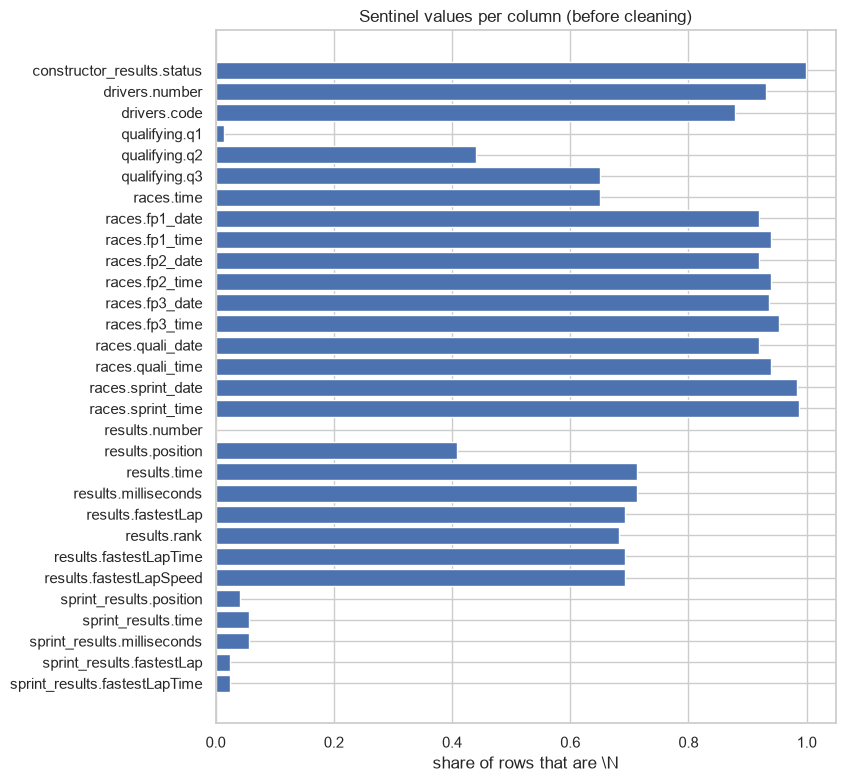

In [7]:
plt.figure(figsize=(8, 9))
plt.barh(sentinels['column'], sentinels['share'])
plt.xlabel('share of rows that are \\N')
plt.title('Sentinel values per column (before cleaning)')
plt.gca().invert_yaxis()
plt.show()

Six tables have sentinels. They make sense: `results.position` is `\N` when the driver was not classified, and `q2`/`q3` are `\N` for drivers knocked out earlier.

There is a second kind of missing value: cells that are just empty. Pandas already reads those as `NaN`.

In [8]:
qualifying.isna().sum()

qualifyId         0
raceId            0
driverId          0
constructorId     0
number            0
position          0
q1                0
q2               22
q3               46
dtype: int64

### 2.3 Primary keys

A primary key identifies one row. It must have no repeated and no empty value.

In [9]:
primary_keys = {
    'circuits': ['circuitId'], 'constructors': ['constructorId'], 'constructor_results': ['constructorResultsId'],
    'constructor_standings': ['constructorStandingsId'], 'drivers': ['driverId'],
    'driver_standings': ['driverStandingsId'], 'lap_times': ['raceId', 'driverId', 'lap'],
    'pit_stops': ['raceId', 'driverId', 'stop'], 'qualifying': ['qualifyId'], 'races': ['raceId'],
    'results': ['resultId'], 'seasons': ['year'], 'sprint_results': ['resultId'], 'status': ['statusId'],
}

rows = []
for name, key in primary_keys.items():
    rows.append([name, key, tables[name].duplicated(key).sum(), tables[name][key].isna().sum().sum()])

pd.DataFrame(rows, columns=['table', 'primary_key', 'duplicates', 'nulls'])

,table,primary_key,duplicates,nulls
0,circuits,[circuitId],0,0
1,constructors,[constructorId],0,0
2,constructor_results,[constructorResultsId],0,0
3,constructor_standings,[constructorStandingsId],0,0
4,drivers,[driverId],0,0
5,driver_standings,[driverStandingsId],0,0
6,lap_times,"[raceId, driverId, lap]",0,0
7,pit_stops,"[raceId, driverId, stop]",0,0
8,qualifying,[qualifyId],0,0
9,races,[raceId],0,0


### 2.4 Foreign keys

A foreign key points at another table. We count the values that do not exist in the parent table (orphans).

In [10]:
foreign_keys = [
    ('races', 'circuitId', 'circuits'), ('races', 'year', 'seasons'),
    ('results', 'raceId', 'races'), ('results', 'driverId', 'drivers'),
    ('results', 'constructorId', 'constructors'), ('results', 'statusId', 'status'),
    ('qualifying', 'raceId', 'races'), ('qualifying', 'driverId', 'drivers'),
    ('qualifying', 'constructorId', 'constructors'),
    ('sprint_results', 'raceId', 'races'), ('sprint_results', 'driverId', 'drivers'),
    ('sprint_results', 'constructorId', 'constructors'), ('sprint_results', 'statusId', 'status'),
    ('driver_standings', 'raceId', 'races'), ('driver_standings', 'driverId', 'drivers'),
    ('constructor_standings', 'raceId', 'races'), ('constructor_standings', 'constructorId', 'constructors'),
    ('constructor_results', 'raceId', 'races'), ('constructor_results', 'constructorId', 'constructors'),
    ('lap_times', 'raceId', 'races'), ('lap_times', 'driverId', 'drivers'),
    ('pit_stops', 'raceId', 'races'), ('pit_stops', 'driverId', 'drivers'),
]

rows = []
for child, col, parent in foreign_keys:
    rows.append([child, col, parent, (~tables[child][col].isin(tables[parent][col])).sum()])

pd.DataFrame(rows, columns=['table', 'column', 'points_to', 'orphans'])

,table,column,points_to,orphans
0,races,circuitId,circuits,0
1,races,year,seasons,0
2,results,raceId,races,0
3,results,driverId,drivers,0
4,results,constructorId,constructors,0
5,results,statusId,status,0
6,qualifying,raceId,races,0
7,qualifying,driverId,drivers,0
8,qualifying,constructorId,constructors,0
9,sprint_results,raceId,races,0


All 14 primary keys are unique and complete, and all 23 links have no orphans.

### 2.5 The modeling key

Our table needs one row per (`raceId`, `driverId`). Is that pair unique in `results`?

In [11]:
results.duplicated(['raceId', 'driverId']).sum()

np.int64(91)

No. Some drivers appear more than once in a race. We fix this in section 4.

## 3. EDA before cleaning

We add the year and race name to a copy of `results`, and keep two series to compare after cleaning.

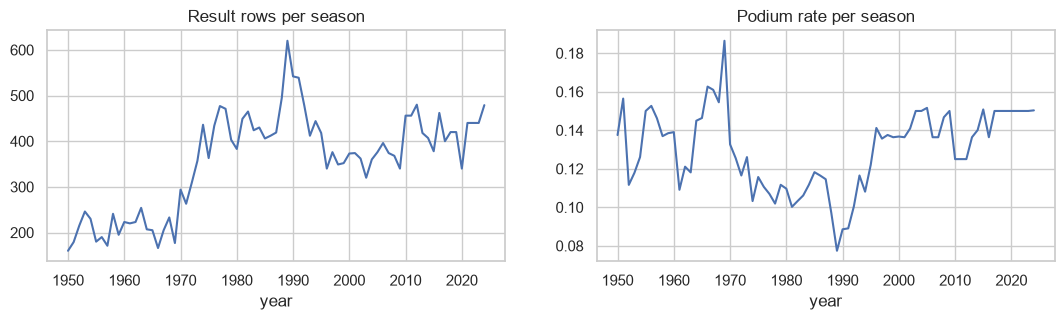

In [12]:
eda = results.merge(races[['raceId', 'year', 'name']], on='raceId')
eda['podium'] = eda['positionOrder'] <= 3

rows_before = eda.groupby('year').size()
podium_before = eda.groupby('year')['podium'].mean()

fig, ax = plt.subplots(1, 2, figsize=(13, 3))
rows_before.plot(ax=ax[0], title='Result rows per season')
podium_before.plot(ax=ax[1], title='Podium rate per season')
plt.show()

Rows per season are not steady: the late 1980s and early 1990s have many more entries. The podium rate drops in those years, because every race has about three podiums whatever the number of rows.

`positionText` says why a driver has no position.

In [13]:
eda['positionText'][~eda['positionText'].str.isdigit()].value_counts()

positionText
R    8897
F    1368
W     336
N     190
D     151
E       9
Name: count, dtype: int64

`R` = retired, `F` = failed to qualify, `W` = withdrew, `N` = not classified, `D` = disqualified, `E` = excluded. `F` and `W` drivers never started, which explains the extra rows.

rows with grid 0: 1638


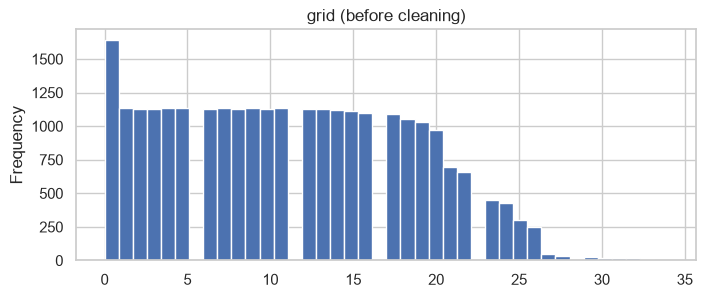

In [14]:
print('rows with grid 0:', (eda['grid'] == 0).sum())

eda['grid'].plot(kind='hist', bins=40, figsize=(8, 3), title='grid (before cleaning)')
plt.show()

`grid` has a spike at 0, which is not a real starting position. Next, how many races have qualifying data?

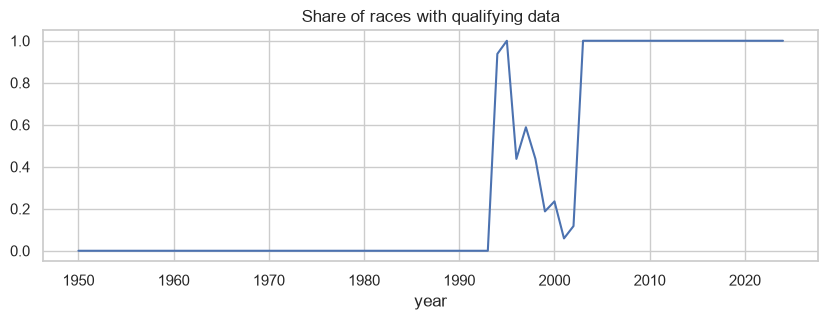

In [15]:
races['raceId'].isin(qualifying['raceId']).groupby(races['year']).mean().plot(figsize=(10, 3), title='Share of races with qualifying data')
plt.show()

Qualifying data starts in 1994, is patchy from 1996 to 2002, and is complete from 2003. This is the *qualifying-coverage drift* MS1 warns about.

Last, the Indianapolis 500, which was part of the championship from 1950 to 1960.

In [16]:
indy = eda[eda['name'] == 'Indianapolis 500']
others = eda[(eda['name'] != 'Indianapolis 500') & (eda['year'] <= 1960)]

print('rows:', len(indy), '| races:', indy['raceId'].nunique(), '| drivers:', indy['driverId'].nunique())
print('drivers who also raced elsewhere:', indy[indy['driverId'].isin(others['driverId'])]['driverId'].nunique())

rows: 405 | races: 11 | drivers: 107
drivers who also raced elsewhere: 3


Almost none of the Indianapolis drivers raced anywhere else. It is nearly a separate set of drivers.

## 4. Cleaning

### 4.1 Sentinel

Replace `\N` with a real missing value in every table, then count again.

In [17]:
for df in tables.values():
    df.replace('\\N', np.nan, inplace=True)

sum((df == '\\N').sum().sum() for df in tables.values())

np.int64(0)

### 4.2 Types

The columns that had `\N` are still text, and dates are text too.

In [18]:
num_cols = ['number', 'position', 'milliseconds', 'fastestLap', 'rank', 'fastestLapSpeed']
print(results[num_cols].dtypes.tolist(), races['date'].dtype, drivers['dob'].dtype)

[<StringDtype(storage='python', na_value=nan)>, <StringDtype(storage='python', na_value=nan)>, <StringDtype(storage='python', na_value=nan)>, <StringDtype(storage='python', na_value=nan)>, <StringDtype(storage='python', na_value=nan)>, <StringDtype(storage='python', na_value=nan)>] str str


In [19]:
results[num_cols] = results[num_cols].apply(pd.to_numeric)
races['date'] = pd.to_datetime(races['date'])
drivers['dob'] = pd.to_datetime(drivers['dob'])

print(results[num_cols].dtypes.tolist(), races['date'].dtype, drivers['dob'].dtype)

[dtype('float64'), dtype('float64'), dtype('float64'), dtype('float64'), dtype('float64'), dtype('float64')] datetime64[us] datetime64[us]


### 4.3 Lap times to seconds

Qualifying lap times are text like `1:26.572`. Adding `00:` in front makes it hours:minutes:seconds, which pandas can read as a duration.

The other duration columns are all post-race (`results.time`, `results.fastestLapTime`, `lap_times.time`, `pit_stops.duration`) and are never used. Race time, lap times and pit-stop times already have a numeric `milliseconds` column next to the text, so we leave the text copies as they are.

In [20]:
for col in ['q1', 'q2', 'q3']:
    qualifying[col + '_sec'] = pd.to_timedelta('00:' + qualifying[col]).dt.total_seconds()

qualifying[['q1', 'q1_sec', 'q2', 'q2_sec', 'q3', 'q3_sec']].describe().loc[['count', 'min', 'max']]

,q1_sec,q2_sec,q3_sec
count,10338.000,5847.000,3629.000
min,53.904,53.647,53.377
max,1002.640,132.470,129.776


The largest `q1_sec` is about 1000 seconds, more than 16 minutes. We look at the slowest laps.

In [21]:
qualifying.nlargest(4, 'q1_sec')[['raceId', 'driverId', 'position', 'q1', 'q1_sec']]

,raceId,driverId,position,q1,q1_sec
2567,255,87,24,16:42.640,1002.640
2853,267,113,26,2:33.885,153.885
2852,267,111,25,2:31.755,151.755
2851,267,104,24,2:30.931,150.931


One value is far from all the others. It is a data error, so we set it to missing. The other slow laps are possible (a wet session), so they stay.

In [22]:
qualifying.loc[qualifying['q1_sec'] > 600, 'q1_sec'] = np.nan

### 4.4 Stray spaces

One nationality has a space around it.

In [23]:
print((drivers['nationality'] != drivers['nationality'].str.strip()).sum())

drivers['nationality'] = drivers['nationality'].str.strip()

1


### 4.5 Duplicates: one driver, several rows in a race

rows involved: 176 | driver-race pairs: 85 | rows to drop: 91


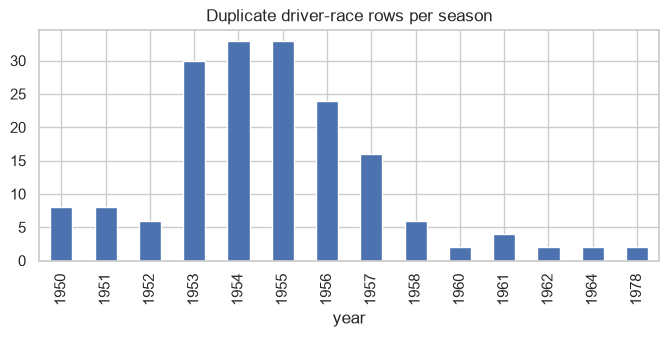

In [24]:
key = ['raceId', 'driverId']
dups = results[results.duplicated(key, keep=False)].merge(races[['raceId', 'year', 'name']], on='raceId')

print('rows involved:', len(dups), '| driver-race pairs:', len(dups.drop_duplicates(key)), '| rows to drop:', results.duplicated(key).sum())

dups.groupby('year').size().plot(kind='bar', figsize=(8, 3), title='Duplicate driver-race rows per season')
plt.show()

Almost all are from the 1950s and early 1960s. These are **shared drives**: a driver could take over a teammate's car during the race, so he has one row per car.

**Rule: keep the row with the best (lowest) `positionOrder`.** The row answers "did this driver finish on the podium?", and a podium in a shared car is an official podium for that driver.

Limitation: the kept row can carry the grid of the car the driver took over, not the car he started in. The data does not say which car he started in.

In [25]:
n_raw = len(results)
results = results.sort_values('positionOrder').drop_duplicates(key)
n_dedup = len(results)

print(n_raw, '->', n_dedup, '| duplicates left:', results.duplicated(key).sum())

26759 -> 26668 | duplicates left: 0


The opposite case also exists: **two drivers sharing one car**. Both get the car's finishing position, so a few races have more than three podium rows.

In [26]:
results[results['positionOrder'] <= 3].groupby('raceId').size().value_counts().sort_index()

3    1107
4      16
5       2
Name: count, dtype: int64

We keep these rows. Each driver appears once, and both were officially on the podium.

### 4.6 Remove rows that are not real prediction cases

`df` is the cleaned results with the race information and the status text. We remove:

- the **Indianapolis 500** (a separate set of drivers on a very different track),
- drivers who **never started**: `F` (failed to qualify) and `W` (withdrew). After qualifying we already know they are out.

In [27]:
race_cols = races[['raceId', 'year', 'round', 'date', 'name', 'circuitId']].rename(columns={'name': 'race_name'})
df = results.merge(race_cols, on='raceId').merge(status, on='statusId')

df = df[df['race_name'] != 'Indianapolis 500']
n_indy = len(df)

df = df[~df['positionText'].isin(['F', 'W'])]
n_fw = len(df)

print(n_dedup, '->', n_indy, '->', n_fw)

26668 -> 26287 -> 24586


### 4.7 Grid 0

What is left with `grid` 0, and did those drivers complete any lap?

In [28]:
zero = df[df['grid'] == 0]
pd.crosstab(zero['year'] >= 2015, zero['laps'] > 0, rownames=['2015 or later'], colnames=['did laps'])

did laps,False,True
2015 or later,,
False,14,0
True,1,72


In [29]:
zero[zero['laps'] == 0]['status'].value_counts()

status
Excluded        6
Disqualified    6
Battery         1
Underweight     1
Retired         1
Name: count, dtype: int64

Two groups:

- **0 laps**: excluded or disqualified before the race, or the car failed before the start. They did not start, so we remove them too.
- **Did laps**: **pit-lane starts**. The car starts behind the whole grid. Left as 0, the model would read it as better than pole, so we replace 0 with **last grid place in that race + 1**.

In [30]:
df = df[~((df['grid'] == 0) & (df['laps'] == 0))]
n_clean = len(df)

last_place = df.groupby('raceId')['grid'].transform('max')
df['grid'] = df['grid'].where(df['grid'] > 0, last_place + 1)

print(n_fw, '->', n_clean, '| grid 0 left:', (df['grid'] == 0).sum())

24586 -> 24571 | grid 0 left: 0


## 5. EDA after cleaning

raw                26759
duplicates         26668
Indianapolis       26287
F and W            24586
grid 0, no laps    24571
dtype: int64


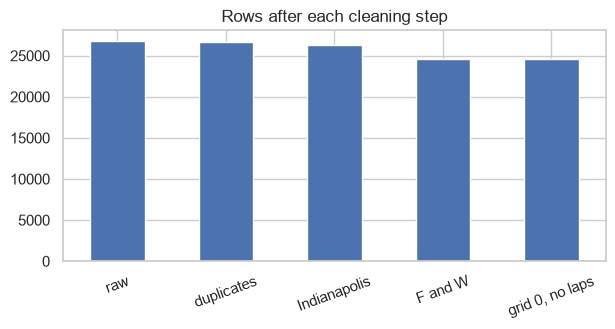

In [31]:
steps = pd.Series({'raw': n_raw, 'duplicates': n_dedup, 'Indianapolis': n_indy, 'F and W': n_fw, 'grid 0, no laps': n_clean})
print(steps)

steps.plot(kind='bar', figsize=(7, 3), title='Rows after each cleaning step')
plt.xticks(rotation=20)
plt.show()

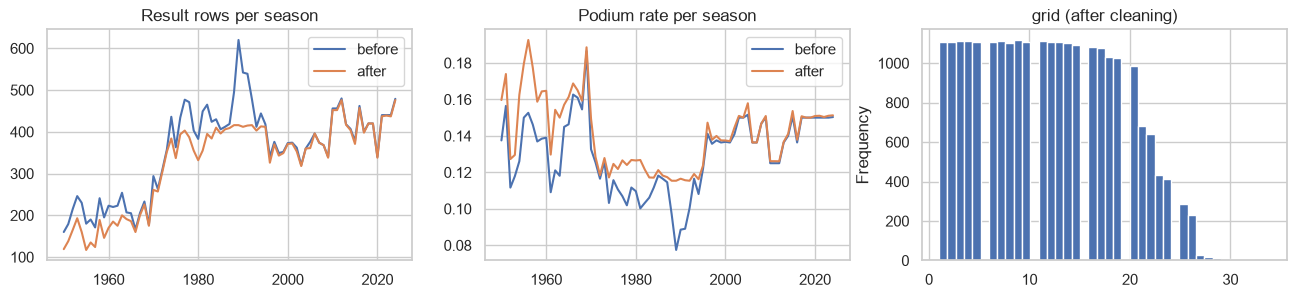

In [32]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3))
ax[0].plot(rows_before, label='before')
ax[0].plot(df.groupby('year').size(), label='after')
ax[0].set_title('Result rows per season')
ax[0].legend()
ax[1].plot(podium_before, label='before')
ax[1].plot((df['positionOrder'] <= 3).groupby(df['year']).mean(), label='after')
ax[1].set_title('Podium rate per season')
ax[1].legend()
df['grid'].plot(kind='hist', bins=40, ax=ax[2], title='grid (after cleaning)')
plt.show()

- The bump of the late 1980s and early 1990s is much smaller: most of those rows were drivers who never started.
- The seasons with the lowest podium rate move up, for the same reason.
- The spike at grid 0 is gone.

## 6. Target

`podium` is 1 when the driver finished in the top 3. `positionOrder` is filled for every row.

In [33]:
df['podium'] = (df['positionOrder'] <= 3).astype(int)

df['podium'].mean()

np.float64(0.13670587277685076)

About 1 row in 7 is a podium, so the classes are imbalanced. Before any "previous race" feature the rows must be in time order, and `raceId` is not:

In [34]:
races[races['raceId'] <= 2][['raceId', 'year', 'round', 'date']]

,raceId,year,round,date
0,1,2009,1,2009-03-29
1,2,2009,2,2009-04-05


`raceId` 1 is a 2009 race, so we sort by `date`.

In [35]:
df = df.sort_values(['date', 'positionOrder']).reset_index(drop=True)

## 7. Features

Features that use past results only look at **earlier** races.

We use **no sprint features**. Sprints only exist from 2021, so a sprint column would be empty for every training row (up to 2019), and the sprint format changed almost every year.

### 7.1 Grid

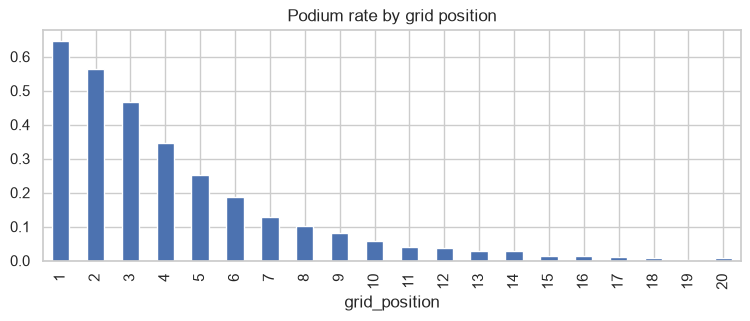

In [36]:
df = df.rename(columns={'grid': 'grid_position'})

df.groupby('grid_position')['podium'].mean().head(20).plot(kind='bar', figsize=(9, 3), title='Podium rate by grid position')
plt.show()

The podium rate falls quickly with grid position, so `grid_position` is a strong feature.

Fields had 20 cars in some years and more than 30 in others, so the same grid number does not always mean the same thing. `grid_position_relative` puts grid on a 0 to 1 scale inside each race. We keep both and compare them later.

In [37]:
df['front_row_start'] = (df['grid_position'] <= 2).astype(int)
df['grid_position_relative'] = df['grid_position'] / df.groupby('raceId')['grid_position'].transform('max')

### 7.2 Qualifying

The gap between a driver's best lap and the fastest lap (pole), as a percentage, so a short circuit and a long one can be compared.

In [38]:
qualifying['best_sec'] = qualifying[['q1_sec', 'q2_sec', 'q3_sec']].min(axis=1)
qualifying['pole_sec'] = qualifying.groupby('raceId')['best_sec'].transform('min')
qualifying['qualifying_gap_to_pole_percent'] = (qualifying['best_sec'] / qualifying['pole_sec'] - 1) * 100

quali_small = qualifying[['raceId', 'driverId', 'position', 'qualifying_gap_to_pole_percent']].rename(columns={'position': 'qualifying_position'})
df = df.merge(quali_small, on=['raceId', 'driverId'], how='left')

`has_qualifying_data` is set **per race**: 1 when the race has qualifying data, 0 when it has none, so all drivers of a race are treated the same.

Grid and qualifying position are almost the same number, so we keep only their **difference**: `grid_penalty_places` is positive when a driver starts further back than he qualified. Without a qualifying position it is 0.

In [39]:
df['has_qualifying_data'] = df['raceId'].isin(qualifying['raceId']).astype(int)
print('correlation grid position vs qualifying position:', round(df['grid_position'].corr(df['qualifying_position']), 3))

df['grid_penalty_places'] = (df['grid_position'] - df['qualifying_position']).fillna(0)

correlation grid position vs qualifying position: 0.97


Does the penalty add anything beyond grid? We compare drivers who start 7th to 10th.

In [40]:
mid = df[df['has_qualifying_data'].eq(1) & df['grid_position'].between(7, 10)]
mid.groupby(mid['grid_penalty_places'] >= 3)['podium'].agg(['mean', 'count'])

,mean,count
grid_penalty_places,,
False,0.057351,1918
True,0.217391,46


Drivers moved back 3 or more places reach the podium far more often than others starting from the same place. They are fast cars out of position, and `grid_position` alone cannot see that.

### 7.3 Driver form

Form is how a driver did **in his previous races**. The key step is `shift()`: it moves every value one race down, so a row only sees results from before it.

In [41]:
def past_mean(s, n):
    # mean of the previous n rows, not counting the current row
    return s.shift().rolling(n, min_periods=1).mean()

`Finished` and `+1 Lap`, `+2 Laps`, ... mean the driver reached the flag. Everything else is a retirement (`retired`).

In [42]:
df['retired'] = (~df['status'].str.contains('Finished|Lap')).astype(int)

by_driver = df.groupby('driverId')
df['driver_races_before'] = by_driver.cumcount()
df['driver_podium_rate_last_5_races'] = by_driver['podium'].transform(past_mean, n=5)
df['driver_average_finish_last_5_races'] = by_driver['positionOrder'].transform(past_mean, n=5)
df['driver_retirement_rate_last_10_races'] = by_driver['retired'].transform(past_mean, n=10)
df['driver_career_podium_rate'] = by_driver['podium'].transform(lambda s: s.shift().expanding().mean())
df['driver_podium_rate_at_circuit'] = df.groupby(['driverId', 'circuitId'])['podium'].transform(lambda s: s.shift().expanding().mean())

Check on one driver: the first race is empty, and each value only uses the rows above it.

In [43]:
df[df['driverId'] == 1][['date', 'race_name', 'podium', 'driver_races_before', 'driver_podium_rate_last_5_races', 'driver_career_podium_rate']].head(6)

,date,race_name,podium,driver_races_before,driver_podium_rate_last_5_races,driver_career_podium_rate
17099,2007-03-18,Australian Grand Prix,1,0,NaN,NaN
17120,2007-04-08,Malaysian Grand Prix,1,1,1.0,1.0
17142,2007-04-15,Bahrain Grand Prix,1,2,1.0,1.0
17164,2007-05-13,Spanish Grand Prix,1,3,1.0,1.0
17186,2007-05-27,Monaco Grand Prix,1,4,1.0,1.0
17207,2007-06-10,Canadian Grand Prix,1,5,1.0,1.0


### 7.4 Constructor form

We do not use the constructor's identity, only how the team performed recently. This also works for a team the model has never seen. A renamed team gets a new `constructorId`, so its history starts empty (a known limitation).

For mechanical retirements we need the statuses where a part of the car failed.

In [44]:
mechanical = [
    'Engine', 'Power Unit', 'ERS', 'Turbo', 'Battery', 'Power loss', 'Spark plugs', 'Exhaust', 'Gearbox',
    'Transmission', 'Clutch', 'Driveshaft', 'Drivetrain', 'Differential', 'Hydraulics', 'Electrical',
    'Electronics', 'Throttle', 'Brakes', 'Brake duct', 'Suspension', 'Steering', 'Wheel', 'Wheel nut',
    'Vibrations', 'Oil leak', 'Oil pressure', 'Water leak', 'Water pressure', 'Water pump', 'Radiator',
    'Overheating', 'Cooling system', 'Fuel pressure', 'Fuel leak', 'Fuel system', 'Fuel pump', 'Out of fuel',
    'Front wing', 'Rear wing', 'Undertray', 'Seat', 'Mechanical', 'Technical',
    # older statuses
    'Driver Seat', 'Broken wing', 'Heat shield fire', 'Wheel rim', 'Track rod', 'Engine fire', 'Engine misfire',
    'Pneumatics', 'Fire', 'Wheel bearing', 'Oil line', 'Launch control', 'Fuel', 'Ignition', 'Chassis',
    'Halfshaft', 'Crankshaft', 'Alternator', 'Safety belt', 'Oil pump', 'Injection', 'Distributor', 'CV joint',
    'Magneto', 'Supercharger', 'Fuel pipe', 'Oil pipe', 'Axle', 'Water pipe',
]
df['mechanical_retirement'] = df['status'].isin(mechanical).astype(int)

# the retirements we did NOT count as mechanical
df[(df['retired'] == 1) & (df['mechanical_retirement'] == 0)]['status'].value_counts().head(12)

status
Accident            981
Collision           850
Spun off            777
Not classified      172
Disqualified        140
Retired              97
Collision damage     60
Tyre                 54
Handling             53
Puncture             41
Physical             30
Withdrew             20
Name: count, dtype: int64

A team has two cars in a race. Shifting row by row would let one car see its teammate's result **from the same race**. So we first make one row per team per race, then look back.

In [45]:
con_race = df.groupby(['constructorId', 'date', 'raceId'])[['podium', 'positionOrder', 'mechanical_retirement']].mean().reset_index()

by_con = con_race.groupby('constructorId')
con_race['constructor_podium_rate_last_5_races'] = by_con['podium'].transform(past_mean, n=5)
con_race['constructor_average_finish_last_5_races'] = by_con['positionOrder'].transform(past_mean, n=5)
con_race['constructor_mechanical_retirement_rate_last_10_races'] = by_con['mechanical_retirement'].transform(past_mean, n=10)

con_cols = ['constructorId', 'raceId', 'constructor_podium_rate_last_5_races', 'constructor_average_finish_last_5_races', 'constructor_mechanical_retirement_rate_last_10_races']
df = df.merge(con_race[con_cols], on=['constructorId', 'raceId'], how='left')

Check: both cars of a team have the same value in a race, and it does not include that race.

In [46]:
df[(df['constructorId'] == 131) & (df['year'] == 2019)][['date', 'race_name', 'driverId', 'podium', 'constructor_podium_rate_last_5_races']].head(4)

,date,race_name,driverId,podium,constructor_podium_rate_last_5_races
22024,2019-03-17,Australian Grand Prix,822,1,0.5
22025,2019-03-17,Australian Grand Prix,1,1,0.5
22044,2019-03-31,Bahrain Grand Prix,1,1,0.5
22045,2019-03-31,Bahrain Grand Prix,822,1,0.5


### 7.5 Standings before the race

The standings tables give the points **after** each race, so the row of the same race would leak the result. We use the row of the **previous round** of the same season.

Points depend on the season's points system (a win was worth 8, 9, 10 or 25), so we divide by the leader's points.

In [47]:
races = races.sort_values(['year', 'round'])
races['prev_raceId'] = races.groupby('year')['raceId'].shift()
df = df.merge(races[['raceId', 'prev_raceId']], on='raceId', how='left')

driver_standings['points_share'] = driver_standings['points'] / driver_standings.groupby('raceId')['points'].transform('max')
drv_prev = driver_standings[['raceId', 'driverId', 'points_share', 'position', 'wins']]
drv_prev.columns = ['prev_raceId', 'driverId', 'driver_points_share_before_race', 'driver_standing_position_before_race', 'driver_season_wins_before_race']
df = df.merge(drv_prev, on=['prev_raceId', 'driverId'], how='left')

constructor_standings['points_share'] = constructor_standings['points'] / constructor_standings.groupby('raceId')['points'].transform('max')
con_prev = constructor_standings[['raceId', 'constructorId', 'points_share', 'position']]
con_prev.columns = ['prev_raceId', 'constructorId', 'constructor_points_share_before_race', 'constructor_standing_position_before_race']
df = df.merge(con_prev, on=['prev_raceId', 'constructorId'], how='left')

How many rows found no standings row?

In [48]:
print('drivers missing:', df['driver_points_share_before_race'].isna().sum(), '| of which round 1:', (df['driver_points_share_before_race'].isna() & df['round'].eq(1)).sum())

df['constructor_points_share_before_race'].isna().groupby(df['year'] // 10 * 10).mean().round(2)

drivers missing: 2889 | of which round 1: 1593


year
1950    0.80
1960    0.13
1970    0.08
1980    0.07
1990    0.09
2000    0.07
2010    0.05
2020    0.05
Name: constructor_points_share_before_race, dtype: float64

- **Round 1**: nobody has points yet.
- **Later rounds**: the table has no row for a driver or team that has not scored yet.
- **Constructors before 1958**: the constructors' championship did not exist, so there is no table.

In the first two cases the true value is 0 points and 0 wins. The **position** stays empty, because there is no honest rank. Before 1958 the constructor columns stay empty.

In [49]:
df['driver_points_share_before_race'] = df['driver_points_share_before_race'].fillna(0)
df['driver_season_wins_before_race'] = df['driver_season_wins_before_race'].fillna(0)

from_1958 = df['year'] >= 1958
df.loc[from_1958, 'constructor_points_share_before_race'] = df.loc[from_1958, 'constructor_points_share_before_race'].fillna(0)

### 7.6 Context

Driver age on race day, home race, and how far into the season the race is. The number of rounds comes from the season calendar, which is known before the season (one exception: the 2020 calendar was built during the season because of COVID, a small limitation).

For the home race, the nationality is a word like `British` and the circuit's country is a name like `UK`, so we need a mapping. It is the same one as in Part 2 (question 2). The circuits use both `USA` and `United States`, so we make them one.

In [50]:
nat_to_country = {
    'British': 'UK', 'American': 'USA', 'Italian': 'Italy', 'French': 'France', 'German': 'Germany',
    'Brazilian': 'Brazil', 'Argentine': 'Argentina', 'Argentinian': 'Argentina', 'Swiss': 'Switzerland',
    'Belgian': 'Belgium', 'South African': 'South Africa', 'Japanese': 'Japan', 'Australian': 'Australia',
    'Dutch': 'Netherlands', 'Spanish': 'Spain', 'Austrian': 'Austria', 'Canadian': 'Canada',
    'Swedish': 'Sweden', 'New Zealander': 'New Zealand', 'Finnish': 'Finland', 'Mexican': 'Mexico',
    'Irish': 'Ireland', 'Danish': 'Denmark', 'Portuguese': 'Portugal', 'Monegasque': 'Monaco',
    'Rhodesian': 'Rhodesia', 'Uruguayan': 'Uruguay', 'Russian': 'Russia', 'Colombian': 'Colombia',
    'Venezuelan': 'Venezuela', 'East German': 'Germany', 'Indian': 'India', 'Thai': 'Thailand',
    'Polish': 'Poland', 'Hungarian': 'Hungary', 'Czech': 'Czech Republic', 'Malaysian': 'Malaysia',
    'Chilean': 'Chile', 'Liechtensteiner': 'Liechtenstein', 'American-Italian': 'USA',
    'Argentine-Italian': 'Argentina', 'Indonesian': 'Indonesia', 'Chinese': 'China',
}
circuits['country'] = circuits['country'].replace('United States', 'USA')

df = df.merge(drivers[['driverId', 'dob', 'nationality']], on='driverId', how='left')
df = df.merge(circuits[['circuitId', 'country']], on='circuitId', how='left')

df['driver_age'] = (df['date'] - df['dob']).dt.days / 365.25
df['home_race'] = (df['nationality'].map(nat_to_country) == df['country']).astype(int)
df['season_progress'] = df['round'] / df.groupby('year')['round'].transform('max')

print('nationalities not mapped:', df['nationality'].map(nat_to_country).isna().sum(), '| home race share:', round(df['home_race'].mean(), 3))

nationalities not mapped: 0 | home race share: 0.078


### 7.7 Circuit and grid together

Circuits behave differently: at some it is very hard to overtake, so a front start is worth more. `circuitId` alone cannot tell a simple model that.

`circuit_podium_rate_for_grid_group` answers: **in earlier races at this circuit, how often did drivers from this part of the grid reach the podium?**

1. Put grid into groups (single positions have too few past cases per circuit).
2. Count podiums and starters per race and grid group. Counting per race first keeps a driver from seeing a rival's result of the same race.

In [51]:
df['grid_group'] = pd.cut(df['grid_position'], [0, 3, 6, 10, 100], labels=['1-3', '4-6', '7-10', '11+']).astype(str)

cg = df.groupby(['date', 'raceId', 'circuitId', 'grid_group'])['podium'].agg(['sum', 'count']).reset_index()
cg.head(4)

,date,raceId,circuitId,grid_group,sum,count
0,1950-05-13,833,9,1-3,2,3
1,1950-05-13,833,9,11+,0,12
2,1950-05-13,833,9,4-6,1,3
3,1950-05-13,833,9,7-10,0,5


3. Add up the **earlier** races only, for this circuit and for all circuits.

In [52]:
def past_sum(s):
    # total of all earlier rows, not counting the current row
    return s.cumsum().shift()

cg['circuit_rate'] = cg.groupby(['circuitId', 'grid_group'])['sum'].transform(past_sum) / cg.groupby(['circuitId', 'grid_group'])['count'].transform(past_sum)
cg['overall_rate'] = cg.groupby('grid_group')['sum'].transform(past_sum) / cg.groupby('grid_group')['count'].transform(past_sum)

4. A circuit with few past races gives a noisy rate. We use the circuit's own rate only when it has at least 5 earlier races. Otherwise (and for new circuits) we use the rate of that grid group over all circuits.

In [53]:
race_list = df[['date', 'raceId', 'circuitId']].drop_duplicates()
race_list['circuit_races_before'] = race_list.groupby('circuitId').cumcount()
cg = cg.merge(race_list[['raceId', 'circuit_races_before']], on='raceId')

cg['circuit_podium_rate_for_grid_group'] = cg['circuit_rate'].where(cg['circuit_races_before'] >= 5, cg['overall_rate']).fillna(cg['overall_rate'])
df = df.merge(cg[['raceId', 'grid_group', 'circuit_podium_rate_for_grid_group']], on=['raceId', 'grid_group'], how='left')

Check: the value for some 2019 races, per grid group. Circuits differ, mostly at the front.

In [54]:
df[df['year'] == 2019].groupby(['race_name', 'grid_group'])['circuit_podium_rate_for_grid_group'].first().unstack()[['1-3', '4-6', '7-10', '11+']].round(2).sort_values('1-3').iloc[[0, 1, -2, -1]]

grid_group,1-3,4-6,7-10,11+
race_name,,,,
Austrian Grand Prix,0.44,0.27,0.14,0.02
Italian Grand Prix,0.49,0.32,0.11,0.02
United States Grand Prix,0.76,0.10,0.04,0.03
Russian Grand Prix,0.80,0.07,0.10,0.00


## 8. Leakage checks

1. The merges added no rows and the key is unique.
2. No post-race column is in the feature list.

In [55]:
features = [
    'grid_position', 'grid_position_relative', 'front_row_start',
    'grid_penalty_places', 'qualifying_gap_to_pole_percent', 'has_qualifying_data',
    'driver_races_before', 'driver_podium_rate_last_5_races', 'driver_average_finish_last_5_races', 'driver_retirement_rate_last_10_races',
    'driver_career_podium_rate', 'driver_podium_rate_at_circuit',
    'constructor_podium_rate_last_5_races', 'constructor_average_finish_last_5_races', 'constructor_mechanical_retirement_rate_last_10_races',
    'driver_points_share_before_race', 'driver_standing_position_before_race', 'driver_season_wins_before_race',
    'constructor_points_share_before_race', 'constructor_standing_position_before_race',
    'driver_age', 'home_race', 'season_progress', 'circuit_podium_rate_for_grid_group',
]
post_race = ['position', 'positionText', 'positionOrder', 'points', 'laps', 'time', 'milliseconds', 'fastestLap',
             'rank', 'fastestLapTime', 'fastestLapSpeed', 'statusId', 'status', 'retired', 'mechanical_retirement']

print('rows:', len(df), '(expected', n_clean, ') | duplicate keys:', df.duplicated(['raceId', 'driverId']).sum())
print('post-race columns in features:', set(features) & set(post_race))

rows: 24571 (expected 24571 ) | duplicate keys: 0
post-race columns in features: set()


3. A form value recomputed by hand: the podium rate of one driver's 5 previous races.

In [56]:
row = df[(df['driver_races_before'] >= 5) & (df['driver_podium_rate_last_5_races'] > 0)].iloc[-1]
past = df[(df['driverId'] == row['driverId']) & (df['date'] < row['date'])].tail(5)

print('by hand:', past['podium'].mean(), '| in table:', row['driver_podium_rate_last_5_races'])

by hand: 0.2 | in table: 0.2


4. A leaked feature would have a correlation with the target close to 1.

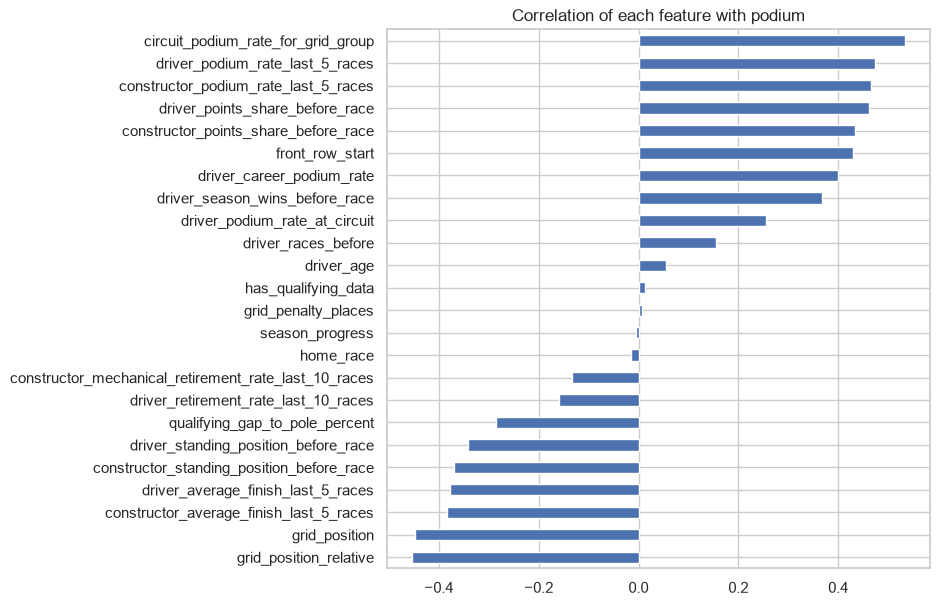

In [57]:
df[features].corrwith(df['podium']).sort_values().plot(kind='barh', figsize=(7, 7), title='Correlation of each feature with podium')
plt.show()

No feature is close to 1 or -1. The strongest are the grid features and the recent form of the driver and the team, as expected. `circuit_podium_rate_for_grid_group` is at the top because it is built from grid.

## 9. Save

The split is by season: train up to 2019, validation 2020-2021, test from 2022. `year` is only used for the split, it is not a feature.

In [58]:
df['split'] = 'train'
df.loc[df['year'] >= 2020, 'split'] = 'val'
df.loc[df['year'] >= 2022, 'split'] = 'test'

df.groupby('split')['podium'].agg(['count', 'mean'])

,count,mean
split,,
test,1352,0.150888
train,22444,0.135359
val,775,0.150968


Missing values that are left. We do **not** fill them here: any fill value (median, mean, mode) must be learned from the training rows only, so it belongs in the modeling notebook.

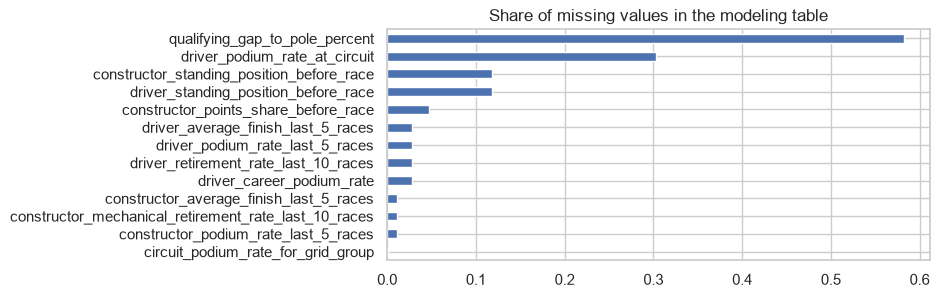

In [59]:
keys = ['raceId', 'driverId', 'constructorId', 'circuitId', 'year', 'round', 'date', 'split']
model_table = df[keys + ['podium'] + features]

missing = model_table.isna().mean()
missing[missing > 0].sort_values().plot(kind='barh', figsize=(7, 3), title='Share of missing values in the modeling table')
plt.show()

Why they are missing:

- `qualifying_gap_to_pole_percent`: no qualifying lap times for most races before 2003.
- `driver_...` form columns: the driver's first race (or first race at this circuit).
- `constructor_...` form columns: the team's first race.
- `driver_standing_position_before_race`, `constructor_standing_position_before_race`: round 1, or no points yet.
- `constructor_points_share_before_race`: before the constructors' championship started in 1958.
- `circuit_podium_rate_for_grid_group`: the very first race, which has no earlier race at all.

In [60]:
os.makedirs(OUT_DIR, exist_ok=True)
model_table.to_csv(OUT_DIR + '/modeling_table.csv', index=False)

model_table.shape

(24571, 33)

# Part 2 – Data-engineering questions

1. Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?
2. Do drivers podium more often at home, after controlling for starting position?
3. Which constructors have the highest mechanical-retirement rate in 2014–2021 vs. 2022–2024?

This part starts again from the raw files, with its own light cleaning, so each answer can be checked on its own. Each question has a plan, the joins, the checks, a table, a plot, a justification (grain, missingness, pre-race cutoff) and a written answer.

## 0. Load and light clean

### 0.1 Load the tables we need

The three questions need 7 of the 14 tables. We read them again from `DATA_DIR`.

In [61]:
RAW = DATA_DIR + '/'

results = pd.read_csv(RAW + 'results.csv')
races = pd.read_csv(RAW + 'races.csv')
circuits = pd.read_csv(RAW + 'circuits.csv')
drivers = pd.read_csv(RAW + 'drivers.csv')
constructors = pd.read_csv(RAW + 'constructors.csv')
status = pd.read_csv(RAW + 'status.csv')
qualifying = pd.read_csv(RAW + 'qualifying.csv')

results.shape, races.shape, circuits.shape, drivers.shape, constructors.shape, status.shape, qualifying.shape

((26759, 18), (1125, 18), (77, 9), (861, 9), (212, 5), (139, 2), (10494, 9))

In [62]:
results.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


### 0.2 The `\N` sentinel

`position`, `time` and other columns show `\N`. That is text, so pandas reads the whole column as text. First we look at the types and count the `\N` cells.

In [63]:
results.dtypes

resultId             int64
raceId               int64
driverId             int64
constructorId        int64
number                 str
grid                 int64
position               str
positionText           str
positionOrder        int64
points             float64
laps                 int64
time                   str
milliseconds           str
fastestLap             str
rank                   str
fastestLapTime         str
fastestLapSpeed        str
statusId             int64
dtype: object

In [64]:
# how many cells are the text \N, per column
(results == '\\N').sum()

resultId               0
raceId                 0
driverId               0
constructorId          0
number                 6
grid                   0
position           10953
positionText           0
positionOrder          0
points                 0
laps                   0
time               19079
milliseconds       19079
fastestLap         18507
rank               18249
fastestLapTime     18507
fastestLapSpeed    18507
statusId               0
dtype: int64

In [65]:
(qualifying == '\\N').sum()

qualifyId           0
raceId              0
driverId            0
constructorId       0
number              0
position            0
q1                156
q2               4625
q3               6819
dtype: int64

`position` should be a number but it is text, because 10,953 cells hold `\N`. The fix is to tell `read_csv` that `\N` means missing. We reload the tables that have it.

In [66]:
results = pd.read_csv(RAW + 'results.csv', na_values='\\N')
races = pd.read_csv(RAW + 'races.csv', na_values='\\N')
drivers = pd.read_csv(RAW + 'drivers.csv', na_values='\\N')
qualifying = pd.read_csv(RAW + 'qualifying.csv', na_values='\\N')
circuits = pd.read_csv(RAW + 'circuits.csv', na_values='\\N')

In [67]:
# check again: no \N left, and position is a number now
print((results == '\\N').sum().sum(), (qualifying == '\\N').sum().sum())
results.dtypes

0 0


resultId             int64
raceId               int64
driverId             int64
constructorId        int64
number             float64
grid                 int64
position           float64
positionText           str
positionOrder        int64
points             float64
laps                 int64
time                   str
milliseconds       float64
fastestLap         float64
rank               float64
fastestLapTime         str
fastestLapSpeed    float64
statusId             int64
dtype: object

### 0.3 The second sentinel: empty strings in qualifying

`q2` and `q3` also have empty cells (`""`) that are not `\N`. We count them in the raw text of the file, then check what pandas did with them.

In [68]:
# count the empty quoted cells in the raw file text
raw_text = open(RAW + 'qualifying.csv').read()
raw_text.count('""')

68

In [69]:
qualifying[['q1', 'q2', 'q3']].isna().sum()

q1     156
q2    4647
q3    6865
dtype: int64

In [70]:
# is any empty string still in the table?
(qualifying[['q1', 'q2', 'q3']] == '').sum()

q1    0
q2    0
q3    0
dtype: int64

`read_csv` already turns an empty cell into a missing value, so no empty string is left. The missing counts above include both the `\N` cells and the empty cells. No extra fix is needed.

### 0.4 Dates

`races.date` is text. We need it as a real date to order the races in time.

In [71]:
races['date'].head(3)

0    2009-03-29
1    2009-04-05
2    2009-04-19
Name: date, dtype: str

In [72]:
races['date'] = pd.to_datetime(races['date'])
races['date'].head(3)

0   2009-03-29
1   2009-04-05
2   2009-04-19
Name: date, dtype: datetime64[us]

### 0.5 `raceId` is not in time order

We check if a bigger `raceId` always means a later race.

In [73]:
races.sort_values('raceId')[['raceId', 'year', 'round', 'date', 'name']].head(3)

,raceId,year,round,date,name
0,1,2009,1,2009-03-29,Australian Grand Prix
1,2,2009,2,2009-04-05,Malaysian Grand Prix
2,3,2009,3,2009-04-19,Chinese Grand Prix


In [74]:
# is the date always increasing when we sort by raceId?
races.sort_values('raceId')['date'].is_monotonic_increasing

False

`raceId` 1 is the first race of 2009, and the dates are not increasing with `raceId`. So for anything about time we use `year`, `round` and `date` from `races`, never `raceId`.

### 0.6 Whitespace in `drivers.nationality`

Question 2 matches the driver nationality to the circuit country, so the text must be exact. We check for spaces at the start or the end.

In [75]:
(drivers['nationality'] != drivers['nationality'].str.strip()).sum()

np.int64(1)

In [76]:
drivers['nationality'] = drivers['nationality'].str.strip()
(drivers['nationality'] != drivers['nationality'].str.strip()).sum()

np.int64(0)

### 0.7 Duplicate (raceId, driverId) rows in `results`

One row should be one driver in one race. We check if a driver appears more than once in the same race.

In [77]:
results.duplicated(['raceId', 'driverId']).sum()

np.int64(91)

In [78]:
# look at the duplicated pairs: which years are they from?
dup = results[results.duplicated(['raceId', 'driverId'], keep=False)]
dup = dup.merge(races[['raceId', 'year']], on='raceId')
print(dup[['raceId', 'driverId']].drop_duplicates().shape[0], 'pairs,', len(dup), 'rows')
dup['year'].value_counts().sort_index()

85 pairs, 176 rows


year
1950     8
1951     8
1952     6
1953    30
1954    33
1955    33
1956    24
1957    16
1958     6
1960     2
1961     4
1962     2
1964     2
1978     2
Name: count, dtype: int64

In [79]:
# a few examples: the same driver twice in the same race
dup.sort_values(['raceId', 'driverId']).head(4)[['raceId', 'year', 'driverId', 'constructorId', 'number', 'grid', 'positionText', 'positionOrder', 'laps']]

,raceId,year,driverId,constructorId,number,grid,positionText,positionOrder,laps
0,540,1978,229,54,10.0,0,F,26,0
1,540,1978,229,57,23.0,0,F,29,0
2,717,1964,373,172,1.0,1,7,7,102
175,717,1964,373,172,2.0,1,R,12,54


The duplicates are from 1950–1964 (shared drives: a driver took over a second car during the race) plus one pair in 1978.

**Rule: keep the row with the lowest `positionOrder`**, which is the best result of the driver in that race. Our questions ask "did this driver reach the podium in this race?", and a podium in the second car is still a podium for that driver.

All three questions use 2003 or later, except question 2, so this rule only touches question 2.

In [80]:
results = results.sort_values('positionOrder').drop_duplicates(['raceId', 'driverId'])
results.duplicated(['raceId', 'driverId']).sum(), len(results)

(np.int64(0), 26668)

### 0.8 What do `position`, `positionText`, `positionOrder` and `grid = 0` mean?

There are three "position" columns. We look at them before we use them.

In [81]:
# positionText values that are letters, not numbers
letters = results[~results['positionText'].str.isdigit()]
letters['positionText'].value_counts()

positionText
R    8819
F    1366
W     335
N     190
D     151
E       9
Name: count, dtype: int64

In [82]:
# position missing, positionText a letter, positionOrder missing
results['position'].isna().sum(), len(letters), results['positionOrder'].isna().sum()

(np.int64(10872), 10870, np.int64(0))

`position` is missing on 2 rows more than there are letters. We look at those 2 rows.

In [83]:
results[results['position'].isna() & results['positionText'].str.isdigit()][['raceId', 'driverId', 'grid', 'position', 'positionText', 'positionOrder', 'laps']]

,raceId,driverId,grid,position,positionText,positionOrder,laps
1148,71,18,8,NaN,11,11,56
1151,71,11,20,NaN,14,14,55


Two rows of one race have a number in `positionText` but no `position`. It is a small gap in the source. It does not matter for us, because we use `positionOrder`, which is never missing.

In [84]:
# which status goes with each letter (top 3 per letter)
letters = letters.merge(status, on='statusId')
letters.groupby('positionText')['status'].value_counts().groupby(level=0).head(3)

positionText  status            
D             Disqualified           147
              Suspension               1
              Oil pressure             1
E             Excluded                 8
              Underweight              1
F             Did not qualify       1024
              Did not prequalify     330
              107% Rule                9
N             Not classified         171
              +7 Laps                  3
              +9 Laps                  3
R             Engine                1847
              Accident               948
              Collision              801
W             Withdrew               227
              Accident                29
              Engine                  19
Name: count, dtype: int64

Now `grid`. A grid position of 0 cannot be a real slot, so we look at who has it.

In [85]:
grid0 = results[results['grid'] == 0].merge(races[['raceId', 'year']], on='raceId')
len(grid0)

1635

In [86]:
grid0['positionText'].str.isdigit().map({True: 'classified (number)', False: 'letter'}).value_counts(), grid0[~grid0['positionText'].str.isdigit()]['positionText'].value_counts()

(positionText
 letter                 1575
 classified (number)      60
 Name: count, dtype: int64,
 positionText
 F    1346
 W     202
 R      14
 E       7
 D       6
 Name: count, dtype: int64)

In [87]:
# grid 0 rows where the driver did race laps: how many, from which year, any podium?
raced = grid0[grid0['laps'] > 0]
len(raced), raced['year'].min(), raced['year'].max(), (grid0['positionOrder'] <= 3).sum()

(72, np.int64(2015), np.int64(2024), np.int64(0))

**What we found, and what the documentation says**

We looked the columns up, because this dataset is a dump of the Ergast F1 database.

- **`positionText` codes.** The FastF1 documentation (it wraps the Ergast API, field `ClassifiedPosition`) lists them: a number if the driver is classified, else `R` = retired, `D` = disqualified, `E` = excluded, `W` = withdrawn, `F` = failed to qualify, `N` = not classified. Our status table above agrees with that (`F` goes with "Did not qualify", `W` with "Withdrew", `D` with "Disqualified").
- **`position`** is the official finishing position and is missing when `positionText` is a letter (plus the 2 rows above). **`positionOrder`** is never missing: it is a rank of all rows of a race, so retired drivers also get a number. That is why the assignment defines the podium as `positionOrder <= 3`.
- **`grid`.** The Jolpica-F1 documentation (the maintained copy of the Ergast API) describes `grid` only as "the driver's grid position". The original Ergast site is offline, so we could not open the page that explains `grid = 0`. We therefore read it from the data above: most `grid = 0` rows are drivers who never started (`F` and `W`), and a small group (72 rows, all from 2015 onward) did race laps. These are pit-lane starts: the car raced but had no slot on the grid. No `grid = 0` row is a podium.
- **`qualifying.position` vs `results.grid`.** The Ergast documentation says qualifying results are only fully supported from the 2003 season onwards. `qualifying.position` is the result of the qualifying session, `grid` is the slot where the car really started after penalties. The Jolpica documentation gives an example of a driver who qualified 13th and started 18th.

So for the rest of the notebook: a driver **started** the race if `positionText` is not `F` and not `W`, and `grid = 0` is "no grid slot", never "better than pole".

In [88]:
results['started'] = ~results['positionText'].isin(['F', 'W'])
results['started'].value_counts()

started
True     24967
False     1701
Name: count, dtype: int64

### 0.9 The base table: results + races + circuits

Every question needs the year and the circuit of each result. `results` has neither. So we join `results → races` on `raceId`, then `races → circuits` on `circuitId`. We check that the join does not add or lose rows.

In [89]:
races_small = races[['raceId', 'year', 'round', 'date', 'circuitId', 'name']].rename(columns={'name': 'race_name'})
circuits_small = circuits[['circuitId', 'name', 'country']].rename(columns={'name': 'circuit'})

merged = results.merge(races_small, on='raceId').merge(circuits_small, on='circuitId')
len(results), len(merged)

(26668, 26668)

In [90]:
merged['podium'] = (merged['positionOrder'] <= 3).astype(int)
merged[['raceId', 'year', 'race_name', 'circuit', 'country', 'driverId', 'grid', 'positionText', 'positionOrder', 'podium']].head()

,raceId,year,race_name,circuit,country,driverId,grid,positionText,positionOrder,podium
0,500,1980,South African Grand Prix,Kyalami,South Africa,163,2,1,1,1
1,809,1953,Indianapolis 500,Indianapolis Motor Speedway,USA,657,1,1,1,1
2,20,2008,Bahrain Grand Prix,Bahrain International Circuit,Bahrain,13,2,1,1,1
3,1144,2024,Abu Dhabi Grand Prix,Yas Marina Circuit,UAE,846,1,1,1,1
4,405,1986,Spanish Grand Prix,Circuito de Jerez,Spain,102,1,1,1,1


One more check on the target: a race should have 3 podium rows. In the 1950s two drivers could share one car and both get the same position, so some races have more.

In [91]:
per_race = merged.groupby(['raceId', 'year'])['podium'].sum().reset_index()
per_race['podium'].value_counts().sort_index()

podium
3    1107
4      16
5       2
Name: count, dtype: int64

In [92]:
# the races with more than 3 podium rows are all old
per_race[per_race['podium'] > 3]['year'].agg(['min', 'max', 'count'])

min      1950
max      1960
count      18
Name: year, dtype: int64

The races with more than 3 podium rows end in the early 1960s. They are real shared podiums, so we keep them. Questions 1 and 3 use 2003 onward and are not affected.

---
## Question 1 – Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?

### Plan

- **Unit (grain):** one front-row starter in one race.
- **Conversion rate of a circuit** = podiums of its front-row starters / number of its front-row starters.
- **Two definitions of "front row"**, because they can differ after penalties:
  - by **grid**: `results.grid` is 1 or 2 (where the car really started);
  - by **qualifying**: `qualifying.position` is 1 or 2 (the result of the session, before penalties).
- **Joins (multi-hop):** `results → races` (`raceId`) gives the year, `races → circuits` (`circuitId`) gives the circuit, `results → qualifying` (`raceId`, `driverId`) gives the qualifying position.
- **Eras:** before the hybrid era vs. 2014 onward.

### 1.1 Which years can we use? Qualifying coverage

Before choosing the years we check how many result rows have a matching qualifying row in each season.

In [93]:
has_quali = merged.merge(qualifying[['raceId', 'driverId', 'qualifyId']], on=['raceId', 'driverId'], how='left')
coverage = has_quali.groupby('year')['qualifyId'].apply(lambda s: s.notna().mean())
coverage[coverage.index >= 1992]

year
1992    0.000000
1993    0.000000
1994    0.882883
1995    1.000000
1996    0.435294
1997    0.585106
1998    0.438395
1999    0.184659
2000    0.235925
2001    0.058824
2002    0.116022
2003    1.000000
2004    1.000000
2005    1.000000
2006    1.000000
2007    1.000000
2008    1.000000
2009    1.000000
2010    1.000000
2011    0.991228
2012    0.991667
2013    1.000000
2014    0.995086
2015    0.989418
2016    0.989177
2017    0.995000
2018    1.000000
2019    0.995238
2020    1.000000
2021    0.997727
2022    1.000000
2023    1.000000
2024    1.000000
Name: qualifyId, dtype: float64

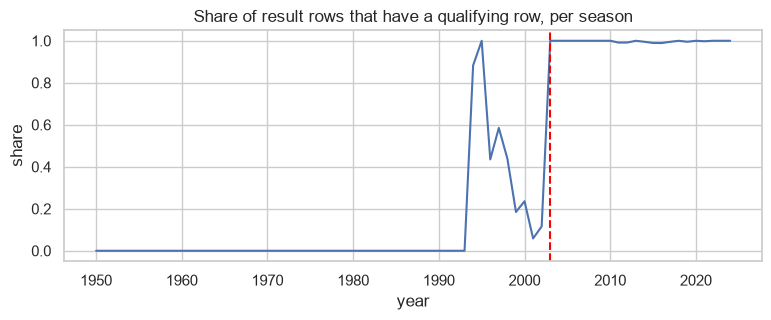

In [94]:
coverage.plot(figsize=(9, 3))
plt.axvline(2003, color='red', linestyle='--')
plt.title('Share of result rows that have a qualifying row, per season')
plt.ylabel('share')
plt.show()

There is no qualifying data before 1994, 1996–2002 is mostly missing, and from 2003 it is complete. This matches the Ergast note that qualifying is fully supported from 2003.

**Decision: use 2003–2024.** We need both definitions on the same races to compare them, and the qualifying definition only exists from 2003. This gives two eras of 11 seasons each: **2003–2013** and **2014–2024**.

### 1.2 Build the table for question 1

We keep 2003 onward and only drivers who started the race (a "front-row start" needs a start). Then we left-join qualifying, so a result without a qualifying row is kept with a missing value.

In [95]:
q1 = merged[merged['year'] >= 2003]
print(len(q1), 'rows from 2003')
q1 = q1[q1['started']]
print(len(q1), 'rows after dropping drivers who did not start')

8970 rows from 2003
8910 rows after dropping drivers who did not start


In [96]:
quali_small = qualifying[['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_pos'})
before = len(q1)
q1 = q1.merge(quali_small, on=['raceId', 'driverId'], how='left')
before, len(q1), q1['quali_pos'].isna().sum()

(8910, 8910, np.int64(21))

In [97]:
q1['era'] = '2003-2013'
q1.loc[q1['year'] >= 2014, 'era'] = '2014-2024'
q1.groupby('era')['raceId'].nunique()

era
2003-2013    200
2014-2024    228
Name: raceId, dtype: int64

### 1.3 How often is qualifying position different from grid?

This is the reason the question asks for two definitions.

In [98]:
matched = q1[q1['quali_pos'].notna()]
(matched['quali_pos'] != matched['grid']).mean()

np.float64(0.2765215434807065)

In [99]:
q1['front_grid'] = q1['grid'].isin([1, 2])
q1['front_quali'] = q1['quali_pos'] <= 2
pd.crosstab(q1['front_quali'], q1['front_grid'])

front_grid,False,True
front_quali,,
False,8022,36
True,37,815


In [100]:
# drivers who qualified in the top 2 but did not start on the front row: where did they start?
q1[q1['front_quali'] & ~q1['front_grid']]['grid'].value_counts().sort_index()

grid
0     1
3     1
4     3
5     6
6     5
7     6
8     1
10    1
11    3
12    5
13    1
14    1
19    1
20    1
24    1
Name: count, dtype: int64

In [101]:
# how many front-row starters does each race have, by each definition? (we expect 2)
print(q1.groupby('raceId')['front_grid'].sum().value_counts())
print(q1.groupby('raceId')['front_quali'].sum().value_counts())

front_grid
2    424
1      3
0      1
Name: count, dtype: int64
front_quali
2    425
1      2
0      1
Name: count, dtype: int64


Almost every race has 2. One race has no front-row starter at all, so we look at it in the base table (before the "started" filter).

In [102]:
per_race_front = q1.groupby('raceId')['front_grid'].sum()
empty_race = per_race_front[per_race_front == 0].index
merged[merged['raceId'].isin(empty_race)].sort_values('grid')[['year', 'race_name', 'grid', 'positionText', 'laps']].head(6)

,year,race_name,grid,positionText,laps
7858,2005,United States Grand Prix,1,W,0
8045,2005,United States Grand Prix,2,W,0
10060,2005,United States Grand Prix,3,W,0
10787,2005,United States Grand Prix,4,W,0
1020,2005,United States Grand Prix,5,1,73
11801,2005,United States Grand Prix,6,W,0


Qualifying position and grid differ on a large share of all rows, but for the front row they agree most of the time. The crosstab shows the few dozen cases where a top-2 qualifier lost the front row (penalty, pit-lane start = grid 0) and someone else took the slot.

The race with no front-row starter is the 2005 United States Grand Prix: the cars on grid 1 to 4 withdrew before the start (`W`), so nobody started from the front row. A few other races have only one front-row starter for the same reason (the car did not start, so we dropped it) or because the qualifying row is missing.

### 1.4 Overall conversion rate, by definition and era

First the big picture, before we split by circuit.

In [103]:
overall_grid = q1[q1['front_grid']].groupby('era')['podium'].agg(['size', 'sum', 'mean'])
overall_quali = q1[q1['front_quali']].groupby('era')['podium'].agg(['size', 'sum', 'mean'])
overall = overall_grid.join(overall_quali, lsuffix='_grid', rsuffix='_quali')
overall

,size_grid,sum_grid,mean_grid,size_quali,sum_quali,mean_quali
era,,,,,,
2003-2013,398,272,0.683417,398,269,0.675879
2014-2024,453,345,0.761589,454,336,0.740088


### 1.5 Conversion rate per circuit and era (grid definition)

Group the front-row starters by circuit and era. `races` is the number of races, `starts` the number of front-row starters, `rate` = podiums / starts.

In [104]:
by_grid = q1[q1['front_grid']].groupby(['circuit', 'era']).agg(races=('raceId', 'nunique'), starts=('podium', 'size'), podiums=('podium', 'sum')).reset_index()
by_grid['rate'] = by_grid['podiums'] / by_grid['starts']
by_grid.head()

,circuit,era,races,starts,podiums,rate
0,Albert Park Grand Prix Circuit,2003-2013,11,22,13,0.590909
1,Albert Park Grand Prix Circuit,2014-2024,9,18,13,0.722222
2,Autodromo Enzo e Dino Ferrari,2003-2013,4,8,5,0.625000
3,Autodromo Enzo e Dino Ferrari,2014-2024,4,8,6,0.750000
4,Autodromo Internazionale del Mugello,2014-2024,1,2,2,1.000000


A circuit with one or two races would give 100% or 0% by luck. So we look at how many races each circuit has per era before we choose a minimum.

In [105]:
by_grid.groupby('era')['races'].describe()

,count,mean,std,min,25%,50%,75%,max
era,,,,,,,,
2003-2013,27.0,7.37037,3.364385,1.0,4.5,8.0,11.00,11.0
2014-2024,32.0,7.12500,3.799406,1.0,4.0,8.5,10.25,13.0


In [106]:
by_grid.pivot(index='circuit', columns='era', values='races').fillna(0).astype(int).sort_values('2014-2024', ascending=False)

era,2003-2013,2014-2024
circuit,,
Red Bull Ring,1,13
Bahrain International Circuit,9,12
Silverstone Circuit,11,12
Circuit de Barcelona-Catalunya,11,11
Autodromo Nazionale di Monza,11,11
Hungaroring,11,11
Circuit de Spa-Francorchamps,9,11
Yas Marina Circuit,5,11
Autódromo José Carlos Pace,11,10


**Minimum: at least 5 races in the era** (about 10 front-row starts). With fewer races one result moves the rate by more than 10 points. A higher minimum would remove most of the newer circuits.

In [107]:
MIN_RACES = 5
by_grid_ok = by_grid[by_grid['races'] >= MIN_RACES]
by_grid_ok.groupby('era')['circuit'].count()

era
2003-2013    20
2014-2024    19
Name: circuit, dtype: int64

In [108]:
# top 10 circuits, 2003-2013
by_grid_ok[by_grid_ok['era'] == '2003-2013'].sort_values(['rate', 'starts'], ascending=False).head(10)

,circuit,era,races,starts,podiums,rate
23,Circuit de Nevers Magny-Cours,2003-2013,6,12,11,0.916667
34,Istanbul Park,2003-2013,7,14,11,0.785714
5,Autodromo Nazionale di Monza,2003-2013,11,22,17,0.772727
21,Circuit de Monaco,2003-2013,11,22,17,0.772727
51,Silverstone Circuit,2003-2013,11,22,16,0.727273
24,Circuit de Spa-Francorchamps,2003-2013,9,18,13,0.722222
54,Suzuka Circuit,2003-2013,9,18,13,0.722222
29,Hockenheimring,2003-2013,7,14,10,0.714286
19,Circuit de Barcelona-Catalunya,2003-2013,11,22,15,0.681818
11,Bahrain International Circuit,2003-2013,9,18,12,0.666667


In [109]:
# top 10 circuits, 2014-2024
by_grid_ok[by_grid_ok['era'] == '2014-2024'].sort_values(['rate', 'starts'], ascending=False).head(10)

,circuit,era,races,starts,podiums,rate
22,Circuit de Monaco,2014-2024,10,19,17,0.894737
55,Suzuka Circuit,2014-2024,9,18,16,0.888889
58,Yas Marina Circuit,2014-2024,11,22,19,0.863636
20,Circuit de Barcelona-Catalunya,2014-2024,11,22,18,0.818182
25,Circuit de Spa-Francorchamps,2014-2024,11,22,18,0.818182
53,Sochi Autodrom,2014-2024,8,16,13,0.812500
27,Circuit of the Americas,2014-2024,10,20,16,0.800000
10,Autódromo José Carlos Pace,2014-2024,10,19,15,0.789474
50,Shanghai International Circuit,2014-2024,7,14,11,0.785714
16,Circuit Gilles Villeneuve,2014-2024,9,18,14,0.777778


### 1.6 Does the ranking change? Circuits with enough races in both eras

To compare ranks we need the same circuits in both eras. We keep the circuits that pass the minimum in both.

In [110]:
rate_grid = by_grid_ok.pivot(index='circuit', columns='era', values='rate').dropna()
rate_grid['change'] = rate_grid['2014-2024'] - rate_grid['2003-2013']
# method='first': circuits with the same rate get neighbouring ranks, so the plot labels do not overlap
rate_grid['rank_before'] = rate_grid['2003-2013'].rank(ascending=False, method='first').astype(int)
rate_grid['rank_after'] = rate_grid['2014-2024'].rank(ascending=False, method='first').astype(int)
rate_grid['rank_move'] = rate_grid['rank_before'] - rate_grid['rank_after']
rate_grid = rate_grid.sort_values('2014-2024', ascending=False)
rate_grid.round(3)

era,2003-2013,2014-2024,change,rank_before,rank_after,rank_move
circuit,,,,,,
Circuit de Monaco,0.773,0.895,0.122,2,1,1
Suzuka Circuit,0.722,0.889,0.167,5,2,3
Yas Marina Circuit,0.600,0.864,0.264,11,3,8
Circuit de Spa-Francorchamps,0.722,0.818,0.096,4,5,-1
Circuit de Barcelona-Catalunya,0.682,0.818,0.136,6,4,2
Autódromo José Carlos Pace,0.591,0.789,0.199,13,6,7
Shanghai International Circuit,0.650,0.786,0.136,8,7,1
Circuit Gilles Villeneuve,0.600,0.778,0.178,10,8,2
Silverstone Circuit,0.727,0.750,0.023,3,9,-6


In [111]:
# do the two eras agree on the order? 1 = same ranking, 0 = no relation
rate_grid['2003-2013'].corr(rate_grid['2014-2024'], method='spearman')

np.float64(0.3561955619958441)

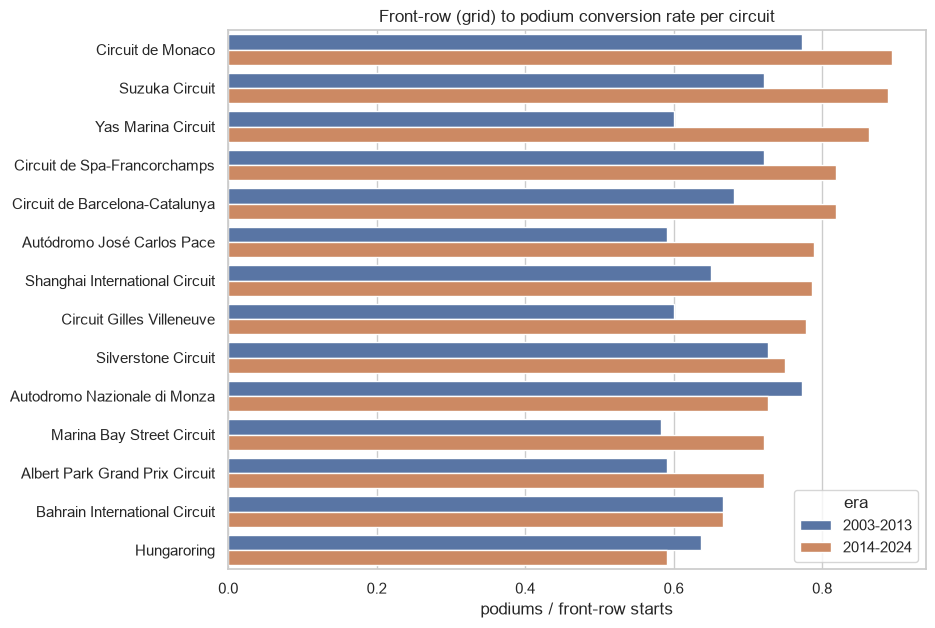

In [112]:
both = by_grid_ok[by_grid_ok['circuit'].isin(rate_grid.index)]

plt.figure(figsize=(9, 7))
sns.barplot(data=both, y='circuit', x='rate', hue='era', order=rate_grid.index)
plt.title('Front-row (grid) to podium conversion rate per circuit')
plt.xlabel('podiums / front-row starts')
plt.ylabel('')
plt.show()

The same data as ranks: one line per circuit, from its rank in 2003–2013 to its rank in 2014–2024. Crossing lines mean the ranking changed. Circuits with exactly the same rate get neighbouring ranks.

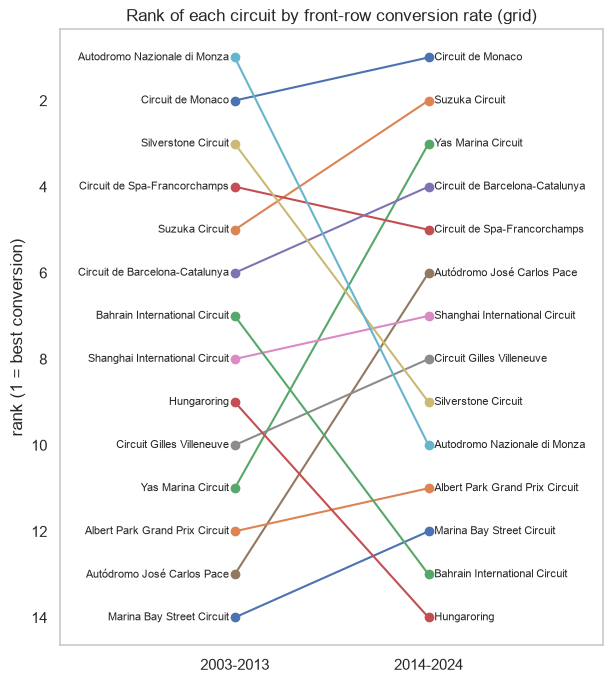

In [113]:
plt.figure(figsize=(7, 8))
for circuit, row in rate_grid.iterrows():
    plt.plot([0, 1], [row['rank_before'], row['rank_after']], marker='o')
    plt.text(-0.03, row['rank_before'], circuit, ha='right', va='center', fontsize=8)
    plt.text(1.03, row['rank_after'], circuit, ha='left', va='center', fontsize=8)
plt.xticks([0, 1], ['2003-2013', '2014-2024'])
plt.xlim(-0.9, 1.9)
plt.gca().invert_yaxis()
plt.ylabel('rank (1 = best conversion)')
plt.title('Rank of each circuit by front-row conversion rate (grid)')
plt.grid(False)
plt.show()

### 1.7 The same with the qualifying definition

Now "front row" means qualifying position 1 or 2, even if a penalty moved the driver back on the grid.

In [114]:
by_quali = q1[q1['front_quali']].groupby(['circuit', 'era']).agg(races=('raceId', 'nunique'), starts=('podium', 'size'), podiums=('podium', 'sum')).reset_index()
by_quali['rate'] = by_quali['podiums'] / by_quali['starts']
by_quali_ok = by_quali[by_quali['races'] >= MIN_RACES]
rate_quali = by_quali_ok.pivot(index='circuit', columns='era', values='rate').dropna()
rate_quali.sort_values('2014-2024', ascending=False).round(3)

era,2003-2013,2014-2024
circuit,,
Circuit de Monaco,0.682,0.895
Suzuka Circuit,0.722,0.889
Circuit de Spa-Francorchamps,0.722,0.818
Yas Marina Circuit,0.600,0.818
Circuit de Barcelona-Catalunya,0.636,0.818
Shanghai International Circuit,0.700,0.786
Silverstone Circuit,0.773,0.750
Autodromo Nazionale di Monza,0.727,0.727
Circuit Gilles Villeneuve,0.600,0.722


In [115]:
# grid definition next to qualifying definition, same circuits
compare = rate_grid[['2003-2013', '2014-2024']].join(rate_quali, lsuffix=' grid', rsuffix=' quali')
compare['diff 2003-2013'] = compare['2003-2013 quali'] - compare['2003-2013 grid']
compare['diff 2014-2024'] = compare['2014-2024 quali'] - compare['2014-2024 grid']
compare.round(3)

era,2003-2013 grid,2014-2024 grid,2003-2013 quali,2014-2024 quali,diff 2003-2013,diff 2014-2024
circuit,,,,,,
Circuit de Monaco,0.773,0.895,0.682,0.895,-0.091,0.000
Suzuka Circuit,0.722,0.889,0.722,0.889,0.000,0.000
Yas Marina Circuit,0.600,0.864,0.600,0.818,0.000,-0.045
Circuit de Spa-Francorchamps,0.722,0.818,0.722,0.818,0.000,0.000
Circuit de Barcelona-Catalunya,0.682,0.818,0.636,0.818,-0.045,0.000
Autódromo José Carlos Pace,0.591,0.789,0.591,0.684,0.000,-0.105
Shanghai International Circuit,0.650,0.786,0.700,0.786,0.050,0.000
Circuit Gilles Villeneuve,0.600,0.778,0.600,0.722,0.000,-0.056
Silverstone Circuit,0.727,0.750,0.773,0.750,0.045,0.000


In [116]:
# how similar are the two definitions? rank correlation per era
compare['2003-2013 grid'].corr(compare['2003-2013 quali'], method='spearman'), compare['2014-2024 grid'].corr(compare['2014-2024 quali'], method='spearman')

(np.float64(0.8866688559751867), np.float64(0.8777972846008472))

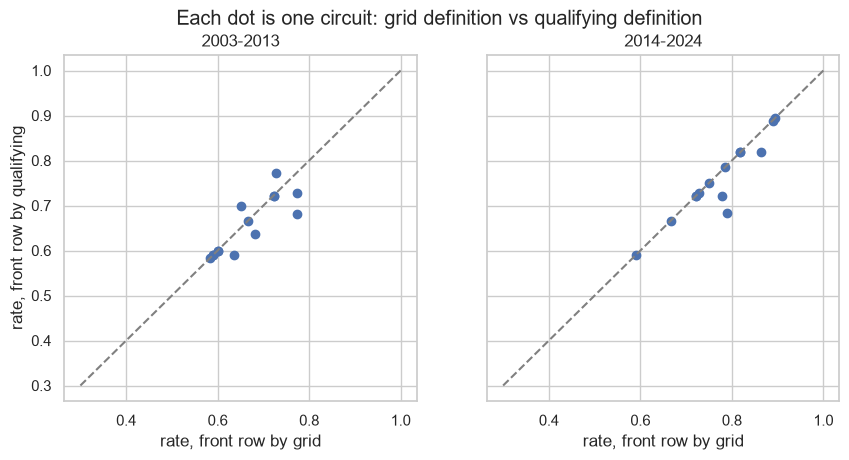

In [117]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, era in zip(axes, ['2003-2013', '2014-2024']):
    ax.scatter(compare[era + ' grid'], compare[era + ' quali'])
    ax.plot([0.3, 1], [0.3, 1], color='grey', linestyle='--')
    ax.set_title(era)
    ax.set_xlabel('rate, front row by grid')
axes[0].set_ylabel('rate, front row by qualifying')
plt.suptitle('Each dot is one circuit: grid definition vs qualifying definition')
plt.show()

### 1.8 Justification: grain, missingness, pre-race cutoff

**Grain.** One row is one driver who started one race from the front row. It comes from the base table, which is unique on (`raceId`, `driverId`) after the duplicate rule. The joins to `races`, `circuits` and `qualifying` did not change the row count (checked above), so no front-row start is counted twice. A circuit gets about 2 rows per race.

**Missingness.**
- Qualifying data is missing before 1994 and mostly missing in 1996–2002, so we use 2003–2024 only. This is the reason for the year range.
- Inside 2003–2024, 21 starters have no qualifying row. They stay in the table (left join) and simply cannot be "front row by qualifying".
- `grid = 0` is not a position. It never passes the `grid` 1-or-2 test, so pit-lane starters are not counted as front row.
- Drivers who did not start (`W`) are dropped: 60 rows. Because of that, 1 race has no front-row starter and 3 have one.
- Circuits with fewer than 5 races in an era are not ranked in that era. The ranking comparison uses the 14 circuits that have at least 5 races in both eras.

**Pre-race cutoff.** Both front-row flags are known before the race: qualifying position after the session, grid when the starting grid is published. The podium is the outcome, known after the race. So "front row" is a legal pre-race feature and the conversion rate is a description of past races. If a circuit's rate is used as a feature later, it must be computed from earlier races only.

### 1.9 Answer to question 1

**Overall.** A front-row start became a podium in **68.3%** of cases in 2003–2013 (272 of 398) and in **76.2%** in 2014–2024 (345 of 453). So in the hybrid era the front row is worth more almost everywhere.

**Which circuits convert most often (front row by grid, at least 5 races in the era).**

| 2003–2013 | rate | 2014–2024 | rate |
|---|---|---|---|
| Magny-Cours | 91.7% (11/12) | Monaco | 89.5% (17/19) |
| Istanbul Park | 78.6% (11/14) | Suzuka | 88.9% (16/18) |
| Monza | 77.3% (17/22) | Yas Marina | 86.4% (19/22) |
| Monaco | 77.3% (17/22) | Barcelona-Catalunya | 81.8% (18/22) |
| Silverstone | 72.7% (16/22) | Spa-Francorchamps | 81.8% (18/22) |

**Does the ranking change after 2014?** Yes, quite a lot. For the 14 circuits with at least 5 races in both eras, the rank correlation between the two eras is only 0.36 (1 would mean the same order).
- Monaco stays at the top (77.3% → 89.5%) and Spa and Suzuka stay near the top.
- Big climbers: Yas Marina (60.0% → 86.4%) and Interlagos (59.1% → 78.9%).
- Big fallers: Monza (77.3% → 72.7%, from the top to 10th of 14), Silverstone (72.7% → 75.0%, 3rd to 9th, because the others rose more), Bahrain (66.7% → 66.7%) and the Hungaroring (63.6% → 59.1%, now last).
- 11 of the 14 circuits have a higher rate in the hybrid era, 1 is equal and 2 are lower.

**Qualifying position vs grid.** The two differ on 27.7% of all driver rows from 2003, but the front row is more stable: of 852 top-2 qualifiers, 815 also started on the front row and 37 (4.3%) did not, mostly because of a grid penalty. With the qualifying definition the overall rates are a little lower (67.6% and 74.0%), because a top-2 qualifier who is moved back has a harder race. The circuit ranking is nearly the same with both definitions (rank correlation 0.89 and 0.88). The largest gaps are Monaco in 2003–2013 (77.3% by grid, 68.2% by qualifying) and Interlagos in 2014–2024 (78.9% by grid, 68.4% by qualifying).

**How sure are we?** Not very, for single circuits. Each rate is built on only 10 to 22 front-row starts, so one podium more or less moves it by 5 to 10 points. The overall rise from 68% to 76% is solid. The exact order of circuits next to each other is not, and part of the ranking change is just noise.

---
## Question 2 – Do drivers podium more often at home, after controlling for starting position?

### Plan

- **Unit (grain):** one driver starting one race.
- **Home race:** the country of the circuit is the country of the driver's nationality.
- **Joins (multi-hop):** `results → races` (`raceId`) `→ circuits` (`circuitId`) gives the circuit country, and `results → drivers` (`driverId`) gives the nationality. Neither is in `results`.
- **Control for starting position:** compare home and away drivers inside the same grid group, then combine the groups into one number.

### 2.1 The two columns do not match as they are

The driver has a demonym (`British`), the circuit has a country name (`UK`). We look at both lists.

In [118]:
drivers['nationality'].value_counts()

nationality
British              166
American             158
Italian               99
French                73
German                50
Brazilian             32
Argentine             24
Swiss                 23
Belgian               23
South African         23
Japanese              20
Australian            19
Dutch                 18
Spanish               15
Austrian              15
Canadian              14
Swedish               10
New Zealander         10
Finnish                9
Mexican                6
Irish                  5
Danish                 5
Portuguese             4
Monegasque             4
Rhodesian              4
Uruguayan              4
Russian                4
Colombian              3
Venezuelan             3
East German            3
Indian                 2
Thai                   2
Polish                 1
Hungarian              1
Czech                  1
Malaysian              1
Chilean                1
Liechtensteiner        1
American-Italian       1
Argentine-Ita

In [119]:
circuits['country'].value_counts()

country
USA              11
France            7
Spain             6
UK                4
Italy             4
Portugal          4
Canada            3
Germany           3
Belgium           3
Japan             3
Australia         2
Brazil            2
South Africa      2
Austria           2
Malaysia          1
Bahrain           1
Turkey            1
Monaco            1
Hungary           1
Singapore         1
China             1
United States     1
UAE               1
Argentina         1
Mexico            1
Korea             1
Netherlands       1
Sweden            1
Morocco           1
Switzerland       1
India             1
Russia            1
Azerbaijan        1
Saudi Arabia      1
Qatar             1
Name: count, dtype: int64

Two things to fix. First, `circuits.country` has both `USA` and `United States` for the same country. We make them one value in our merged table.

In [120]:
merged[merged['country'].isin(['USA', 'United States'])].groupby('country')['circuit'].unique()

country
USA              [Indianapolis Motor Speedway, Circuit of the A...
United States                     [Las Vegas Strip Street Circuit]
Name: circuit, dtype: object

In [121]:
merged['country'] = merged['country'].replace('United States', 'USA')
merged[merged['country'].isin(['USA', 'United States'])]['country'].value_counts()

country
USA    2025
Name: count, dtype: int64

Second, we need a mapping from nationality to country. It is a plain dictionary so every choice is visible. Notes on the unclear ones:

- `Argentine` and `Argentinian` are the same nationality written two ways → `Argentina`.
- `American-Italian` and `Argentine-Italian` (one driver each) → the first nationality.
- `East German` → `Germany` (the German Grand Prix was in West Germany, but it is the closest home race).
- `Monegasque` → `Monaco`.
- `Rhodesian`, `Liechtensteiner` and a few others are mapped to their country, but no race was ever held there, so these drivers have no home race.

In [122]:
nat_to_country = {
    'British': 'UK', 'American': 'USA', 'Italian': 'Italy', 'French': 'France', 'German': 'Germany',
    'Brazilian': 'Brazil', 'Argentine': 'Argentina', 'Argentinian': 'Argentina', 'Swiss': 'Switzerland',
    'Belgian': 'Belgium', 'South African': 'South Africa', 'Japanese': 'Japan', 'Australian': 'Australia',
    'Dutch': 'Netherlands', 'Spanish': 'Spain', 'Austrian': 'Austria', 'Canadian': 'Canada',
    'Swedish': 'Sweden', 'New Zealander': 'New Zealand', 'Finnish': 'Finland', 'Mexican': 'Mexico',
    'Irish': 'Ireland', 'Danish': 'Denmark', 'Portuguese': 'Portugal', 'Monegasque': 'Monaco',
    'Rhodesian': 'Rhodesia', 'Uruguayan': 'Uruguay', 'Russian': 'Russia', 'Colombian': 'Colombia',
    'Venezuelan': 'Venezuela', 'East German': 'Germany', 'Indian': 'India', 'Thai': 'Thailand',
    'Polish': 'Poland', 'Hungarian': 'Hungary', 'Czech': 'Czech Republic', 'Malaysian': 'Malaysia',
    'Chilean': 'Chile', 'Liechtensteiner': 'Liechtenstein', 'American-Italian': 'USA',
    'Argentine-Italian': 'Argentina', 'Indonesian': 'Indonesia', 'Chinese': 'China',
}
drivers['home_country'] = drivers['nationality'].map(nat_to_country)
drivers['home_country'].isna().sum()

np.int64(0)

Every nationality got a country. Now we check which of these countries never held a race in our data. Drivers from there can never be "at home".

In [123]:
race_countries = merged['country'].unique()
no_home = drivers[~drivers['home_country'].isin(race_countries)]
no_home.groupby(['nationality', 'home_country'])['driverId'].count()

nationality      home_country  
Chilean          Chile              1
Colombian        Colombia           3
Czech            Czech Republic     1
Danish           Denmark            5
Finnish          Finland            9
Indonesian       Indonesia          1
Irish            Ireland            5
Liechtensteiner  Liechtenstein      1
New Zealander    New Zealand       10
Polish           Poland             1
Rhodesian        Rhodesia           4
Thai             Thailand           2
Uruguayan        Uruguay            4
Venezuelan       Venezuela          3
Name: driverId, dtype: int64

### 2.2 Build the table for question 2

Join the nationality onto the base table, then mark the home races.

In [124]:
before = len(merged)
q2 = merged.merge(drivers[['driverId', 'nationality', 'home_country']], on='driverId')
q2['home'] = (q2['home_country'] == q2['country']).astype(int)
before, len(q2), q2['home'].sum()

(26668, 26668, np.int64(2491))

Now three filters. We look at each one before we apply it.

**Filter 1: the Indianapolis 500.** It counted for the championship in 1950–1960 but almost only American drivers who did not race elsewhere took part. All of them are "at home", and they are a different group from the normal F1 field.

In [125]:
indy = q2[q2['race_name'] == 'Indianapolis 500']
indy['year'].nunique(), len(indy), indy['home'].mean()

(11, 381, np.float64(0.9973753280839895))

In [126]:
# how many Indy 500 drivers ever raced in another race?
indy_drivers = indy['driverId'].unique()
others = q2[(q2['race_name'] != 'Indianapolis 500') & q2['driverId'].isin(indy_drivers)]['driverId'].nunique()
len(indy_drivers), others

(107, 4)

In [127]:
q2 = q2[q2['race_name'] != 'Indianapolis 500']
len(q2)

26287

**Filter 2: drivers who did not start, and starts without a grid slot.** The question controls for starting position, so we need a real grid position. Drivers with `F` or `W` never started. The pit-lane starts (`grid = 0` but raced) have no grid position to compare.

In [128]:
print((~q2['started']).sum(), 'did not start')
print((q2['started'] & (q2['grid'] == 0)).sum(), 'started with grid 0')

1701 did not start
87 started with grid 0


In [129]:
q2 = q2[q2['started'] & (q2['grid'] > 0)]
len(q2), q2['grid'].min(), q2['grid'].max()

(24499, np.int64(1), np.int64(34))

**Filter 3: drivers whose country never held a race.** They are always "away". If we keep them, the away group contains a kind of driver that the home group cannot contain. So we keep only drivers who have at least one possible home race.

In [130]:
has_home = q2['home_country'].isin(race_countries)
(~has_home).sum(), q2[~has_home]['driverId'].nunique()

(np.int64(2324), 43)

In [131]:
q2 = q2[has_home]
q2['home'].value_counts()

home
0    20248
1     1927
Name: count, dtype: int64

### 2.3 The raw comparison (no control yet)

In [132]:
raw = q2.groupby('home').agg(starts=('podium', 'size'), podiums=('podium', 'sum'), podium_rate=('podium', 'mean'), mean_grid=('grid', 'mean'), median_grid=('grid', 'median'))
raw

,starts,podiums,podium_rate,mean_grid,median_grid
home,,,,,
0,20248,2766,0.136606,11.783139,12.0
1,1927,230,0.119357,12.686559,13.0


Without any control, home drivers reach the podium a little *less* often. But `mean_grid` shows they also start about one place further back on average. (A likely reason: local drivers in small teams who enter only their home race.) So the raw gap mixes "racing at home" with "starting position". Next we take the grid out.

### 2.4 Control: compare inside grid groups

First we look at how strongly the podium depends on the grid, to choose sensible groups.

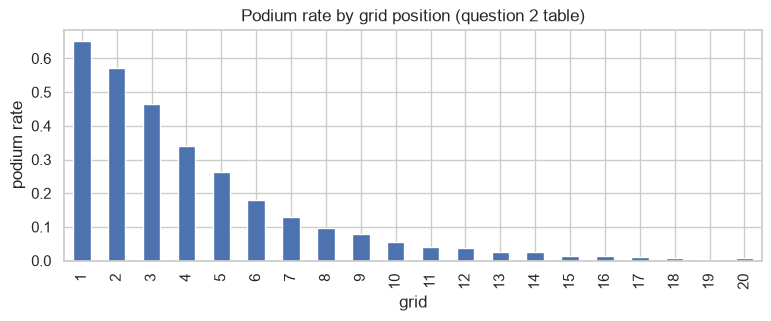

In [133]:
q2[q2['grid'] <= 20].groupby('grid')['podium'].mean().plot(kind='bar', figsize=(9, 3))
plt.title('Podium rate by grid position (question 2 table)')
plt.ylabel('podium rate')
plt.show()

The podium rate falls fast over the first rows and is close to zero after 10th. So the groups are narrow at the front and wide at the back: **1–3, 4–6, 7–10, 11+**.

In [134]:
q2['grid_bin'] = pd.cut(q2['grid'], bins=[0, 3, 6, 10, 40], labels=['1-3', '4-6', '7-10', '11+'])
q2['grid_bin'].value_counts().sort_index()

grid_bin
1-3      2975
4-6      2925
7-10     4004
11+     12271
Name: count, dtype: int64

In [135]:
by_bin = q2.groupby(['grid_bin', 'home'], observed=True).agg(starts=('podium', 'size'), podiums=('podium', 'sum'), rate=('podium', 'mean')).reset_index()
by_bin

,grid_bin,home,starts,podiums,rate
0,1-3,0,2747,1548,0.563524
1,1-3,1,228,131,0.574561
2,4-6,0,2701,704,0.260644
3,4-6,1,224,61,0.272321
4,7-10,0,3669,333,0.090760
5,7-10,1,335,25,0.074627
6,11+,0,11131,181,0.016261
7,11+,1,1140,13,0.011404


In [136]:
wide = by_bin.pivot(index='grid_bin', columns='home', values=['starts', 'rate'])
wide.columns = ['away_starts', 'home_starts', 'away_rate', 'home_rate']
wide['diff'] = wide['home_rate'] - wide['away_rate']
wide

,away_starts,home_starts,away_rate,home_rate,diff
grid_bin,,,,,
1-3,2747.0,228.0,0.563524,0.574561,0.011038
4-6,2701.0,224.0,0.260644,0.272321,0.011677
7-10,3669.0,335.0,0.090760,0.074627,-0.016134
11+,11131.0,1140.0,0.016261,0.011404,-0.004857


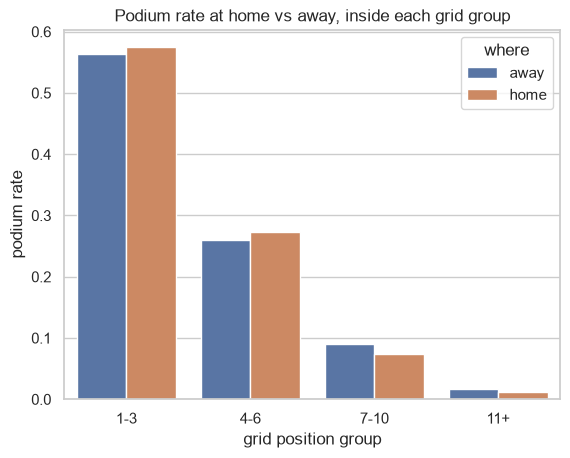

In [137]:
plot_bin = by_bin.copy()
plot_bin['where'] = plot_bin['home'].map({0: 'away', 1: 'home'})

sns.barplot(data=plot_bin, x='grid_bin', y='rate', hue='where')
plt.title('Podium rate at home vs away, inside each grid group')
plt.xlabel('grid position group')
plt.ylabel('podium rate')
plt.show()

### 2.5 One controlled number

**Method 1: weighted average of the differences.** We take the home-minus-away difference of each grid group and average them, weighted by the number of home starts in the group. In words: "for the grid positions that home drivers really had, how much higher is their podium rate than away drivers from the same positions?"

In [138]:
controlled_diff = (wide['diff'] * wide['home_starts']).sum() / wide['home_starts'].sum()
raw_diff = raw.loc[1, 'podium_rate'] - raw.loc[0, 'podium_rate']
raw_diff, controlled_diff

(np.float64(-0.01724957183749734), np.float64(-0.0030149969096303266))

The four groups are still wide (grid 1 and grid 3 are in the same group). As a check we repeat the same calculation with every single grid position as its own group.

In [139]:
by_pos = q2.groupby(['grid', 'home'])['podium'].agg(['size', 'mean']).unstack()
by_pos.columns = ['away_starts', 'home_starts', 'away_rate', 'home_rate']
by_pos = by_pos.dropna()
by_pos['diff'] = by_pos['home_rate'] - by_pos['away_rate']
by_pos.head(10)

,away_starts,home_starts,away_rate,home_rate,diff
grid,,,,,
1,937.0,80.0,0.656350,0.612500,-0.043850
2,914.0,75.0,0.573304,0.560000,-0.013304
3,896.0,73.0,0.456473,0.547945,0.091472
4,912.0,73.0,0.337719,0.369863,0.032144
5,899.0,70.0,0.256952,0.328571,0.071619
6,890.0,81.0,0.185393,0.135802,-0.049591
7,914.0,78.0,0.125821,0.153846,0.028026
8,905.0,77.0,0.098343,0.064935,-0.033407
9,918.0,94.0,0.079521,0.085106,0.005586


In [140]:
controlled_diff_exact = (by_pos['diff'] * by_pos['home_starts']).sum() / by_pos['home_starts'].sum()
controlled_diff_exact

np.float64(-0.0018477967982408092)

**Method 2: a simple logistic regression.** `podium ~ grid group + home`. The `home` coefficient says how the odds of a podium change at home for drivers in the same grid group. It also gives a confidence interval, which the weighted average does not.

In [141]:
model = smf.logit('podium ~ C(grid_bin) + home', data=q2).fit()
model.summary().tables[1]

Optimization terminated successfully.
         Current function value: 0.267015
         Iterations 8


,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,0.2620,0.038,6.970,0.000,0.188,0.336
C(grid_bin)[T.4-6],-1.2969,0.056,-23.154,0.000,-1.407,-1.187
C(grid_bin)[T.7-10],-2.5795,0.067,-38.735,0.000,-2.710,-2.449
C(grid_bin)[T.11+],-4.3895,0.081,-54.007,0.000,-4.549,-4.230
home,-0.0397,0.087,-0.454,0.650,-0.211,0.131


In [142]:
# odds ratio of home, with its 95% interval and p-value
np.exp(model.params['home']), np.exp(model.conf_int().loc['home']).tolist(), model.pvalues['home']

(np.float64(0.9611033517474779),
 [0.8099389176418867, 1.1404806370208986],
 np.float64(0.649541145272778))

### 2.6 Is it the same in old and modern F1?

The table mixes 75 years. One quick check: the same controlled difference for races before 1990 and from 1990.

In [143]:
q2['period'] = np.where(q2['year'] < 1990, '1950-1989', '1990-2024')
by_period = q2.groupby(['period', 'grid_bin', 'home'], observed=True)['podium'].agg(['size', 'mean']).unstack()
by_period.columns = ['away_starts', 'home_starts', 'away_rate', 'home_rate']
by_period['diff'] = by_period['home_rate'] - by_period['away_rate']
by_period

away_starts  home_starts  away_rate  home_rate      diff
period    grid_bin                                                          
1950-1989 1-3              1215          121   0.465021   0.545455  0.080434
          4-6              1171          133   0.292058   0.308271  0.016213
          7-10             1550          196   0.123871   0.107143 -0.016728
          11+              4927          759   0.022123   0.014493 -0.007630
1990-2024 1-3              1532          107   0.641645   0.607477 -0.034168
          4-6              1530           91   0.236601   0.219780 -0.016821
          7-10             2119          139   0.066541   0.028777 -0.037764
          11+              6204          381   0.011605   0.005249 -0.006356

In [144]:
by_period['weighted'] = by_period['diff'] * by_period['home_starts']
by_period.groupby('period')['weighted'].sum() / by_period.groupby('period')['home_starts'].sum()

period
1950-1989    0.002331
1990-2024   -0.017907
dtype: float64

### 2.7 Justification: grain, missingness, pre-race cutoff

**Grain.** One row is one driver starting one race, unique on (`raceId`, `driverId`). The join to `drivers` did not change the row count (checked above). The duplicate rule from section 0.7 matters here, because the shared drives of the 1950s are in this table: each driver counts once per race, with the best result.

**Missingness.**
- `grid = 0` is "no grid slot", not a position. We dropped the 1,701 entries that never started and the 87 starts with `grid = 0`, because they cannot be put in a grid group.
- No nationality is missing, and every nationality has a country in the mapping. 43 drivers (2,324 starts) come from a country that never held a race; they are left out because they can never be "at home".
- The 11 Indianapolis 500 races are left out: 99.7% of the entries were home drivers and only 4 of the 107 drivers ever raced elsewhere, so they are a separate population.
- "Home" follows `drivers.nationality`, one value per driver. Dual nationals get the first one, and `East German` drivers are matched to Germany. A driver's licence country can differ from where they grew up; the data does not have that.

**Pre-race cutoff.** `home`, the nationality, the circuit country and `grid` are all known before the race, so `home` is a legal feature. The podium is the outcome.

**What "controlling" means here.** We compare home and away drivers inside the same grid group. This removes the starting position, but not the car or the driver's skill. So the result is an association, not a cause.

### 2.8 Answer to question 2

**No. After controlling for starting position there is no home advantage in this data.**

The table has 22,175 race starts from 1950 to 2024 (Indianapolis 500 left out): 1,927 at home and 20,248 away.

- **Raw:** home drivers reach the podium *less* often, 11.9% (230 of 1,927) against 13.7% (2,766 of 20,248). But they also start further back (mean grid 12.7 against 11.8). So the opposite of the usual guess is true here: home drivers do not qualify better on average.
- **Inside grid groups** (home vs away):

| grid | home | away | difference |
|---|---|---|---|
| 1–3 | 57.5% (131/228) | 56.4% (1,548/2,747) | +1.1 points |
| 4–6 | 27.2% (61/224) | 26.1% (704/2,701) | +1.2 points |
| 7–10 | 7.5% (25/335) | 9.1% (333/3,669) | −1.6 points |
| 11+ | 1.1% (13/1,140) | 1.6% (181/11,131) | −0.5 points |

- **One controlled number:** the weighted average of these differences is **−0.3 percentage points**. With every grid position as its own group it is −0.2 points. The raw gap of −1.7 points almost disappears, so most of it came from the starting position.
- **Logistic regression** (`podium ~ grid group + home`): the odds ratio for home is **0.96**, with a 95% interval from 0.81 to 1.14 and p = 0.65. The interval contains 1, so the data does not show an effect in either direction.
- **By period:** +0.2 points in 1950–1989 and −1.8 points in 1990–2024. The sign is not stable and both are small.

The differences go both ways across the groups and are small next to the sample sizes (228 home starts in the front group). We conclude that a driver who starts from a similar grid position is about as likely to reach the podium at home as elsewhere. This is a comparison of groups, not proof that racing at home has no effect on a single driver: we did not control for the car or the driver.

---
## Question 3 – Which constructors have the highest mechanical-retirement rate in 2014–2021 vs. 2022–2024?

### Plan

- **Unit (grain):** one car starting one race (one row of `results` for a driver who started).
- **Mechanical-retirement rate of a constructor** = mechanical retirements / race starts, in each period.
- **Joins (multi-hop):** `results → races` (`raceId`) gives the year and so the period, `results → status` (`statusId`) gives the reason the race ended, `results → constructors` (`constructorId`) gives the team name.
- The assignment's definition: *a race start that ended early because a component of the car failed; not a crash, not the driver, not a regulation decision.* So we need (a) who started and (b) a class for every status.

### 3.1 Build the table for question 3

In [145]:
q3 = merged[merged['year'] >= 2014]
before = len(q3)
q3 = q3.merge(status, on='statusId').merge(constructors[['constructorId', 'name']].rename(columns={'name': 'constructor'}), on='constructorId')
q3['period'] = np.where(q3['year'] <= 2021, '2014-2021', '2022-2024')
before, len(q3)

(4626, 4626)

In [146]:
q3.groupby('period').agg(races=('raceId', 'nunique'), rows=('raceId', 'size'), constructors=('constructor', 'nunique'))

,races,rows,constructors
period,,,
2014-2021,160,3267,19
2022-2024,68,1359,12


### 3.2 Every status value in 2014–2024

`status.csv` has 139 values but only some appear in these years. We list all of them with their counts, so every one can be classified by hand.

In [147]:
status_counts = q3['status'].value_counts()
len(status_counts)

66

In [148]:
status_counts.to_frame().T

status,Finished,+1 Lap,+2 Laps,Collision,Accident,Engine,Collision damage,Retired,Brakes,Power Unit,...,Drivetrain,Water pump,Out of fuel,Spark plugs,+5 Laps,Debris,Fuel system,Differential,Excluded,+7 Laps
count,2403,1178,208,150,85,81,59,50,49,42,...,1,1,1,1,1,1,1,1,1,1


### 3.3 Classify the statuses

The `+1 Lap`, `+2 Laps`, ... values mean the car was still running at the end, some laps behind the winner. Together with `Finished` they are class `finished`. All the others go in a plain dictionary.

Classes:

- `mechanical` – the status names a part or system of the car that failed.
- `accident` – crash, collision, or damage from one.
- `driver` – caused by the driver.
- `regulation` – decided by the stewards.
- `unclear` – the status does not say why the race ended.

In [149]:
status_class = {
    # a part or system of the car
    'Engine': 'mechanical', 'Power Unit': 'mechanical', 'ERS': 'mechanical', 'Turbo': 'mechanical',
    'Battery': 'mechanical', 'Power loss': 'mechanical', 'Spark plugs': 'mechanical', 'Exhaust': 'mechanical',
    'Gearbox': 'mechanical', 'Transmission': 'mechanical', 'Clutch': 'mechanical', 'Driveshaft': 'mechanical',
    'Drivetrain': 'mechanical', 'Differential': 'mechanical', 'Hydraulics': 'mechanical',
    'Electrical': 'mechanical', 'Electronics': 'mechanical', 'Throttle': 'mechanical',
    'Brakes': 'mechanical', 'Brake duct': 'mechanical', 'Suspension': 'mechanical', 'Steering': 'mechanical',
    'Wheel': 'mechanical', 'Wheel nut': 'mechanical', 'Vibrations': 'mechanical',
    'Oil leak': 'mechanical', 'Oil pressure': 'mechanical', 'Water leak': 'mechanical',
    'Water pressure': 'mechanical', 'Water pump': 'mechanical', 'Radiator': 'mechanical',
    'Overheating': 'mechanical', 'Cooling system': 'mechanical',
    'Fuel pressure': 'mechanical', 'Fuel leak': 'mechanical', 'Fuel system': 'mechanical',
    'Fuel pump': 'mechanical', 'Out of fuel': 'mechanical',
    'Front wing': 'mechanical', 'Rear wing': 'mechanical', 'Undertray': 'mechanical', 'Seat': 'mechanical',
    'Mechanical': 'mechanical', 'Technical': 'mechanical',
    # crash or damage
    'Collision': 'accident', 'Accident': 'accident', 'Collision damage': 'accident',
    'Damage': 'accident', 'Debris': 'accident',
    # the driver
    'Spun off': 'driver', 'Illness': 'driver',
    # the stewards
    'Disqualified': 'regulation', 'Excluded': 'regulation',
    # reason not given
    'Retired': 'unclear', 'Withdrew': 'unclear', 'Puncture': 'unclear', 'Tyre': 'unclear',
    'Finished': 'finished',
}
q3['status_class'] = q3['status'].map(status_class)
q3.loc[q3['status'].str.startswith('+'), 'status_class'] = 'finished'
q3['status_class'].isna().sum()

np.int64(0)

No status is left without a class. Here is the full list with class and count, so the reader can check each one.

In [150]:
check = q3.groupby(['status_class', 'status']).size().rename('rows').reset_index().sort_values(['status_class', 'rows'], ascending=[True, False])
pd.set_option('display.max_rows', 200)
check

,status_class,status,rows
1,accident,Collision,150
0,accident,Accident,85
2,accident,Collision damage,59
3,accident,Damage,2
4,accident,Debris,1
6,driver,Spun off,11
5,driver,Illness,3
15,finished,Finished,2403
7,finished,+1 Lap,1178
8,finished,+2 Laps,208


In [151]:
q3['status_class'].value_counts()

status_class
finished      3825
mechanical     403
accident       297
unclear         75
driver          14
regulation      12
Name: count, dtype: int64

**Borderline calls**

- `Power Unit`, `ERS`, `Turbo`, `Battery` are the hybrid-era names for engine parts → mechanical.
- `Wheel` and `Wheel nut` → mechanical. Often a wheel that was not fixed properly at a pit stop. It is a team error, but the car stopped because a part of it was not working, and it is not a crash, the driver, or a regulation decision.
- `Out of fuel` (1 row) → mechanical, for the same reason: the car could not go on, and none of the three exclusions applies.
- `Front wing`, `Rear wing`, `Undertray` (10 rows together) → mechanical because the status names a car part. Some of these may really be contact damage; the data has a separate `Collision damage` status for that, so we trust the label.
- `Collision damage`, `Damage`, `Debris` → accident. The part failed because of a crash or an object on track, which the definition excludes.
- `Spun off` → driver. `Illness` → driver.
- `Puncture` and `Tyre` (11 rows) → unclear. A tyre is a part of the car, but tyres mostly fail from debris, contact or wear, and the status does not say which. We do not count them.
- `Retired` and `Withdrew` → unclear. The team stopped the car and the reason is not recorded. We do not count them as mechanical, and we test below how much this choice matters.

### 3.4 Who started?

The denominator is race starts. From section 0.8, `positionText` = `W` (withdrawn) marks cars that did not start. We look at these rows before we drop them.

In [152]:
q3['positionText'].str.isdigit().map({True: 'classified (number)', False: 'letter'}).value_counts(), q3[~q3['positionText'].str.isdigit()]['positionText'].value_counts()

(positionText
 classified (number)    3905
 letter                  721
 Name: count, dtype: int64,
 positionText
 R    680
 W     28
 D     11
 N      1
 E      1
 Name: count, dtype: int64)

In [153]:
# the W rows: laps and status
not_started = q3[~q3['started']]
print(not_started['laps'].max())
not_started['status'].value_counts()

0


status
Withdrew       11
Power Unit      3
Gearbox         2
Engine          2
Fuel system     1
ERS             1
Exhaust         1
Driveshaft      1
Brakes          1
Illness         1
Power loss      1
Fuel leak       1
Hydraulics      1
Retired         1
Name: count, dtype: int64

All `W` rows have 0 laps. Many of them have a mechanical status (`Engine`, `Power Unit`, `Gearbox`): the car broke before the start. That is a failure, but not a *race start that ended early*, so by the assignment's definition these are out of both the numerator and the denominator.

In [154]:
q3 = q3[q3['started']]
len(q3)

4598

A related case: rows marked `R` (retired) with 0 laps and a mechanical status. The car stopped before it finished lap 1, or on the way to the grid.

In [155]:
q3[(q3['laps'] == 0) & (q3['status_class'] == 'mechanical')][['year', 'race_name', 'constructor', 'grid', 'positionText', 'status']]

,year,race_name,constructor,grid,positionText,status
3119,2015,Australian Grand Prix,Lotus F1,8,R,Power loss
4178,2022,Saudi Arabian Grand Prix,AlphaTauri,19,R,Power Unit
4226,2018,Italian Grand Prix,Toro Rosso,16,R,Brakes
4331,2017,British Grand Prix,Renault,11,R,Hydraulics
4385,2017,Bahrain Grand Prix,McLaren,17,R,Power Unit
4411,2017,Malaysian Grand Prix,Ferrari,0,R,Battery
4437,2022,Japanese Grand Prix,Williams,16,R,Hydraulics
4479,2023,Italian Grand Prix,AlphaTauri,11,R,Engine
4510,2018,Hungarian Grand Prix,Sauber,17,R,Suspension


The data marks these as retired, not withdrawn, and we cannot tell a failure on the formation lap from one in the first corners. We follow the data and keep them as starts. It is only a handful of rows, so it cannot change the ranking.

One more look: some mechanical statuses belong to a car that is classified with a number. A car is classified if it did 90% of the distance, even if it stopped before the flag. Its race still ended early because of a failure, so we count it.

In [156]:
q3['mech'] = (q3['status_class'] == 'mechanical').astype(int)
q3[q3['mech'] == 1]['positionText'].str.isdigit().value_counts()

positionText
False    348
True      40
Name: count, dtype: int64

In [157]:
q3.groupby('period')['mech'].agg(['size', 'sum', 'mean'])

,size,sum,mean
period,,,
2014-2021,3246,308,0.094886
2022-2024,1352,80,0.059172


### 3.5 Rate per constructor, with the names as given

First the simple version: group by the constructor name in the data.

In [158]:
by_name = q3.groupby(['period', 'constructor']).agg(starts=('mech', 'size'), mech=('mech', 'sum'), first=('year', 'min'), last=('year', 'max')).reset_index()
by_name['rate'] = by_name['mech'] / by_name['starts']
by_name.sort_values(['period', 'rate'], ascending=[True, False])

,period,constructor,starts,mech,first,last,rate
4,2014-2021,Caterham,33,7,2014,2014,0.212121
8,2014-2021,Lotus F1,75,14,2014,2015,0.186667
17,2014-2021,Toro Rosso,242,39,2014,2019,0.161157
15,2014-2021,Renault,199,29,2016,2020,0.145729
11,2014-2021,McLaren,316,43,2014,2021,0.136076
14,2014-2021,Red Bull,318,34,2014,2021,0.106918
16,2014-2021,Sauber,199,21,2014,2018,0.105528
10,2014-2021,Marussia,31,3,2014,2014,0.096774
7,2014-2021,Haas F1 Team,241,23,2016,2021,0.095436
1,2014-2021,AlphaTauri,77,7,2020,2021,0.090909


There is a problem for the comparison. Several teams changed their name, and each name is a different `constructorId`. `Toro Rosso`, `AlphaTauri` and `RB F1 Team` are the same team. So are `Force India`, `Racing Point` and `Aston Martin`, and others. With the names as given, `AlphaTauri` appears in both periods as two small pieces and `Force India` has no second period at all, so "2014–2021 vs 2022–2024" cannot be read for them.

### 3.6 Group the rebrands into team lineages

**Decision: compare by team lineage.** The same factory and mostly the same people build the car before and after a rename, and the question compares the same teams across two periods. The mapping is a plain dictionary:

- Toro Rosso → AlphaTauri → RB F1 Team
- Force India → Racing Point → Aston Martin
- Lotus F1 → Renault → Alpine F1 Team (the Enstone team; Renault bought Lotus F1 at the end of 2015)
- Sauber → Alfa Romeo → Sauber
- Marussia → Manor Marussia

One caveat: a lineage keeps the team but not always the engine supplier, so this is "the team", not "the engine".

In [159]:
lineage = {
    'Toro Rosso': 'Toro Rosso / AlphaTauri / RB',
    'AlphaTauri': 'Toro Rosso / AlphaTauri / RB',
    'RB F1 Team': 'Toro Rosso / AlphaTauri / RB',
    'Force India': 'Force India / Racing Point / Aston Martin',
    'Racing Point': 'Force India / Racing Point / Aston Martin',
    'Aston Martin': 'Force India / Racing Point / Aston Martin',
    'Lotus F1': 'Lotus F1 / Renault / Alpine',
    'Renault': 'Lotus F1 / Renault / Alpine',
    'Alpine F1 Team': 'Lotus F1 / Renault / Alpine',
    'Sauber': 'Sauber / Alfa Romeo',
    'Alfa Romeo': 'Sauber / Alfa Romeo',
    'Marussia': 'Marussia / Manor',
    'Manor Marussia': 'Marussia / Manor',
}
q3['team'] = q3['constructor'].replace(lineage)
q3.groupby('team')['constructor'].unique()

team
Caterham                                                                    [Caterham]
Ferrari                                                                      [Ferrari]
Force India / Racing Point / Aston Martin    [Racing Point, Aston Martin, Force India]
Haas F1 Team                                                            [Haas F1 Team]
Lotus F1 / Renault / Alpine                        [Alpine F1 Team, Renault, Lotus F1]
Marussia / Manor                                            [Marussia, Manor Marussia]
McLaren                                                                      [McLaren]
Mercedes                                                                    [Mercedes]
Red Bull                                                                    [Red Bull]
Sauber / Alfa Romeo                                               [Alfa Romeo, Sauber]
Toro Rosso / AlphaTauri / RB                      [AlphaTauri, Toro Rosso, RB F1 Team]
Williams                              

In [160]:
by_team = q3.groupby(['period', 'team']).agg(starts=('mech', 'size'), mech=('mech', 'sum')).reset_index()
by_team['rate'] = by_team['mech'] / by_team['starts']
by_team.sort_values('starts').head(5)

,period,team,starts,mech,rate
0,2014-2021,Caterham,33,7,0.212121
5,2014-2021,Marussia / Manor,108,7,0.064815
12,2022-2024,Ferrari,134,7,0.052239
13,2022-2024,Force India / Racing Point / Aston Martin,134,7,0.052239
21,2022-2024,Williams,134,8,0.059701


**Minimum: at least 50 starts in the period.** `Caterham` has only one season (2014) and falls under it. Every other team has more than 100 starts in each period it raced in. With fewer than 50 starts a single failure moves the rate by more than 2 points.

In [161]:
MIN_STARTS = 50
by_team_ok = by_team[by_team['starts'] >= MIN_STARTS]
by_team[by_team['starts'] < MIN_STARTS]

,period,team,starts,mech,rate
0,2014-2021,Caterham,33,7,0.212121


In [162]:
# ranking 2014-2021
rank_1 = by_team_ok[by_team_ok['period'] == '2014-2021'].sort_values('rate', ascending=False).reset_index(drop=True)
rank_1

,period,team,starts,mech,rate
0,2014-2021,Lotus F1 / Renault / Alpine,318,47,0.147799
1,2014-2021,Toro Rosso / AlphaTauri / RB,319,46,0.144201
2,2014-2021,McLaren,316,43,0.136076
3,2014-2021,Red Bull,318,34,0.106918
4,2014-2021,Haas F1 Team,241,23,0.095436
5,2014-2021,Sauber / Alfa Romeo,319,26,0.081505
6,2014-2021,Williams,319,24,0.075235
7,2014-2021,Marussia / Manor,108,7,0.064815
8,2014-2021,Force India / Racing Point / Aston Martin,317,20,0.063091
9,2014-2021,Ferrari,318,18,0.056604


In [163]:
# ranking 2022-2024
rank_2 = by_team_ok[by_team_ok['period'] == '2022-2024'].sort_values('rate', ascending=False).reset_index(drop=True)
rank_2

,period,team,starts,mech,rate
0,2022-2024,Lotus F1 / Renault / Alpine,135,14,0.103704
1,2022-2024,Sauber / Alfa Romeo,136,12,0.088235
2,2022-2024,Toro Rosso / AlphaTauri / RB,136,9,0.066176
3,2022-2024,Williams,134,8,0.059701
4,2022-2024,Force India / Racing Point / Aston Martin,134,7,0.052239
5,2022-2024,Ferrari,134,7,0.052239
6,2022-2024,Haas F1 Team,135,7,0.051852
7,2022-2024,Mercedes,136,6,0.044118
8,2022-2024,McLaren,136,5,0.036765
9,2022-2024,Red Bull,136,5,0.036765


In [164]:
team_wide = by_team_ok.pivot(index='team', columns='period', values='rate')
team_wide['change'] = team_wide['2022-2024'] - team_wide['2014-2021']
team_wide.sort_values('2014-2021', ascending=False).round(3)

period,2014-2021,2022-2024,change
team,,,
Lotus F1 / Renault / Alpine,0.148,0.104,-0.044
Toro Rosso / AlphaTauri / RB,0.144,0.066,-0.078
McLaren,0.136,0.037,-0.099
Red Bull,0.107,0.037,-0.070
Haas F1 Team,0.095,0.052,-0.044
Sauber / Alfa Romeo,0.082,0.088,0.007
Williams,0.075,0.060,-0.016
Marussia / Manor,0.065,NaN,NaN
Force India / Racing Point / Aston Martin,0.063,0.052,-0.011


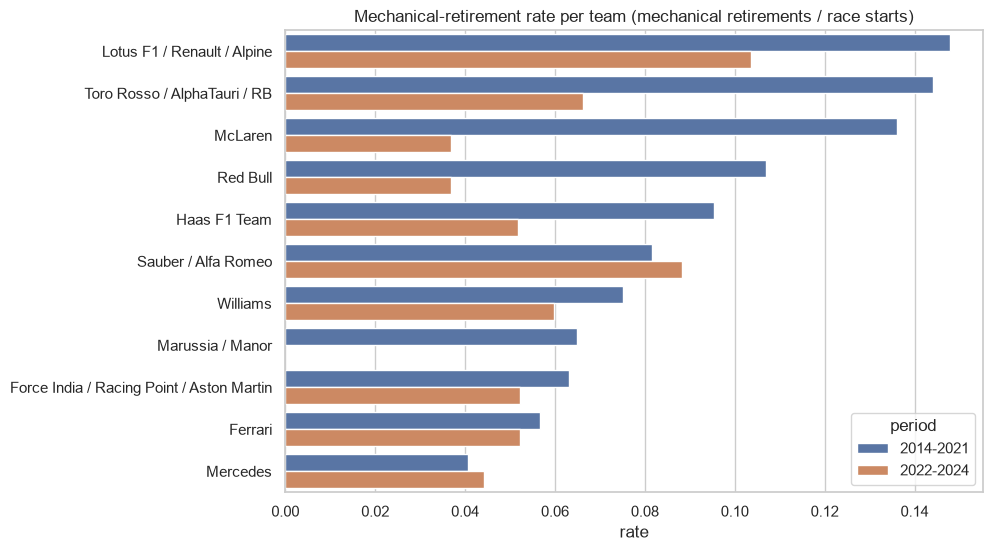

In [165]:
plt.figure(figsize=(9, 6))
sns.barplot(data=by_team_ok, y='team', x='rate', hue='period', order=rank_1['team'])
plt.title('Mechanical-retirement rate per team (mechanical retirements / race starts)')
plt.xlabel('rate')
plt.ylabel('')
plt.show()

The bars are sorted by the 2014–2021 rate. `Marussia / Manor` has no second bar because the team stopped after 2016.

### 3.7 What ended the races in each period?

A second view to put the mechanical rate in context: the share of starts in each status class, per period.

In [166]:
mix = pd.crosstab(q3['period'], q3['status_class'], normalize='index')
mix.round(3)

status_class,accident,driver,finished,mechanical,regulation,unclear
period,,,,,,
2014-2021,0.066,0.002,0.819,0.095,0.002,0.015
2022-2024,0.062,0.004,0.862,0.059,0.003,0.010


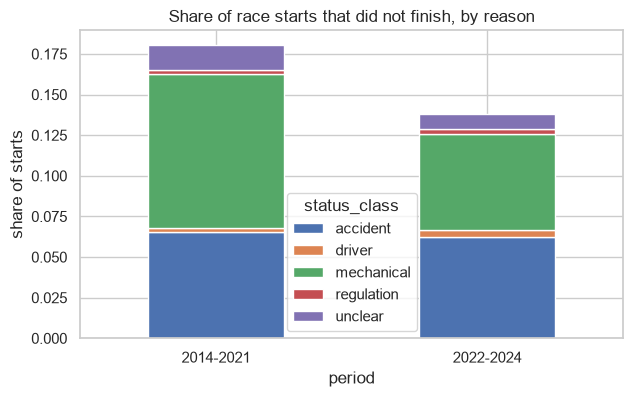

In [167]:
mix.drop(columns='finished').plot(kind='bar', stacked=True, figsize=(7, 4))
plt.title('Share of race starts that did not finish, by reason')
plt.ylabel('share of starts')
plt.xticks(rotation=0)
plt.show()

### 3.8 Does the answer depend on the unclear statuses?

We did not count `Retired`, `Withdrew`, `Puncture` and `Tyre`. Here we count them all as mechanical (the widest possible definition) and see if the ranking changes.

In [168]:
q3['mech_wide'] = q3['status_class'].isin(['mechanical', 'unclear']).astype(int)
wide_team = q3.groupby(['period', 'team']).agg(starts=('mech', 'size'), rate=('mech', 'mean'), rate_wide=('mech_wide', 'mean')).reset_index()
wide_team = wide_team[wide_team['starts'] >= MIN_STARTS]
wide_team.sort_values(['period', 'rate_wide'], ascending=[True, False]).round(3)

,period,team,starts,rate,rate_wide
4,2014-2021,Lotus F1 / Renault / Alpine,318,0.148,0.167
10,2014-2021,Toro Rosso / AlphaTauri / RB,319,0.144,0.163
6,2014-2021,McLaren,316,0.136,0.155
3,2014-2021,Haas F1 Team,241,0.095,0.124
8,2014-2021,Red Bull,318,0.107,0.116
9,2014-2021,Sauber / Alfa Romeo,319,0.082,0.097
11,2014-2021,Williams,319,0.075,0.094
5,2014-2021,Marussia / Manor,108,0.065,0.083
2,2014-2021,Force India / Racing Point / Aston Martin,317,0.063,0.069
1,2014-2021,Ferrari,318,0.057,0.063


### 3.9 Justification: grain, missingness, pre-race cutoff

**Grain.** One row is one car that started one race (one driver of one constructor in one race). The table is unique on (`raceId`, `driverId`), and the joins to `status` and `constructors` did not change the row count. The rate is counted per period and per team, with race starts as the denominator.

**Missingness.**
- `statusId` is never missing and all 66 status values that appear in 2014–2024 have a class (checked above).
- The real gap is in the meaning: `Retired` and `Withdrew` (and tyre problems) do not say why the car stopped. That is 75 rows, against 388 mechanical ones. We do not count them, and section 3.8 shows the top of the ranking is the same if we do.
- 28 entries that never started (`W`) are out of the rate, also when the reason was mechanical.
- `Caterham` (33 starts, one season) is under the minimum of 50 starts and is not ranked. Its rate would be the highest of all (21.2%, 7 of 33).
- `Marussia / Manor` has no rate for 2022–2024 because the team no longer existed.

**Pre-race cutoff.** `status` is written after the race, so the status of the race being predicted can never be a feature. This section only describes past races. A reliability feature for the model (for example the team's mechanical-retirement rate in its last 10 races) must use earlier races only.

### 3.10 Answer to question 3

**Overall.** Cars became more reliable: 9.5% of race starts ended with a mechanical retirement in 2014–2021 (308 of 3,246) and 5.9% in 2022–2024 (80 of 1,352).

**By team lineage (rebrands grouped, at least 50 starts in the period).**

| rank | 2014–2021 | rate | 2022–2024 | rate |
|---|---|---|---|---|
| 1 | Lotus F1 / Renault / Alpine | 14.8% (47/318) | Lotus F1 / Renault / Alpine | 10.4% (14/135) |
| 2 | Toro Rosso / AlphaTauri / RB | 14.4% (46/319) | Sauber / Alfa Romeo | 8.8% (12/136) |
| 3 | McLaren | 13.6% (43/316) | Toro Rosso / AlphaTauri / RB | 6.6% (9/136) |
| 4 | Red Bull | 10.7% (34/318) | Williams | 6.0% (8/134) |
| 5 | Haas | 9.5% (23/241) | Aston Martin lineage, Ferrari, Haas | 5.2% (7 each) |
| last | Mercedes | 4.1% (13/320) | McLaren and Red Bull | 3.7% (5/136 each) |

- The Enstone team (Lotus F1 / Renault / Alpine) has the highest rate in **both** periods.
- The biggest change is at McLaren and Red Bull: 3rd and 4th worst in 2014–2021 (the Honda and Renault power-unit years), the two most reliable in 2022–2024.
- Sauber / Alfa Romeo is the only midfield team that got slightly worse (8.2% → 8.8%) and moved up to 2nd. Mercedes is about the same (4.1% → 4.4%) and is no longer the most reliable.

**With the constructor names as given in the data** (same minimum of 50 starts) the top is: 2014–2021 Lotus F1 18.7% (14/75), Toro Rosso 16.1% (39/242), Renault 14.6% (29/199), McLaren 13.6%; 2022–2024 Alfa Romeo 12.5% (11/88), Alpine 10.4% (14/135), AlphaTauri 8.0% (7/88). The picture is the same, but the names are cut into short pieces, which is why we prefer the lineage table.

**How sure are we?** In 2022–2024 each team has only about 135 starts and 5 to 14 mechanical retirements, so teams one or two retirements apart are not really different. The clear results are the top (Alpine lineage) and the bottom (McLaren, Red Bull) of each list, and the overall drop. The result also depends on the status labels in the data: counting `Retired`, `Withdrew` and tyre problems as mechanical raises every rate a little but keeps the same team on top in both periods.

# Part 3 – Modeling, experiments and explainability

Goal: predict **podium / no podium** for each driver in each race, from the modeling table saved at the end of Part 1.

What is in here:

1. Load the modeling table and split it
2. A look at the features
3. Pre-processing (missing values, scaling)
4. Metrics and the baseline
5. Statistical models: logistic regression, random forest, gradient boosting
6. Shallow neural network
7. Model comparison on the test set
8. Experiments: feature-group ablation, grid encoding, training years, pre-processing order
9. Explainability: permutation importance, SHAP, LIME
10. Inference function

## 1. Load and split

We read the table saved at the end of Part 1.

In [169]:
df = pd.read_csv(OUT_DIR + '/modeling_table.csv')
df.shape

(24571, 33)

In [170]:
df.head()

,raceId,driverId,constructorId,circuitId,year,round,date,split,podium,grid_position,...,constructor_mechanical_retirement_rate_last_10_races,driver_points_share_before_race,driver_standing_position_before_race,driver_season_wins_before_race,constructor_points_share_before_race,constructor_standing_position_before_race,driver_age,home_race,season_progress,circuit_podium_rate_for_grid_group
0,833,642,51,9,1950,1,1950-05-13,train,1,1,...,NaN,0.0,NaN,0.0,NaN,NaN,43.534565,0,0.142857,NaN
1,833,786,51,9,1950,1,1950-05-13,train,1,2,...,NaN,0.0,NaN,0.0,NaN,NaN,51.923340,0,0.142857,NaN
2,833,686,51,9,1950,1,1950-05-13,train,1,4,...,NaN,0.0,NaN,0.0,NaN,NaN,38.863792,1,0.142857,NaN
3,833,704,154,9,1950,1,1950-05-13,train,0,6,...,NaN,0.0,NaN,0.0,NaN,NaN,45.593429,0,0.142857,NaN
4,833,627,154,9,1950,1,1950-05-13,train,0,9,...,NaN,0.0,NaN,0.0,NaN,NaN,44.517454,0,0.142857,NaN


The first 8 columns are keys, `podium` is the target, and the other 24 columns are the features. All 24 features are numbers already, so nothing needs encoding.

In [171]:
keys = ['raceId', 'driverId', 'constructorId', 'circuitId', 'year', 'round', 'date', 'split']
features = [c for c in df.columns if c not in keys + ['podium']]

print(len(features))
df[features].dtypes.value_counts()

24


float64    19
int64       5
Name: count, dtype: int64

The grain must be one row per driver per race. We check it before modeling.

In [172]:
df.duplicated(['raceId', 'driverId']).sum()

np.int64(0)

### The split

Part 1 saved a `split` column: train up to 2019, validation 2020-2021, test 2022-2024.

We split **by season and not at random** for two reasons:

- At prediction time we only know the past. A random split would train on 2023 races and test on 2021 races.
- The form and standings features of one race are built from the races before it. With a random split, neighbouring races would sit on both sides.

In [173]:
df.groupby('split')['year'].agg(['min', 'max', 'count'])

,min,max,count
split,,,
test,2022,2024,1352
train,1950,2019,22444
val,2020,2021,775


In [174]:
df.groupby('split')['podium'].mean().round(3)

split
test     0.151
train    0.135
val      0.151
Name: podium, dtype: float64

About 14-15% of the rows are podiums in every split, so the classes are **imbalanced**. A model that always says "no podium" would be right 86% of the time, so accuracy is not a useful metric here (see section 4).

In [175]:
train = df[df['split'] == 'train']
val = df[df['split'] == 'val']
test = df[df['split'] == 'test']

y_train = train['podium']
y_val = val['podium']
y_test = test['podium']

print(train.shape, val.shape, test.shape)

(22444, 33) (775, 33) (1352, 33)


## 2. A look at the features

Part 1 explains how every feature is built and why it is known before the race. Here we look at what they can do for the model. We only look at the **training rows**, so the validation and test sets stay unseen.

### 2.1 Each feature against the target

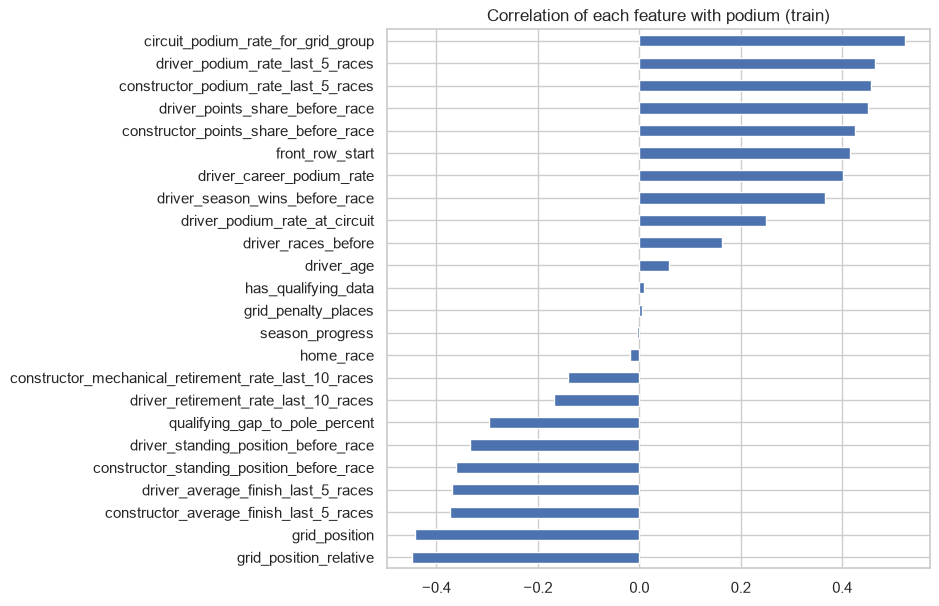

In [176]:
train[features].corrwith(y_train).sort_values().plot(kind='barh', figsize=(7, 7), title='Correlation of each feature with podium (train)')
plt.show()

The grid features, the recent form of driver and team, and the standings are the strongest. `home_race`, `season_progress`, `grid_penalty_places` and `has_qualifying_data` are close to 0 on their own. We keep them anyway and let the ablation in section 8 measure them, because a feature can be weak alone and still help next to others.

The start position is the most direct signal, so we look at it on its own.

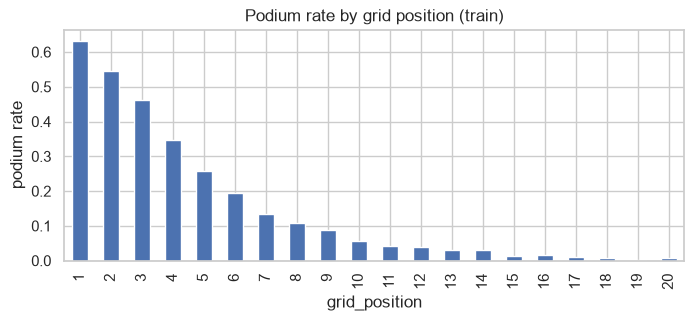

In [177]:
train[train['grid_position'] <= 20].groupby('grid_position')['podium'].mean().plot(kind='bar', figsize=(8, 3), title='Podium rate by grid position (train)')
plt.ylabel('podium rate')
plt.show()

The podium rate falls fast with the grid position and it is not a straight line. This is why we keep `front_row_start` and `circuit_podium_rate_for_grid_group` next to the raw grid position: they help a linear model with the curve.

### 2.2 Features against each other

Two features that say the same thing do not hurt the predictions much, but they make importances harder to read.

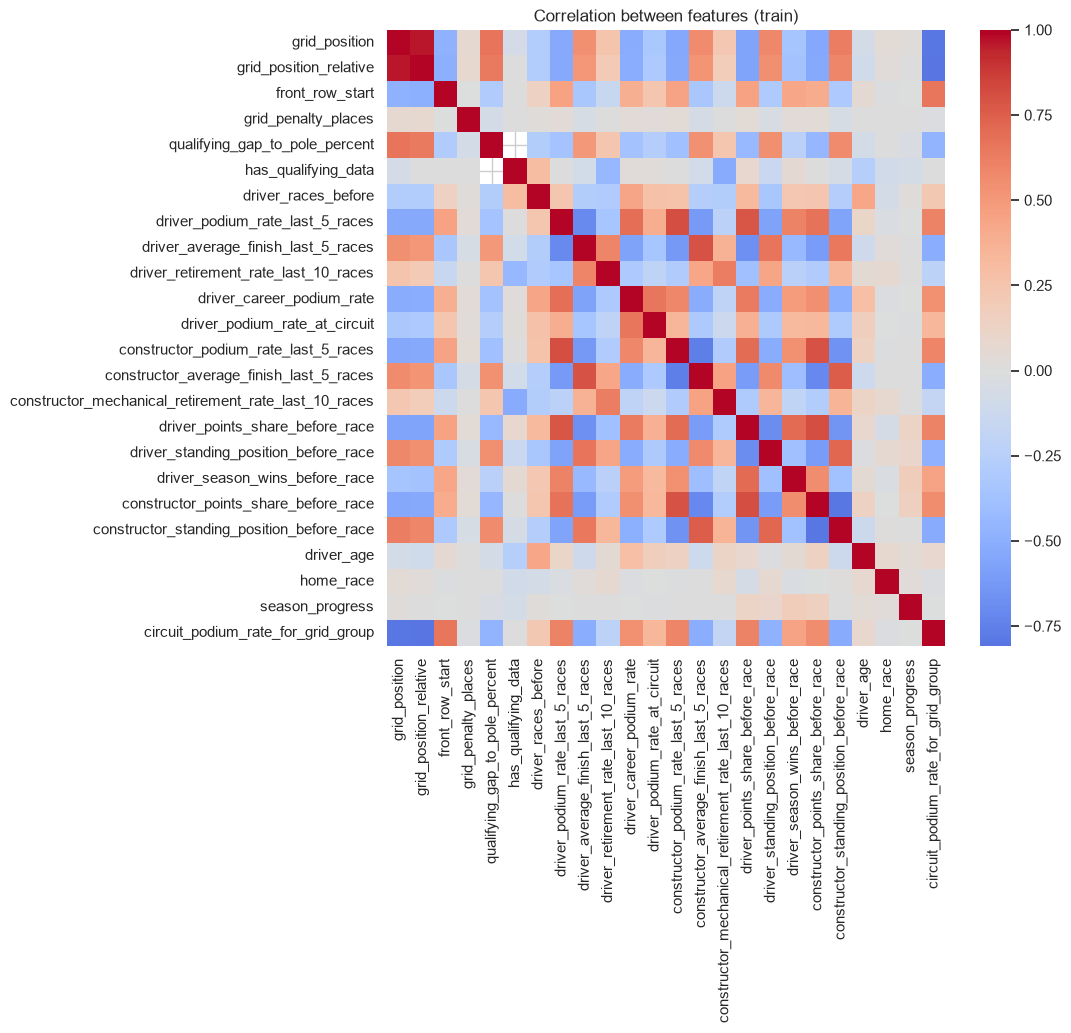

In [178]:
corr = train[features].corr()

plt.figure(figsize=(9, 8))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation between features (train)')
plt.show()

In [179]:
# keep each pair once (upper triangle), then list the strong ones
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
pairs[pairs.abs() > 0.8].round(2)

grid_position                    grid_position_relative                  0.96
grid_position_relative           circuit_podium_rate_for_grid_group     -0.81
driver_podium_rate_last_5_races  constructor_podium_rate_last_5_races    0.81
driver_points_share_before_race  constructor_points_share_before_race    0.81
dtype: float64

Four pairs are above 0.8:

- `grid_position` and `grid_position_relative` (0.96) are almost the same number. Section 8.2 tests whether we need both.
- `circuit_podium_rate_for_grid_group` is built from the grid group, so it follows the grid.
- Driver and constructor form (and driver and constructor points) move together, because a driver's results are also his team's results.

So the groups overlap. We should expect that removing one group costs little, since another group can stand in for it.

## 3. Pre-processing

### 3.1 Missing values

Part 1 left the missing values empty on purpose. We count them per split.

In [180]:
missing = pd.DataFrame({'train': train[features].isna().sum(), 'val': val[features].isna().sum(), 'test': test[features].isna().sum()})
missing[missing['train'] > 0]

,train,val,test
qualifying_gap_to_pole_percent,14284,9,13
driver_podium_rate_last_5_races,667,6,8
driver_average_finish_last_5_races,667,6,8
driver_retirement_rate_last_10_races,667,6,8
driver_career_podium_rate,667,6,8
driver_podium_rate_at_circuit,7058,218,168
constructor_podium_rate_last_5_races,256,4,2
constructor_average_finish_last_5_races,256,4,2
constructor_mechanical_retirement_rate_last_10_races,256,4,2
driver_standing_position_before_race,2778,43,68


13 features have missing values. The big one is `qualifying_gap_to_pole_percent`: empty in 14,284 training rows (no lap times in the old seasons) but almost complete in validation and test.

We fill every missing value with the **median of the training rows**. Median and not mean, because several of these features are skewed. The medians are learned from train only and reused for validation and test, so no information flows back from the later seasons.

In [181]:
medians = train[features].median()

X_train = train[features].fillna(medians)
X_val = val[features].fillna(medians)
X_test = test[features].fillna(medians)

print(X_train.isna().sum().sum(), X_val.isna().sum().sum(), X_test.isna().sum().sum())

0 0 0


No missing values are left. Now the effect on the feature that was filled the most.

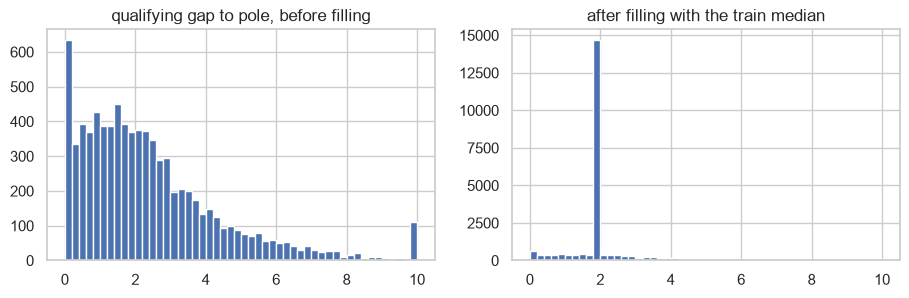

In [182]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
train['qualifying_gap_to_pole_percent'].clip(upper=10).hist(bins=50, ax=ax[0])
ax[0].set_title('qualifying gap to pole, before filling')
X_train['qualifying_gap_to_pole_percent'].clip(upper=10).hist(bins=50, ax=ax[1])
ax[1].set_title('after filling with the train median')
plt.show()

Filling puts 14,284 rows on one value, so the feature now has a tall spike at the median. For those rows it carries no information, which is fine: `has_qualifying_data` tells the model which races had qualifying data. We test adding more "was missing" flags in section 8.

### 3.2 Scaling

The features have very different ranges.

In [183]:
X_train.describe().T[['mean', 'std', 'min', 'max']].round(2)

,mean,std,min,max
grid_position,11.91,6.81,1.00,34.0
grid_position_relative,0.52,0.29,0.03,1.0
front_row_start,0.09,0.28,0.00,1.0
grid_penalty_places,-0.00,0.85,-9.00,23.0
qualifying_gap_to_pole_percent,2.16,1.57,0.00,37.8
has_qualifying_data,0.37,0.48,0.00,1.0
driver_races_before,61.45,61.59,0.00,321.0
driver_podium_rate_last_5_races,0.13,0.23,0.00,1.0
driver_average_finish_last_5_races,11.75,4.36,1.00,31.0
driver_retirement_rate_last_10_races,0.42,0.25,0.00,1.0


`driver_races_before` goes up to a few hundred while the rates stay between 0 and 1. Logistic regression (with its penalty) and the neural network both work better when the features are on the same scale, so we standardise: subtract the mean and divide by the standard deviation.

The mean and standard deviation come from the **training rows only**, like the medians.

In [184]:
mean = X_train.mean()
std = X_train.std()

X_train_s = (X_train - mean) / std
X_val_s = (X_val - mean) / std
X_test_s = (X_test - mean) / std

X_train_s.describe().T[['mean', 'std', 'min', 'max']].round(2)

,mean,std,min,max
grid_position,-0.0,1.0,-1.60,3.24
grid_position_relative,-0.0,1.0,-1.71,1.66
front_row_start,-0.0,1.0,-0.31,3.20
grid_penalty_places,0.0,1.0,-10.59,27.07
qualifying_gap_to_pole_percent,-0.0,1.0,-1.37,22.66
has_qualifying_data,-0.0,1.0,-0.77,1.30
driver_races_before,-0.0,1.0,-1.00,4.21
driver_podium_rate_last_5_races,0.0,1.0,-0.57,3.71
driver_average_finish_last_5_races,0.0,1.0,-2.47,4.42
driver_retirement_rate_last_10_races,0.0,1.0,-1.69,2.38


Every feature now has mean 0 and standard deviation 1 on train. The shape of each distribution is the same as before, only the axis changed.

Tree models split on thresholds, so scaling changes nothing for them. They get the filled, unscaled table (`X_train`), which keeps their plots in real units. Logistic regression and the neural network get the scaled table (`X_train_s`). All models use the **same rows, the same 24 features and the same filled values**.

## 4. Metrics and the baseline

We report five metrics for every model:

| Metric | What it tells us |
|---|---|
| ROC-AUC | How well the model ranks podium rows above the others, over all thresholds. |
| PR-AUC | The same, but it only looks at precision and recall of the podium class. |
| F1 | Balance of precision and recall at one threshold. |
| Precision | Of the rows we call podium, how many are. |
| Recall | Of the real podiums, how many we find. |

- **Primary metric: PR-AUC.** Only 14% of the rows are podiums. ROC-AUC also rewards the model for the many easy "no podium" rows at the back of the grid, so it looks high for every model. PR-AUC only moves when the podium rows are ranked better.
- **Secondary metric: ROC-AUC**, to compare with other work, and **F1** for the final yes/no decision.

F1, precision and recall need a threshold. The default 0.5 is a poor choice with rare positives, so for each model we take the threshold with the **best F1 on the validation set**. The test set is never used for this.

These steps are the same for every model, so they go in three small functions.

In [185]:
results = []      # one row per model and split
thresholds = {}   # the chosen threshold of each model
cols = ['model', 'split', 'roc_auc', 'pr_auc', 'f1', 'precision', 'recall']

def best_threshold(y, p):
    # the threshold with the highest F1
    precision, recall, cuts = precision_recall_curve(y, p)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    return cuts[f1[:-1].argmax()]

def add_scores(name, split, y, p):
    pred = (p >= thresholds[name]).astype(int)
    results.append([name, split, roc_auc_score(y, p), average_precision_score(y, p), f1_score(y, pred), precision_score(y, pred), recall_score(y, pred)])

def evaluate(name, p_train, p_val):
    # pick the threshold on validation, then score train and validation
    thresholds[name] = best_threshold(y_val, p_val)
    add_scores(name, 'train', y_train, p_train)
    add_scores(name, 'val', y_val, p_val)
    return pd.DataFrame(results[-2:], columns=cols).round(3)

### 4.1 Baseline without a model: the grid rule

The simplest idea is "the cars at the front finish at the front". We use `1 / grid_position` as the score, so pole gets 1, second gets 0.5, and so on. Any model must beat this to be worth training.

In [186]:
evaluate('Grid rule', 1 / train['grid_position'], 1 / val['grid_position'])

,model,split,roc_auc,pr_auc,f1,precision,recall
0,Grid rule,train,0.883,0.500,0.544,0.547,0.541
1,Grid rule,val,0.910,0.648,0.695,0.698,0.692


In [187]:
1 / thresholds['Grid rule']

np.float64(3.0)

The best threshold is `grid_position <= 3`: "the top 3 on the grid are the podium". This rule alone already gets a PR-AUC of 0.65 and an F1 of 0.70 on validation. That is the bar for every model below.

The scores are higher on validation than on train. This will be true for every model: the training rows go back to 1950, when races were less predictable (more retirements, bigger fields), and the validation rows are modern races.

## 5. Statistical models

### 5.1 Logistic regression (the baseline model)

**How it works:** it multiplies each feature by a weight, adds them up, and squeezes the sum into a probability between 0 and 1. Training finds the weights.

**Limits:** each feature can only push the probability up or down in one direction, and features cannot interact unless we build the interaction ourselves.

It is the simplest reasonable model for a yes/no target, so it is our baseline. First with the default settings.

In [188]:
lr = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)

evaluate('Logistic regression', lr.predict_proba(X_train_s)[:, 1], lr.predict_proba(X_val_s)[:, 1])

,model,split,roc_auc,pr_auc,f1,precision,recall
0,Logistic regression,train,0.901,0.578,0.585,0.481,0.748
1,Logistic regression,val,0.931,0.746,0.713,0.646,0.795


The main setting is `C`, the strength of the penalty on the weights (small `C` = strong penalty). We try four values and compare PR-AUC on validation.

In [189]:
rows = []
for C in [0.01, 0.1, 1, 10]:
    m = LogisticRegression(C=C, max_iter=1000).fit(X_train_s, y_train)
    rows.append([C, average_precision_score(y_train, m.predict_proba(X_train_s)[:, 1]), average_precision_score(y_val, m.predict_proba(X_val_s)[:, 1])])

pd.DataFrame(rows, columns=['C', 'train_pr_auc', 'val_pr_auc']).round(4)

,C,train_pr_auc,val_pr_auc
0,0.01,0.5764,0.7477
1,0.10,0.5772,0.7470
2,1.00,0.5776,0.7459
3,10.00,0.5776,0.7459


With the default settings the logistic regression reaches a PR-AUC of 0.746 on validation, against 0.648 for the grid rule. Train and validation move together, so it does not overfit.

`C` changes almost nothing: the four values are within 0.002 of each other on validation. That is far too small to mean anything with 117 validation podiums, so we keep the default `C = 1`.

### 5.2 Random forest

**How it works:** it grows many decision trees, each on a random sample of the rows and with a random choice of features at every split, and averages their votes.

**Why try it:** trees handle curves and interactions on their own (for example "front of the grid **and** a strong team").

**Limits:** deep trees memorise the training rows, and a forest cannot predict outside what it has seen.

First with the default settings (300 trees so the result is stable).

In [190]:
rf_default = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X_train, y_train)

print('train PR-AUC:', round(average_precision_score(y_train, rf_default.predict_proba(X_train)[:, 1]), 3))
print('val PR-AUC:  ', round(average_precision_score(y_val, rf_default.predict_proba(X_val)[:, 1]), 3))

train PR-AUC: 1.0
val PR-AUC:   0.685


The default forest is perfect on train and clearly worse on validation: it **overfits**. The default trees grow until every leaf is pure. We limit the depth and look again.

In [191]:
rows = []
for depth in [3, 5, 10, None]:
    m = RandomForestClassifier(n_estimators=300, max_depth=depth, random_state=42, n_jobs=-1).fit(X_train, y_train)
    rows.append([depth, average_precision_score(y_train, m.predict_proba(X_train)[:, 1]), average_precision_score(y_val, m.predict_proba(X_val)[:, 1])])

pd.DataFrame(rows, columns=['max_depth', 'train_pr_auc', 'val_pr_auc']).round(4)

,max_depth,train_pr_auc,val_pr_auc
0,3.0,0.5874,0.7330
1,5.0,0.6119,0.7324
2,10.0,0.8401,0.7008
3,NaN,1.0000,0.6850


The shallower the trees, the lower the train score and the **higher** the validation score. Depth 3 and depth 5 are the same on validation (0.733 and 0.732) and both are clearly better than the default (0.685). We take `max_depth = 5`.

In [192]:
rf = RandomForestClassifier(n_estimators=300, max_depth=5, random_state=42, n_jobs=-1).fit(X_train, y_train)

evaluate('Random forest', rf.predict_proba(X_train)[:, 1], rf.predict_proba(X_val)[:, 1])

,model,split,roc_auc,pr_auc,f1,precision,recall
0,Random forest,train,0.909,0.612,0.599,0.511,0.724
1,Random forest,val,0.932,0.732,0.716,0.657,0.786


### 5.3 Gradient boosting

**How it works:** it also uses trees, but builds them one after the other. Each new small tree corrects the mistakes of the trees before it.

**Limits:** more settings to tune than a forest, and with too many trees it starts to fit noise.

We try a few sizes. The first row is the default.

In [193]:
rows = []
for n, depth in [(100, 3), (100, 2), (300, 2), (300, 3)]:
    m = GradientBoostingClassifier(n_estimators=n, max_depth=depth, random_state=42).fit(X_train, y_train)
    rows.append([n, depth, average_precision_score(y_train, m.predict_proba(X_train)[:, 1]), average_precision_score(y_val, m.predict_proba(X_val)[:, 1])])

pd.DataFrame(rows, columns=['n_estimators', 'max_depth', 'train_pr_auc', 'val_pr_auc']).round(4)

,n_estimators,max_depth,train_pr_auc,val_pr_auc
0,100,3,0.6568,0.7244
1,100,2,0.6121,0.7122
2,300,2,0.6532,0.7207
3,300,3,0.7358,0.7153


The default (100 trees of depth 3) is the best on validation. More trees raise the train score but not the validation score, which is overfitting again. We keep the default.

In [194]:
gb = GradientBoostingClassifier(random_state=42).fit(X_train, y_train)

evaluate('Gradient boosting', gb.predict_proba(X_train)[:, 1], gb.predict_proba(X_val)[:, 1])

,model,split,roc_auc,pr_auc,f1,precision,recall
0,Gradient boosting,train,0.916,0.657,0.613,0.539,0.712
1,Gradient boosting,val,0.928,0.724,0.725,0.707,0.744


## 6. Shallow neural network

**How it works:** each hidden unit is a small logistic regression. A hidden layer has several of them, and the output unit combines them into one probability. With no hidden layer the network would be exactly a logistic regression.

**Limits:** the result changes with the random start, it needs scaled inputs, and it is harder to explain than a list of weights.

We use Keras. The training steps are the same for every network we try, so they go in one function:

- `relu` hidden layers and one `sigmoid` output, because the target is yes/no
- `binary_crossentropy` loss with the `adam` optimiser (the standard pair for this)
- **early stopping**: training stops when the validation loss has not improved for 10 epochs, and the best weights are kept. This picks the number of epochs for us and limits overfitting.
- a fixed seed so Run All gives the same result

In [195]:
def train_nn(hidden, dropout, seed):
    keras.utils.set_random_seed(seed)
    nn = keras.Sequential([keras.Input(shape=(len(features),))])
    for units in hidden:
        nn.add(layers.Dense(units, activation='relu'))
        nn.add(layers.Dropout(dropout))
    nn.add(layers.Dense(1, activation='sigmoid'))
    nn.compile(optimizer='adam', loss='binary_crossentropy')
    stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)
    history = nn.fit(X_train_s, y_train, validation_data=(X_val_s, y_val), epochs=100, batch_size=64, verbose=0, callbacks=[stop])
    return nn, history

### 6.1 One hidden layer

The smallest network: one hidden layer with 16 units and no dropout.

In [196]:
nn1, history1 = train_nn([16], 0, 42)
nn1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,253 (4.90 KB)

 Trainable params: 417 (1.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 836 (3.27 KB)

In [197]:
evaluate('NN 1 layer (16)', nn1.predict(X_train_s, verbose=0).ravel(), nn1.predict(X_val_s, verbose=0).ravel())

,model,split,roc_auc,pr_auc,f1,precision,recall
0,NN 1 layer (16),train,0.909,0.601,0.591,0.486,0.752
1,NN 1 layer (16),val,0.930,0.727,0.723,0.682,0.769


### 6.2 Two hidden layers with dropout

A bit bigger: 32 and 16 units. A bigger network overfits more easily, so we add dropout of 0.2 (during training, 20% of the units are switched off at random in each step).

In [198]:
nn2, history2 = train_nn([32, 16], 0.2, 42)

evaluate('NN 2 layers (32-16)', nn2.predict(X_train_s, verbose=0).ravel(), nn2.predict(X_val_s, verbose=0).ravel())

,model,split,roc_auc,pr_auc,f1,precision,recall
0,NN 2 layers (32-16),train,0.909,0.600,0.599,0.510,0.726
1,NN 2 layers (32-16),val,0.931,0.751,0.713,0.677,0.752


The loss per epoch for both networks.

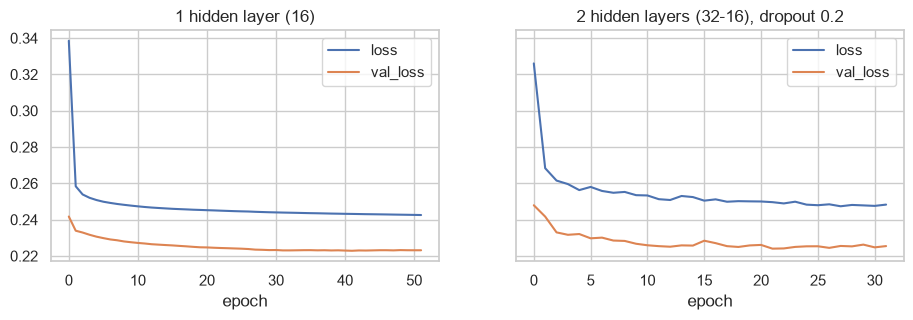

In [199]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
pd.DataFrame(history1.history).plot(ax=ax[0], title='1 hidden layer (16)')
pd.DataFrame(history2.history).plot(ax=ax[1], title='2 hidden layers (32-16), dropout 0.2')
ax[0].set_xlabel('epoch')
ax[1].set_xlabel('epoch')
plt.show()

Both networks stop on their own after 30 to 50 epochs, and the train and validation curves stay flat next to each other, so there is no sign of overfitting. The validation loss is **below** the train loss for the same reason as before: the modern validation races are easier to predict than the full 1950-2019 training set.

The two-layer network scores a little higher on validation PR-AUC (0.751 against 0.727).

### 6.3 How much does the random start matter?

A network starts from random weights. We train the two-layer network again with three other seeds to see how far the validation score moves from the seed alone.

In [200]:
rows = []
for seed in [1, 2, 3]:
    m, h = train_nn([32, 16], 0.2, seed)
    p = m.predict(X_val_s, verbose=0).ravel()
    rows.append([seed, roc_auc_score(y_val, p), average_precision_score(y_val, p)])

pd.DataFrame(rows, columns=['seed', 'val_roc_auc', 'val_pr_auc']).round(4)

,seed,val_roc_auc,val_pr_auc
0,1,0.9285,0.7438
1,2,0.9306,0.7497
2,3,0.9310,0.7469


With the same data and the same network, the validation PR-AUC moves between about 0.744 and 0.751 just from the random start. On another machine the numbers can shift by a similar amount.

This gives us a feel for the noise: **a difference of less than about 0.01 in validation PR-AUC between two models is not a real difference.**

## 7. Model comparison

Everything so far was chosen with train and validation only. Now we score the final version of each model on the test set (2022-2024), **once**, with the thresholds picked on validation.

In [201]:
p_test = {
    'Grid rule': 1 / test['grid_position'],
    'Logistic regression': lr.predict_proba(X_test_s)[:, 1],
    'Random forest': rf.predict_proba(X_test)[:, 1],
    'Gradient boosting': gb.predict_proba(X_test)[:, 1],
    'NN 1 layer (16)': nn1.predict(X_test_s, verbose=0).ravel(),
    'NN 2 layers (32-16)': nn2.predict(X_test_s, verbose=0).ravel(),
}
for name, p in p_test.items():
    add_scores(name, 'test', y_test, p)

table = pd.DataFrame(results, columns=cols)
table['threshold'] = table['model'].map(thresholds)

### Validation

In [202]:
table[table['split'] == 'val'].drop(columns='split').set_index('model').round(3)

,roc_auc,pr_auc,f1,precision,recall,threshold
model,,,,,,
Grid rule,0.910,0.648,0.695,0.698,0.692,0.333
Logistic regression,0.931,0.746,0.713,0.646,0.795,0.233
Random forest,0.932,0.732,0.716,0.657,0.786,0.272
Gradient boosting,0.928,0.724,0.725,0.707,0.744,0.309
NN 1 layer (16),0.930,0.727,0.723,0.682,0.769,0.266
NN 2 layers (32-16),0.931,0.751,0.713,0.677,0.752,0.319


### Test (unseen)

In [203]:
table[table['split'] == 'test'].drop(columns='split').set_index('model').round(3)

,roc_auc,pr_auc,f1,precision,recall,threshold
model,,,,,,
Grid rule,0.913,0.647,0.649,0.650,0.647,0.333
Logistic regression,0.936,0.723,0.676,0.551,0.873,0.233
Random forest,0.941,0.719,0.669,0.566,0.819,0.272
Gradient boosting,0.939,0.695,0.691,0.625,0.775,0.309
NN 1 layer (16),0.934,0.717,0.662,0.579,0.775,0.266
NN 2 layers (32-16),0.937,0.715,0.676,0.592,0.789,0.319


### Train (to see overfitting)

In [204]:
table[table['split'] == 'train'].drop(columns='split').set_index('model').round(3)

,roc_auc,pr_auc,f1,precision,recall,threshold
model,,,,,,
Grid rule,0.883,0.500,0.544,0.547,0.541,0.333
Logistic regression,0.901,0.578,0.585,0.481,0.748,0.233
Random forest,0.909,0.612,0.599,0.511,0.724,0.272
Gradient boosting,0.916,0.657,0.613,0.539,0.712,0.309
NN 1 layer (16),0.909,0.601,0.591,0.486,0.752,0.266
NN 2 layers (32-16),0.909,0.600,0.599,0.510,0.726,0.319


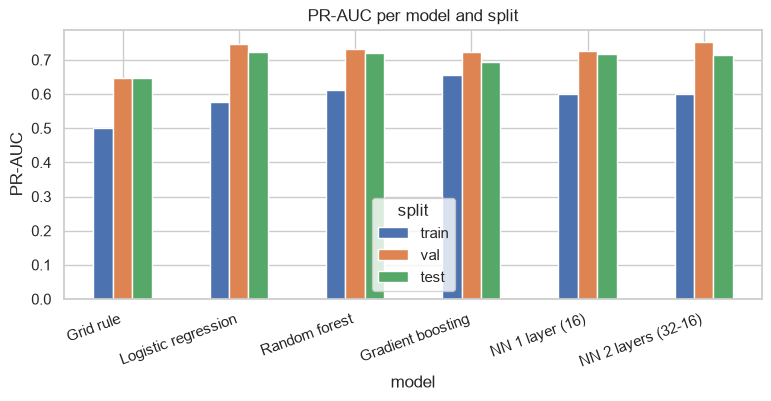

In [205]:
table.pivot(index='model', columns='split', values='pr_auc')[['train', 'val', 'test']].loc[list(p_test)].plot(kind='bar', figsize=(9, 3.5), title='PR-AUC per model and split')
plt.ylabel('PR-AUC')
plt.xticks(rotation=20, ha='right')
plt.show()

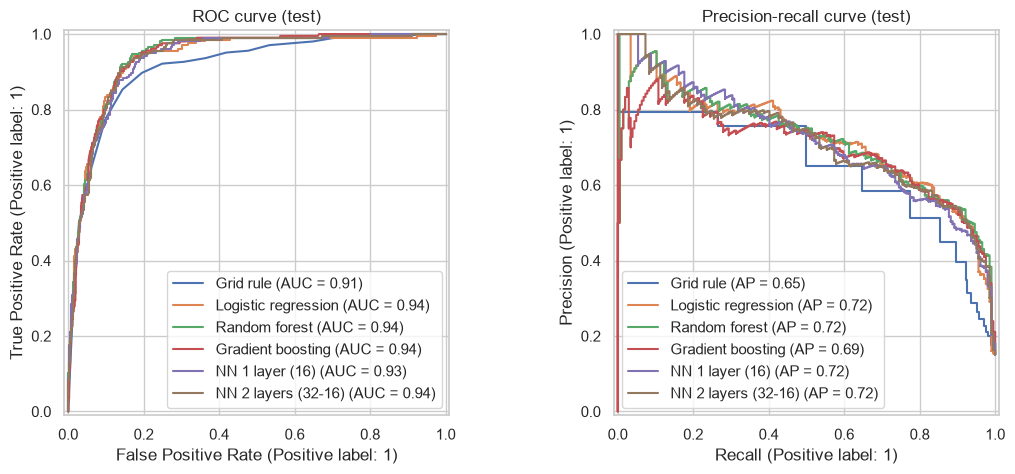

In [206]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, p in p_test.items():
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=ax[0])
    PrecisionRecallDisplay.from_predictions(y_test, p, name=name, ax=ax[1])
ax[0].set_title('ROC curve (test)')
ax[1].set_title('Precision-recall curve (test)')
plt.show()

**What we see**

- **Every model beats the grid rule.** On test, PR-AUC goes from 0.647 to about 0.70-0.72. The other features add real information on top of the start position.
- **The models are very close to each other.** On validation the PR-AUC runs from 0.724 to 0.751, and on test from 0.695 to 0.723. Section 6.3 showed that the seed alone moves a network by about 0.01, so we cannot call a winner among logistic regression, random forest and the networks.
- **Gradient boosting is the lowest** on PR-AUC on both validation and test, although it has the highest train score. Its closer fit to the training seasons did not carry over.
- **No overfitting in the final models:** validation and test scores are at or above the train scores.
- **Thresholds carry over well.** The F1 on test (0.66-0.69) is a bit lower than on validation (0.71-0.73), which is expected because the thresholds were tuned on validation.

**Final model: logistic regression.** We chose it from the validation column: it is tied with the best network (0.746 against 0.751, inside the seed noise), and when models are tied we take the simplest one. It trains in a second, gives the same result on every run, and its weights can be read directly. The more complex models did not earn their extra complexity on this table. The test column then confirms the choice (PR-AUC 0.723, ROC-AUC 0.936), but it was not used to make it.

**Why did the complex models not win?** The features already do the hard work: form, standings and the circuit rate are built by hand in Part 1, so there is little left for trees or hidden layers to discover. The modern training data is also small (20 cars per race).

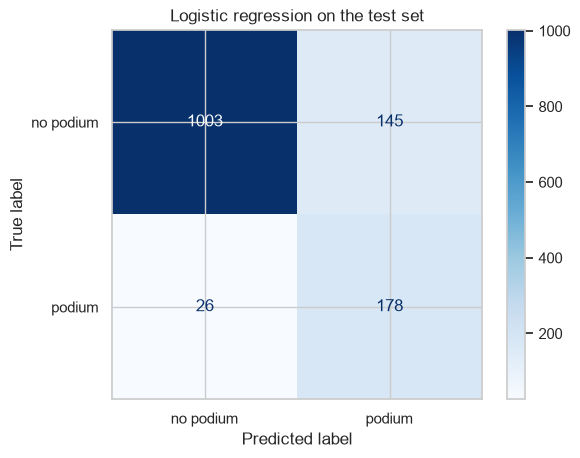

In [207]:
final_name = 'Logistic regression'
threshold = thresholds[final_name]

ConfusionMatrixDisplay.from_predictions(y_test, (p_test[final_name] >= threshold).astype(int), display_labels=['no podium', 'podium'], cmap='Blues')
plt.title('Logistic regression on the test set')
plt.show()

At the validation threshold of 0.23 the model finds 178 of the 204 test podiums (recall 0.87) and raises 145 false alarms (precision 0.55). The threshold is low because it maximises F1 with rare positives: the model names about 5 candidates per race for 3 podium places. A user who wants fewer false alarms can raise the threshold and trade recall for precision along the curve above.

## 8. Experiments

All experiments use the same recipe: change one thing, train again, compare PR-AUC with the full pipeline. We use logistic regression because it is the final model, it trains in a second, and it gives the same result on every run. The same lines are repeated in every experiment, so they go in a function.

We show validation **and** test because validation is small (117 podiums). The test column is only reported. No choice in this part is made from it.

In [208]:
def lr_pr_auc(X_a, y_a, X_b, X_c):
    # fit a logistic regression on X_a, return PR-AUC on validation (X_b) and test (X_c)
    m = LogisticRegression(max_iter=1000).fit(X_a, y_a)
    return [average_precision_score(y_val, m.predict_proba(X_b)[:, 1]), average_precision_score(y_test, m.predict_proba(X_c)[:, 1])]

full = lr_pr_auc(X_train_s, y_train, X_val_s, X_test_s)
full

[0.7459006979594693, 0.7232688610530509]

### 8.1 Feature-group ablation

We remove one group of features at a time, train again, and see how much PR-AUC drops. The groups are the ones from Part 1.

In [209]:
groups = {
    'grid': ['grid_position', 'grid_position_relative', 'front_row_start'],
    'qualifying': ['grid_penalty_places', 'qualifying_gap_to_pole_percent', 'has_qualifying_data'],
    'driver form': ['driver_races_before', 'driver_podium_rate_last_5_races', 'driver_average_finish_last_5_races', 'driver_retirement_rate_last_10_races', 'driver_career_podium_rate', 'driver_podium_rate_at_circuit'],
    'constructor form': ['constructor_podium_rate_last_5_races', 'constructor_average_finish_last_5_races', 'constructor_mechanical_retirement_rate_last_10_races'],
    'standings': ['driver_points_share_before_race', 'driver_standing_position_before_race', 'driver_season_wins_before_race', 'constructor_points_share_before_race', 'constructor_standing_position_before_race'],
    'context': ['driver_age', 'home_race', 'season_progress', 'circuit_podium_rate_for_grid_group'],
}
sum(len(g) for g in groups.values())

24

All 24 features are in exactly one group. We run the ablation for logistic regression and, as a second opinion, for the random forest.

In [210]:
rf_full = average_precision_score(y_val, rf.predict_proba(X_val)[:, 1])

rows = []
for name, group in groups.items():
    keep = [f for f in features if f not in group]
    lr_scores = lr_pr_auc(X_train_s[keep], y_train, X_val_s[keep], X_test_s[keep])
    m = RandomForestClassifier(n_estimators=300, max_depth=5, random_state=42, n_jobs=-1).fit(X_train[keep], y_train)
    rf_score = average_precision_score(y_val, m.predict_proba(X_val[keep])[:, 1])
    rows.append([name, len(keep), full[0] - lr_scores[0], full[1] - lr_scores[1], rf_full - rf_score])

ablation = pd.DataFrame(rows, columns=['removed group', 'features left', 'LR val drop', 'LR test drop', 'RF val drop']).set_index('removed group')
ablation.round(4)

,features left,LR val drop,LR test drop,RF val drop
removed group,,,,
grid,21,-0.0113,0.0215,0.0084
qualifying,21,0.0035,0.0012,0.0090
driver form,18,0.0081,-0.0016,0.0061
constructor form,21,-0.0093,0.0065,-0.0044
standings,19,0.0068,0.0089,0.0122
context,20,0.0125,0.0001,0.0084


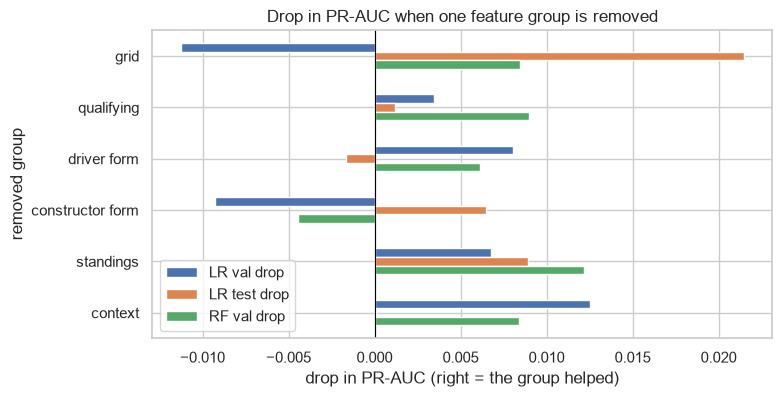

In [211]:
ablation[['LR val drop', 'LR test drop', 'RF val drop']].plot(kind='barh', figsize=(8, 4), title='Drop in PR-AUC when one feature group is removed')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('drop in PR-AUC (right = the group helped)')
plt.gca().invert_yaxis()
plt.show()

**No single group is essential.** Every drop is below about 0.02, and several are negative (the score went up without the group). The sign also flips between validation and test: removing the grid group *helps* on validation (-0.011) and *hurts* on test (+0.022). With the noise level from section 6.3 (about 0.01), most of these bars cannot be told apart from zero.

What we can say:

- **Standings** and **qualifying** are the only groups whose removal costs something in all three columns, and even there the drop is at most 0.012.
- **Grid** gives the largest single drop (0.022 on test), but not on validation.
- The small drops do not mean the groups are useless. They overlap (section 2.2), so when one is removed the others fill in. For example, without the three grid features the model still has `circuit_podium_rate_for_grid_group`, which is built from the grid.

Removing a group shows little when another group carries the same information. So we also turn it around: train on **one group alone**.

In [212]:
rows = []
for name, group in groups.items():
    rows.append([name] + lr_pr_auc(X_train_s[group], y_train, X_val_s[group], X_test_s[group]))
rows.append(['all features'] + full)

alone = pd.DataFrame(rows, columns=['only this group', 'val_pr_auc', 'test_pr_auc']).set_index('only this group')
alone.round(4)

,val_pr_auc,test_pr_auc
only this group,,
grid,0.6552,0.6582
qualifying,0.6392,0.6065
driver form,0.6525,0.5188
constructor form,0.5340,0.5085
standings,0.6612,0.5619
context,0.6353,0.5744
all features,0.7459,0.7233


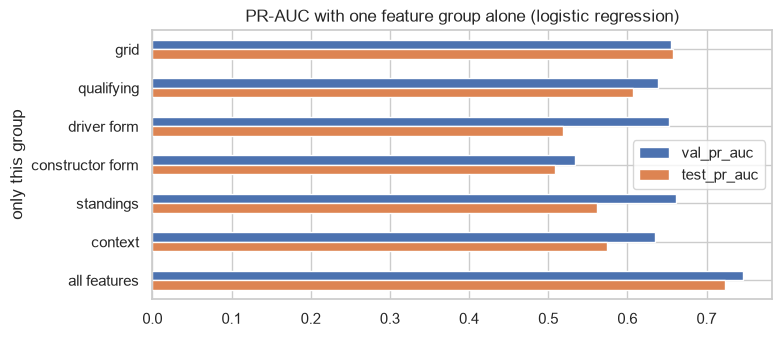

In [213]:
alone.plot(kind='barh', figsize=(8, 3.5), title='PR-AUC with one feature group alone (logistic regression)')
plt.gca().invert_yaxis()
plt.show()

This view is clearer. Every group alone is far below the full model (0.746 on validation, 0.723 on test), so **the gain comes from combining groups**, not from one of them.

- **Grid alone** is the strongest and the most stable (0.655 validation, 0.658 test), close to the grid rule.
- **Standings and driver form alone** look as good as grid on validation but fall to 0.52-0.56 on test. They describe who has been strong so far, which says less in some seasons than in others.
- **Constructor form alone** is the weakest.

Together with the ablation: grid is the core signal, and the form, standings, qualifying and context groups each add a small, overlapping part on top of it. We keep all six groups.

### 8.2 Grid position: absolute, relative, or both?

Part 1 kept both `grid_position` (1, 2, 3, ...) and `grid_position_relative` (grid divided by the number of starters) and left the choice to an experiment. We drop one at a time.

In [214]:
rows = [['both (our pipeline)'] + full]
for drop in ['grid_position', 'grid_position_relative']:
    keep = [f for f in features if f != drop]
    rows.append(['without ' + drop] + lr_pr_auc(X_train_s[keep], y_train, X_val_s[keep], X_test_s[keep]))

pd.DataFrame(rows, columns=['features', 'val_pr_auc', 'test_pr_auc']).round(4)

,features,val_pr_auc,test_pr_auc
0,both (our pipeline),0.7459,0.7233
1,without grid_position,0.7486,0.7233
2,without grid_position_relative,0.7464,0.7227


No difference: the three rows are within 0.003 of each other. The two columns carry the same information (correlation 0.96), so the model does not need both, and neither version is better than the other. We keep both because dropping one gives no gain, but a smaller table could drop either one.

### 8.3 Which seasons to train on?

F1 in the 1950s was a different sport: other points, shared cars, no qualifying data. Old rows give more data but may teach the model outdated patterns. We compare training on all seasons with training from 1994 and from 2003.

In [215]:
rows = []
for start in [1950, 1994, 2003]:
    mask = train['year'] >= start
    rows.append([start, mask.sum()] + lr_pr_auc(X_train_s[mask], y_train[mask], X_val_s, X_test_s))

pd.DataFrame(rows, columns=['train from', 'train rows', 'val_pr_auc', 'test_pr_auc']).round(4)

,train from,train rows,val_pr_auc,test_pr_auc
0,1950,22444,0.7459,0.7233
1,1994,10091,0.7519,0.7256
2,2003,6782,0.7493,0.7257


Training from 1994 uses less than half of the rows and scores the same or a little higher (0.752 against 0.746 on validation, 0.726 against 0.723 on test). The difference is inside the noise, so we cannot say the old seasons hurt, but they clearly **do not help**: 12,000 rows from before 1994 add nothing for predicting 2020-2024.

We keep all years in the final model, as decided in Part 1, because the result is the same and no rows have to be thrown away. This is the era sensitivity to report as a limitation: the model is scored on modern races, and most of its training rows come from a different kind of F1.

### 8.4 Pre-processing order

Three experiments on the order of the pre-processing steps. Our pipeline is: **split → fill with the train median → scale with the train mean and std**.

#### Experiment A: split first, or pre-process first?

The wrong order is to fill and scale the whole table first and split afterwards. Then the medians, means and standard deviations are computed with the validation and test rows inside, which is a leak. First we look at how different the medians are.

In [216]:
medians_all = df[features].median()
pd.DataFrame({'train only': medians, 'all rows': medians_all})[medians != medians_all].round(3)

,train only,all rows
qualifying_gap_to_pole_percent,1.961,1.836
driver_races_before,41.000,45.000
driver_average_finish_last_5_races,12.000,11.800
constructor_average_finish_last_5_races,11.900,11.800
driver_points_share_before_race,0.047,0.051
constructor_points_share_before_race,0.114,0.116
driver_age,29.544,29.363
season_progress,0.556,0.545
circuit_podium_rate_for_grid_group,0.030,0.029


In [217]:
X_all = df[features].fillna(medians_all)
X_all_s = (X_all - X_all.mean()) / X_all.std()

a_wrong = lr_pr_auc(X_all_s[df['split'] == 'train'], y_train, X_all_s[df['split'] == 'val'], X_all_s[df['split'] == 'test'])
pd.DataFrame([['split first (our pipeline)'] + full, ['pre-process first'] + a_wrong], columns=['order', 'val_pr_auc', 'test_pr_auc']).round(4)

,order,val_pr_auc,test_pr_auc
0,split first (our pipeline),0.7459,0.7233
1,pre-process first,0.7459,0.7235


The scores are the same to three decimals. The medians barely move because the validation and test rows are only 9% of the table, and a median or a mean is one number that a few rows cannot shift much.

So here the wrong order does not buy a better score. We still split first, because it is the only order that is honest: at prediction time the future races do not exist yet, and the inference function in section 10 can only use the training values.

#### Experiment B: fill then scale, or scale then fill?

If we scale first, the mean and standard deviation are computed from the real values only. If we fill first, the filled rows are part of them. For `qualifying_gap_to_pole_percent` that is 14,284 identical values, which shrink the standard deviation.

In [218]:
mean_b = train[features].mean()   # pandas skips the missing values
std_b = train[features].std()
pd.DataFrame({'std, fill first': std, 'std, scale first': std_b}).loc[['qualifying_gap_to_pole_percent', 'driver_podium_rate_at_circuit']].round(3)

,"std, fill first","std, scale first"
qualifying_gap_to_pole_percent,1.573,2.572
driver_podium_rate_at_circuit,0.216,0.248


In [219]:
Xb_train = (train[features] - mean_b) / std_b
medians_b = Xb_train.median()

b_other = lr_pr_auc(Xb_train.fillna(medians_b), y_train, ((val[features] - mean_b) / std_b).fillna(medians_b), ((test[features] - mean_b) / std_b).fillna(medians_b))
pd.DataFrame([['fill then scale (our pipeline)'] + full, ['scale then fill'] + b_other], columns=['order', 'val_pr_auc', 'test_pr_auc']).round(4)

,order,val_pr_auc,test_pr_auc
0,fill then scale (our pipeline),0.7459,0.7233
1,scale then fill,0.7461,0.7236


The standard deviation of the qualifying gap is very different between the two orders (1.57 against 2.57), but the scores are the same. For a logistic regression both orders give the same filled column, only stretched by a different constant, and the model absorbs that in the weight.

The order would matter for a method that fills from other columns (like nearest neighbours) or for a model that is sensitive to the exact scale. We keep fill then scale, because then the scaled table has exactly mean 0 and standard deviation 1.

#### Experiment C: "was missing" flags before or after filling?

A flag column says "this value was missing". It only works if it is made **before** filling. After filling there is nothing left to flag:

In [220]:
flag_cols = ['qualifying_gap_to_pole_percent', 'driver_podium_rate_at_circuit', 'driver_standing_position_before_race']

print('flags made after filling: ', X_train[flag_cols].isna().sum().sum(), 'cells flagged')
print('flags made before filling:', train[flag_cols].isna().sum().sum(), 'cells flagged')

flags made after filling:  0 cells flagged
flags made before filling: 24120 cells flagged


Flags made after filling would be all 0, which is the same as our pipeline without flags. So we compare our pipeline with flags made before filling, for the three features with the most missing values.

In [221]:
Xc_train = X_train_s.copy()
Xc_val = X_val_s.copy()
Xc_test = X_test_s.copy()
for c in flag_cols:
    Xc_train[c + '_missing'] = train[c].isna().astype(int)
    Xc_val[c + '_missing'] = val[c].isna().astype(int)
    Xc_test[c + '_missing'] = test[c].isna().astype(int)

c_flags = lr_pr_auc(Xc_train, y_train, Xc_val, Xc_test)
pd.DataFrame([['no flags / flags after filling (our pipeline)'] + full, ['flags before filling'] + c_flags], columns=['order', 'val_pr_auc', 'test_pr_auc']).round(4)

,order,val_pr_auc,test_pr_auc
0,no flags / flags after filling (our pipeline),0.7459,0.7233
1,flags before filling,0.7446,0.7213


Here the order decides whether the step works at all: after filling, 0 cells can be flagged, before filling 24,120.

The flags themselves do not help: PR-AUC is slightly lower with them (0.745 against 0.746 on validation), again inside the noise. `has_qualifying_data` already covers the biggest case, and a missing circuit history or standings position says little about the podium. We keep the pipeline without extra flags.

**Summary of the three experiments:** the pre-processing order changes the numbers inside the table (medians, standard deviations, flags) but not the score of this model. We keep split → fill → scale because it is leak-free and is the order the inference function can repeat.

## 9. Explainability

We explain the final model, the logistic regression.

**Important:** everything in this section describes **what the model relies on**, not what causes a podium. A high importance for a feature means the predictions change a lot when that feature changes. It does not prove that changing it in the real world would change the result. For example, the model leans on the grid position, but a slow car moved to pole by hand would not become a podium car.

### 9.1 Global: permutation importance

We shuffle one feature in the validation set, which breaks its link with the target, and measure how much PR-AUC drops. A big drop means the model needs that feature. Each feature is shuffled 10 times.

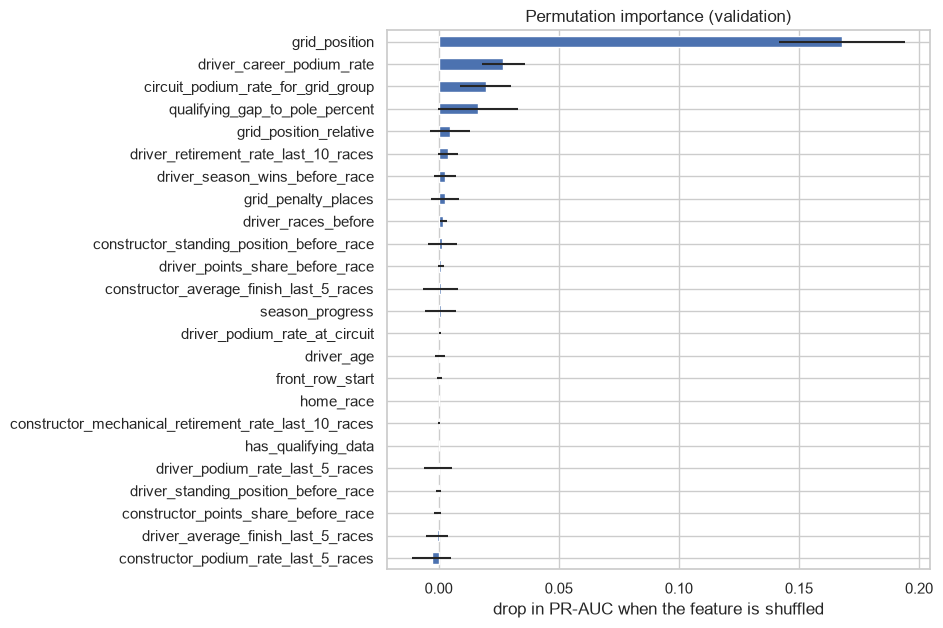

In [222]:
perm = permutation_importance(lr, X_val_s, y_val, scoring='average_precision', n_repeats=10, random_state=42)

perm_table = pd.DataFrame({'drop in PR-AUC': perm.importances_mean, 'std': perm.importances_std}, index=features).sort_values('drop in PR-AUC')
perm_table['drop in PR-AUC'].plot(kind='barh', xerr=perm_table['std'], figsize=(7, 7), title='Permutation importance (validation)')
plt.xlabel('drop in PR-AUC when the feature is shuffled')
plt.show()

`grid_position` stands far above everything else: shuffling it costs about 0.17 PR-AUC. Then come `driver_career_podium_rate`, `circuit_podium_rate_for_grid_group` and `qualifying_gap_to_pole_percent`, each around 0.02. Most other features are at zero, and the black lines (the spread over the 10 shuffles) cross zero.

A feature at zero is not proven useless. When two features carry the same information (driver and constructor form, the two grid columns), shuffling one leaves the other to do the job, so both look small. This matches the ablation.

### 9.2 Global: SHAP

SHAP splits each prediction into one contribution per feature. A positive value pushed this prediction towards podium, a negative value pushed it away. The contributions of a row add up to the model's output for that row (in log-odds, the scale the logistic regression works in).

We compute the values for every validation row.

In [223]:
explainer = shap.LinearExplainer(lr, X_train_s)
shap_values = explainer(X_val_s)
shap_values.data = X_val.values   # show the real values in the plots, not the scaled ones

shap_values.shape

Background dataset has 22444 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=22444 when initializing the masker.


(775, 24)

The mean size of the contributions gives a global ranking.

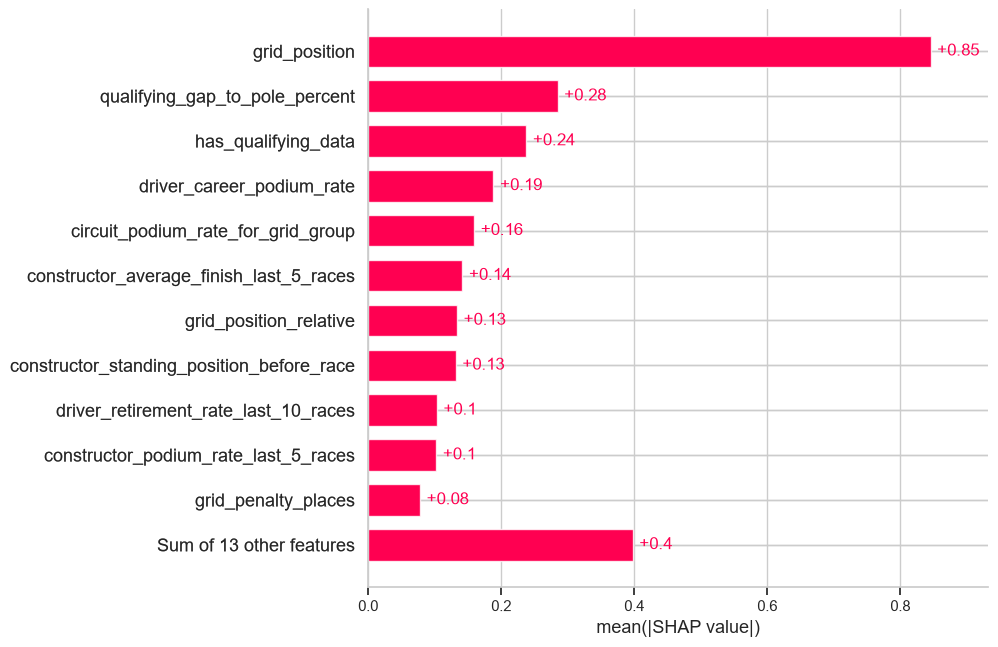

In [224]:
shap.plots.bar(shap_values, max_display=12)

The beeswarm plot shows every validation row as a dot. Red = high value of the feature, blue = low value.

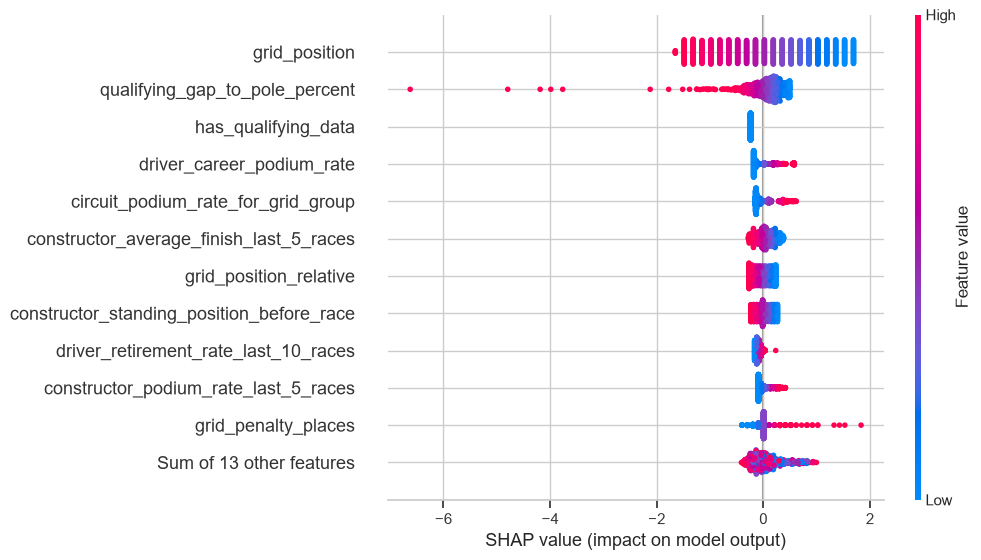

In [225]:
shap.plots.beeswarm(shap_values, max_display=12)

SHAP agrees with permutation importance on the top: `grid_position` has by far the largest contributions, followed by the qualifying gap, the career podium rate and the circuit rate.

Reading the beeswarm:

- `grid_position`: red dots (a start far back) are on the left, blue dots (a start at the front) on the right. The model lowers the podium probability as the grid number grows.
- `qualifying_gap_to_pole_percent`: a few red dots sit very far left. These are drivers with a huge gap to pole. A linear model keeps subtracting for every extra percent, so outliers get extreme values. This is a limit of the model.
- `grid_penalty_places`: red dots on the right. A driver who starts further back than he qualified is faster than his grid slot suggests, and the model gives some of that back.
- `has_qualifying_data` ranks third in the bar plot but is a single blue column: every validation race has qualifying data, so it gives the **same** shift to every row and cannot change the order of the drivers. This is why permutation importance shows it at zero. SHAP measures how far a feature moves the output from the training average, permutation importance measures how much the ranking needs it.

Again: these plots show how **the model** uses the features. They are not effects on the race.

### 9.3 Local: one prediction

We take one row: the driver on pole in the last validation race.

In [226]:
i = np.where((val['raceId'] == val['raceId'].iloc[-1]) & (val['grid_position'] == 1))[0][0]

print('predicted probability:', round(lr.predict_proba(X_val_s.iloc[[i]])[0, 1], 3), '| real podium:', y_val.iloc[i])
val.iloc[i][['raceId', 'driverId', 'year', 'round', 'grid_position', 'driver_podium_rate_last_5_races', 'constructor_podium_rate_last_5_races', 'driver_points_share_before_race']]

predicted probability: 0.852 | real podium: 1


raceId                                  1073
driverId                                 830
year                                    2021
round                                     22
grid_position                              1
driver_podium_rate_last_5_races          1.0
constructor_podium_rate_last_5_races     0.7
driver_points_share_before_race          1.0
Name: 23200, dtype: object

**Local SHAP (waterfall).** It starts from the average output of the model at the bottom and adds the contribution of each feature until it reaches the output for this row at the top.

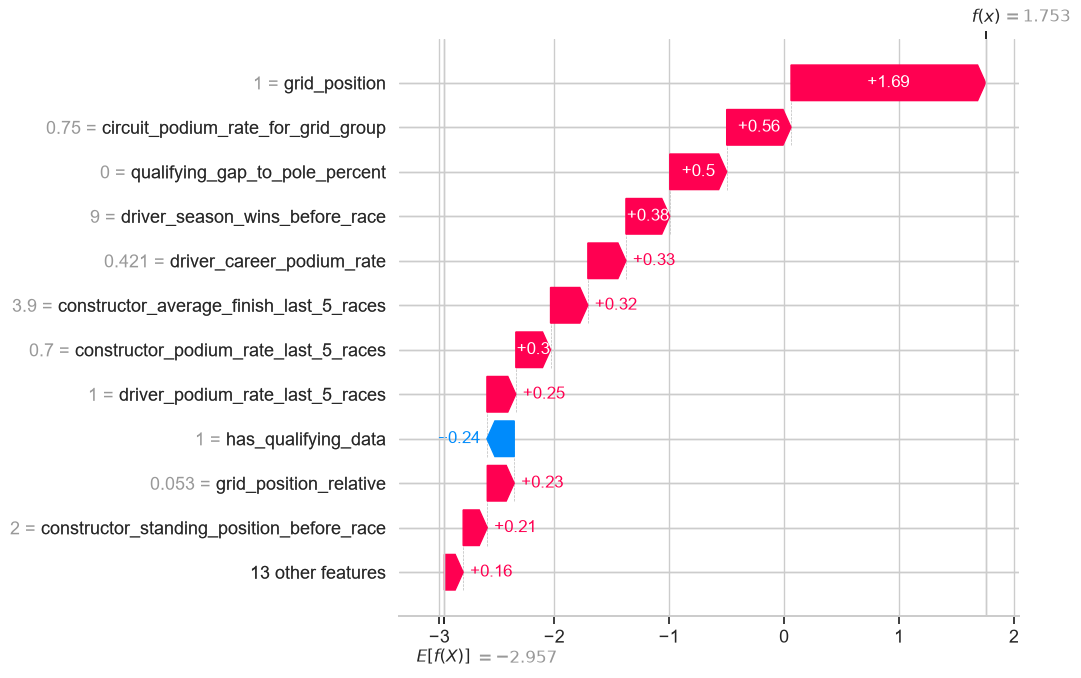

In [227]:
shap.plots.waterfall(shap_values[i], max_display=12)

**LIME.** LIME makes many small random changes to this row, asks the model for a prediction on each, and fits a small linear model on those to see which features matter around this one row.

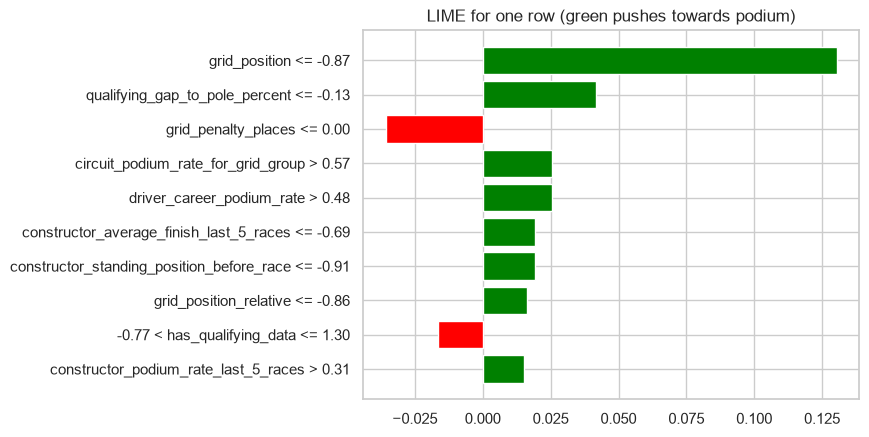

In [228]:
lime_explainer = LimeTabularExplainer(X_train_s.values, feature_names=features, class_names=['no podium', 'podium'], mode='classification', random_state=42)
lime_exp = lime_explainer.explain_instance(X_val_s.iloc[i].values, lambda a: lr.predict_proba(pd.DataFrame(a, columns=features)), num_features=10)

lime_exp.as_pyplot_figure()
plt.title('LIME for one row (green pushes towards podium)')
plt.show()

The row is the pole sitter of the 2021 season finale (round 22). The model gives 0.85 and he did finish on the podium.

- **SHAP:** the model starts from its average output (-2.96 in log-odds, a probability of about 5%) and ends at +1.75 (about 85%). The start from pole adds the most (+1.69). The circuit's podium rate for the front of the grid (0.75), the zero gap to pole, 9 wins this season, his career podium rate and the team's recent results all push up. Only `has_qualifying_data` pushes down, and it does so for every row (see above).
- **LIME** gives the same picture with a different method: the grid position is the longest green bar, then the gap to pole, the circuit rate and the career podium rate. The conditions are in scaled units because the model works on the scaled table (`grid_position <= -0.87` means a start near the front).

The two methods agree on which features drive this prediction, which makes the explanation more trustworthy. Both explain why the model said 0.85. Neither says that these features caused the podium.

## 10. Inference function

One function that takes the pre-race features of one driver in one race and returns the podium probability and the yes/no decision. It repeats the training pipeline with the values learned from train: fill with `medians`, scale with `mean` and `std`, predict with the final model, and compare with the validation `threshold`.

A feature that is not in the record is treated as missing.

In [229]:
def predict_podium(record):
    row = pd.DataFrame([record], columns=features).astype(float)   # features not in the record become NaN
    row = row.fillna(medians)
    row = (row - mean) / std
    p = lr.predict_proba(row)[0, 1]
    return round(float(p), 3), int(p >= threshold)

**A complete record.** We take a test row that has every feature.

In [230]:
record = test.dropna()[features].iloc[0].to_dict()
record

{'grid_position': 4.0,
 'grid_position_relative': 0.2105263157894736,
 'front_row_start': 0.0,
 'grid_penalty_places': 0.0,
 'qualifying_gap_to_pole_percent': 0.2959183673469256,
 'has_qualifying_data': 1.0,
 'driver_races_before': 142.0,
 'driver_podium_rate_last_5_races': 0.8,
 'driver_average_finish_last_5_races': 5.2,
 'driver_retirement_rate_last_10_races': 0.2,
 'driver_career_podium_rate': 0.4225352112676056,
 'driver_podium_rate_at_circuit': 1.0,
 'constructor_podium_rate_last_5_races': 0.4,
 'constructor_average_finish_last_5_races': 8.4,
 'constructor_mechanical_retirement_rate_last_10_races': 0.15,
 'driver_points_share_before_race': 0.0,
 'driver_standing_position_before_race': 19.0,
 'driver_season_wins_before_race': 0.0,
 'constructor_points_share_before_race': 0.0,
 'constructor_standing_position_before_race': 10.0,
 'driver_age': 24.487337440109517,
 'home_race': 0.0,
 'season_progress': 0.0909090909090909,
 'circuit_podium_rate_for_grid_group': 0.26336}

In [231]:
predict_podium(record)

(0.358, 1)

**A partially-missing record.** The same driver, but we do not know the qualifying gap, the history at this circuit or the standings position.

In [232]:
partial = record.copy()
del partial['qualifying_gap_to_pole_percent']
del partial['driver_podium_rate_at_circuit']
partial['driver_standing_position_before_race'] = None

predict_podium(partial)

(0.276, 1)

The function works on both records. With the three values missing it fills in the train medians and the probability moves from 0.36 to 0.28, still above the threshold of 0.23.

The filled values are "typical" values, not the real ones, so a prediction from a partial record is less reliable. Here the driver had a podium rate of 1.0 at this circuit, and the median that replaced it is much lower, which is why the probability dropped.

# Summary

- **Cleaning:** 26,759 result rows → 24,571 driver-race rows (duplicates from shared drives, the Indianapolis 500, drivers who never started, and grid 0 with 0 laps removed). Every primary key is unique and every foreign key reconciles. The grain (`raceId`, `driverId`) is unique.
- **Features:** 24 pre-race features in six groups (grid, qualifying, driver form, constructor form, standings before the race, context). Form uses `shift()` so a row only sees earlier races, and standings come from the previous round.
- **Data-engineering questions:** front-row conversion rose from 68.3% (2003–2013) to 76.2% (2014–2024) and the circuit ranking changed (rank correlation 0.36). There is no home advantage once grid is controlled (odds ratio 0.96, 95% CI 0.81–1.14). The Enstone team (Lotus F1 / Renault / Alpine) has the highest mechanical-retirement rate in both periods.
- **Models:** every model beats the grid-rule baseline (test PR-AUC 0.647). The final model is logistic regression (validation PR-AUC 0.746, test PR-AUC 0.723, test ROC-AUC 0.936): it is tied with the best network inside the seed noise of about 0.01, and it is the simplest.
- **Explainability:** the grid position dominates, followed by the qualifying gap, career podium rate and circuit rate. These show what the model relies on, **not** what causes a podium.
- **Limitations:** qualifying-coverage drift (no lap times for most rows before 2003), era sensitivity (training from 1994 scores the same), a small validation set (117 podiums), renamed teams losing their history, and `season_progress` in 2020.